# Post-peak NSF intrinsic Halpha dispersion - 2026-10-22

Spatial follow-up to **cell 23 (one-based)** of `20261021_plot_paper_2.ipynb`.
First reproduce its intrinsic Halpha dispersion versus stellar surface density
and deprojected radius, for all three stages and both weighting schemes.
Then show **one two-panel map per included post-peak galaxy/product**:
left, NSF spaxels with **7.5 <= log10 Sigma_star < 8** (Sigma_star in solar masses/kpc^2);
right, NSF spaxels with **1 < R/R_e <= 1.5**. These are separate cuts, may overlap,
with the stated lower mass and upper radius bounds applied everywhere these
regions are used. The stage profiles cover the complete finite mass and radius ranges.

The population is **NSF**, matching the source, rather than every gas spaxel.
Retain inclination <80 degrees, finite SNR_POSTFIT >25, finite stellar density
and gas BIN_ID, and MASK==0. Apply the source SF/ND/NSF classification unchanged:
SF requires finite HII SFR, EW(Halpha)>6 Angstrom and intrinsic sigma<45 km/s;
ND fails either Balmer detection threshold; NSF is the remaining usable population.
Dispersion support is NSF with finite positive
`sqrt(HA6562_SIGMA**2 - HA6562_SIGMA_CORR**2)` in km/s.
No additional six-line detection, EW or sigma ceiling is imposed on NSF.

Profiles use shared 0.25-wide bins spanning all finite mass and radius values,
with no mass or radius range cut in the statistics. Profile x-axis display
limits are 6-11 for log10 Sigma_star and 0-2 for R/R_e. Retain >=50 usable and
>=20 finite NSF dispersion pixels per galaxy/bin. Equal-galaxy profiles average
per-galaxy arithmetic means; pooled profiles weight by pixel counts on the same
supported galaxies. Bands are 16th-84th percentiles of 10,000 whole-galaxy
bootstrap draws using the source seeds. A profile value >100 is a **bin mean**;
the map flags instead refer to **individual spaxels** >100 km/s.

Maps share one square-root colour normalization (ticks remain in km/s),
with its upper bound set from the maximum
selected value across all post-peak panels; no values are colour-clipped.
White outlines mark the >100 km/s subset; a dashed black curve marks R/R_e=1
where it crosses the field. Finite SNR_POSTFIT <25 pixels have a light-gray background;
other unselected pixels are white. Exactly 25 and nonfinite SNR are not shaded. WCS axes locate
the pixels on the sky. NGC4567_8 remains one product with the source minimum
elliptical radius over its components. Summary counts and the highest-dispersion
pixels (zero-based x/y plus RA/Dec) aid follow-up. This locates broad lines;
it does not establish their physical origin or fit reliability.

FITS inputs and the source notebook are read only. Figures remain embedded here;
optional PNG/PDF export is disabled by default.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.io import fits
from astropy.wcs import WCS
from IPython.display import display

PROJECT_ROOT = Path('/Users/Igniz/Desktop/ICRAR/further')
DATA_ROOT = PROJECT_ROOT / 'v3tk_v7.6.8'
OUTPUT_DIR = PROJECT_ROOT / '20261022_post_peak_Halpha_dispersion_assets'
SNR_POSTFIT_MIN = 25.0  # STRICT common cut before any local SF/NSF/ND classification
INCLINATION_MAX = 80.0  # STRICT galaxy cut for the entire notebook
GEOMETRY_PATH = PROJECT_ROOT / 'MAUVE_effective_radii.csv'
CATALOG_PATH = PROJECT_ROOT / 'mauve_master_wiki_newclass.fits'
INTENSITY_EDGES = np.arange(7.0,9.5+0.125,0.25)
INTENSITY_MIN_USABLE = 50
INTENSITY_MIN_SF_SUPPORT = 20  # reported support; not an extra stage/bin plotting gate
INTENSITY_N_BOOTSTRAP = 10_000  # whole-galaxy bands for the new reference-panel estimator
PROFILE_X_LIMITS = {'log_sigma_star': (6.0, 11.0), 'radius_re': (0.0, 2.0)}
PROFILE_BIN_WIDTH = 0.25
FRACTION_EDGES = {}  # populated from the complete finite data ranges in cell 5
FRACTION_MIN_USABLE = 50
FRACTION_N_BOOTSTRAP = 10_000
CATEGORY_COLORS = {'SF':'#2166ac','ND':'#e69f00','NSF':'#b2182b'}
NSF_RAW_LINES = ('HA6562','HB4861','OIII5006','NII6583','SII6716','SII6730')
NSF_LINE_ORDER = ('HA6562','HB4861','OIII5006','NII6583','SII_SUM')
NSF_LINE_LABELS = {'HA6562':r'H$\alpha$','HB4861':r'H$\beta$','OIII5006':r'[O III]$\lambda5007$',
    'NII6583':r'[N II]$\lambda6583$','SII_SUM':r'[S II]$\lambda\lambda6716,6731$'}
NSF_MIN_COMMON = 20
NSF_N_BOOTSTRAP = 10_000
NSF_EXTRA_DIAGNOSTICS = ('EW_Ha','sigma_Ha_intrinsic','SII_doublet')
NSF_EXTRA_MIN_PIXELS = 20
NSF_EXTRA_N_BOOTSTRAP = 10_000
RANDOM_SEED = 42
STAGE_LABELS = {1:'Pre-peak',2:'Close-to-peak',3:'Post-peak'}
STAGE_COLORS = {1:'#2166ac',2:'#1a9850',3:'#d73027'}
EW_MIN = 6.0
SIGMA_MAX = 45.0  # intrinsic Halpha sigma; strict upper bound
BIN_WIDTH = 0.15
MIN_SF_PER_BIN = 10
TREND_X_RANGE = (5.0, 11.0)  # no percentile truncation
PESSA_SLOPE, PESSA_INTERCEPT = 1.05, -10.63
mpl.rcParams.update({
    'font.size': 13, 'axes.labelsize': 17, 'xtick.labelsize': 14,
    'ytick.labelsize': 14, 'legend.fontsize': 11, 'figure.dpi': 110,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.size': 6, 'ytick.major.size': 6,
    'xtick.minor.size': 3, 'ytick.minor.size': 3,
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})


# Bounded follow-up regions; retain the original <8 and >1 endpoint conventions.
LOW_MASS_MIN = 7.5
LOW_MASS_LIMIT = 8.0
OUTER_RADIUS_LIMIT = 1.0
OUTER_RADIUS_MAX = 1.5
HIGH_SIGMA_LIMIT = 100.0
SAVE_FIGURES = False
NSF_EXTRA_DIAGNOSTICS = ('sigma_Ha_intrinsic',)
from matplotlib.colors import PowerNorm

def save_figure(fig, stem):
    if SAVE_FIGURES:
        OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
        for suffix in ('png', 'pdf'):
            fig.savefig(OUTPUT_DIR / f'{stem}.{suffix}', dpi=200, bbox_inches='tight')

def dispersion_region_masks(mass, radius, base):
    """Separate bounded NSF regions; their footprints may overlap."""
    return {
        'logSigmaStar_7p5_to_8': base & (mass >= LOW_MASS_MIN) & (mass < LOW_MASS_LIMIT),
        'R_over_Re_1_to_1p5': base & (radius > OUTER_RADIUS_LIMIT) & (radius <= OUTER_RADIUS_MAX),
    }


In [2]:
def first_existing(folder, names):
    for name in names:
        for p in (folder / name, folder / (name + '.gz')):
            if p.is_file():
                return p
    return None

def read_map(path, name):
    with fits.open(path, memmap=True) as h:
        return np.array(h[name].data, dtype=float), h[name].header.copy()

def check_wcs(reference, other, shape, label):
    a, b = WCS(reference).celestial, WCS(other).celestial
    if not (a.has_celestial and b.has_celestial):
        raise ValueError(f'{label}: missing celestial WCS')
    ny, nx = shape
    x, y = np.array([0, nx-1, 0, nx-1, (nx-1)/2]), np.array([0, 0, ny-1, ny-1, (ny-1)/2])
    sep = a.pixel_to_world(x, y).separation(b.pixel_to_world(x, y)).arcsec
    if not np.isfinite(sep).all() or sep.max() > 0.05:
        raise ValueError(f'{label}: WCS separation {sep} arcsec')

def tangent_offsets_arcsec(ra_deg, dec_deg, ra0_deg, dec0_deg):
    ra, dec = np.deg2rad(ra_deg), np.deg2rad(dec_deg)
    ra0, dec0 = np.deg2rad(float(ra0_deg)), np.deg2rad(float(dec0_deg))
    dra = (ra - ra0 + np.pi) % (2 * np.pi) - np.pi
    cosc = np.sin(dec0) * np.sin(dec) + np.cos(dec0) * np.cos(dec) * np.cos(dra)
    with np.errstate(divide="ignore", invalid="ignore"):
        east = np.cos(dec) * np.sin(dra) / cosc
        north = (np.cos(dec0) * np.sin(dec) - np.sin(dec0) * np.cos(dec) * np.cos(dra)) / cosc
    return east * 206264.806247, north * 206264.806247

def calculate_deprojected_radius(shape, header, component_rows: pd.DataFrame):
    # Minimum elliptical R/Re over the physical components of one product.
    wcs = WCS(header).celestial
    if not wcs.has_celestial:
        raise ValueError("No celestial WCS available for radius calculation")
    yy, xx = np.indices(shape, dtype=float)
    ra, dec = wcs.pixel_to_world_values(xx, yy)
    radius = np.full(shape, np.inf, dtype=float)
    for _, component in component_rows.iterrows():
        east, north = tangent_offsets_arcsec(
            ra, dec, component.center_ra_deg, component.center_dec_deg
        )
        pa = np.deg2rad(float(component.pa_deg_east_of_north))
        major = east * np.sin(pa) + north * np.cos(pa)
        minor = east * np.cos(pa) - north * np.sin(pa)
        component_radius = np.sqrt(
            (major / float(component.a_re_arcsec)) ** 2
            + (minor / float(component.b_re_arcsec)) ** 2
        )
        radius = np.minimum(radius, component_radius)
    radius[~np.isfinite(radius)] = np.nan
    return radius

# Authoritative stage/geometry join; combined components must agree in stage.
geometry = pd.read_csv(GEOMETRY_PATH)
with fits.open(CATALOG_PATH) as h:
    master_stage = {str(row['Galaxy']).strip():int(row['class']) for row in h[1].data}
geometry['stage_code'] = geometry.galaxy.map(master_stage)
assert geometry.stage_code.notna().all(), 'Missing master stage for a geometry component'
assert np.array_equal(geometry.stage_code.astype(int),geometry.mauve_infall_stage.astype(int))

## Load the source selection and retain spatial coordinates
The loader and geometry helpers are copied from source cells 2-3; unrelated line diagnostics and rSFMS calculations are omitted.

In [3]:
product_meta = {}
for galid, components in geometry.groupby('notebook_product_id'):
    assert components.stage_code.nunique()==1, f'{galid}: inconsistent component stages'
    incl = components.inclination_deg.to_numpy(float)
    product_meta[galid] = dict(stage=int(components.stage_code.iloc[0]),
        inclination=float(incl.max()),
        inclination_ok=bool(np.isfinite(incl).all() and (incl<INCLINATION_MAX).all()))
post_peak_maps = {}
fraction_galaxy_rows = []
nsf_line_galaxy_rows = []
nsf_line_provenance_rows = []
nsf_extra_galaxy_rows = []

sf_x_parts, sf_y_parts, nd_x_parts, nd_y_parts = [], [], [], []
sf_group_parts, nd_group_parts = [], []
nsf_x_parts, nsf_y_parts, nsf_group_parts = [], [], []
inventory_rows, count_rows = [], []
for folder in sorted(p for p in DATA_ROOT.iterdir() if p.is_dir() and not p.name.endswith('_logs')):
    gal = folder.name  # preserves combined IDs such as NGC4567_8
    paths = {
        'mass': first_existing(folder, [f'{gal}_spatial_binning_maps_further.fits', f'{gal}_SPATIAL_BINNING_maps_further.fits']),
        'gas': first_existing(folder, [f'{gal}_gas_bin_maps_further.fits', f'{gal}_gas_BIN_maps_further.fits']),
        'ew': first_existing(folder, [f'{gal}_proxy_EW_maps_further.fits', f'{gal}_proxy_EW_maps.fits']),
        'sfh': first_existing(folder, [f'{gal}_sfh_maps.fits']),
        'mask': first_existing(folder, [f'{gal}_mask.fits']),
    }
    if gal not in product_meta:
        raise KeyError(f'{gal}: no authoritative inclination/stage metadata')
    meta = product_meta[gal]
    missing = [k for k,v in paths.items() if v is None]
    status = ('excluded: inclination >=80 or unavailable' if not meta['inclination_ok']
              else 'missing: '+', '.join(missing) if missing else 'included')
    inventory_rows.append(dict(galaxy=gal,status=status,stage=meta['stage'],
        inclination=meta['inclination'],**{k:str(v) if v else '' for k,v in paths.items()}))

inventory = pd.DataFrame(inventory_rows)
# Shared bins span every finite mass/radius value in included product maps.
# No mass or radius selection is applied to the dispersion profiles.
profile_bounds = {key: [np.inf, -np.inf] for key in ('log_sigma_star', 'radius_re')}
for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    mass_for_edges, header_for_edges = read_map(record.mass, 'LOGMASS_SURFACE_DENSITY')
    radius_for_edges = calculate_deprojected_radius(
        mass_for_edges.shape, header_for_edges,
        geometry.loc[geometry.notebook_product_id.eq(record.galaxy)])
    for variable, values in (('log_sigma_star', mass_for_edges), ('radius_re', radius_for_edges)):
        finite = values[np.isfinite(values)]
        if finite.size:
            profile_bounds[variable][0] = min(profile_bounds[variable][0], float(finite.min()))
            profile_bounds[variable][1] = max(profile_bounds[variable][1], float(finite.max()))
for variable, (lower, upper) in profile_bounds.items():
    if not np.isfinite([lower, upper]).all():
        raise ValueError(f'{variable}: no finite profile coordinates')
    first_bin = int(np.floor(lower / PROFILE_BIN_WIDTH))
    # Final edge is strictly above the maximum, including exact edge values.
    last_bin = int(np.floor(upper / PROFILE_BIN_WIDTH)) + 1
    FRACTION_EDGES[variable] = np.arange(first_bin, last_bin + 1) * PROFILE_BIN_WIDTH
del mass_for_edges, radius_for_edges
print('Full-range profile bin edges:', {key: (edges[0], edges[-1]) for key, edges in FRACTION_EDGES.items()})

for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    gal = record.galaxy
    meta = product_meta[gal]
    paths = {key: Path(getattr(record, key)) for key in ('mass', 'gas', 'ew', 'sfh', 'mask')}
    assert meta['inclination'] < 80.0
    mass, mass_hdr = read_map(paths['mass'], 'LOGMASS_SURFACE_DENSITY')
    ew, ew_hdr = read_map(paths['ew'], 'PROXY_EWHA')
    snr_postfit, snr_hdr = read_map(paths['sfh'], 'SNR_POSTFIT')
    with fits.open(paths['gas'], memmap=True) as h:
        hdr = h[0].header.copy()
        gas_hdr = h['BIN_ID'].header.copy()
        arrays = {name: np.array(h[name].data, dtype=float) for name in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'LOGSFR_SURFACE_DENSITY_UPPER',
            'LOGSFR_SURFACE_DENSITY', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    if any(a.shape != mass.shape for a in [ew, snr_postfit, *arrays.values()]):
        raise ValueError(f'{gal}: map shape mismatch; align explicitly before using')
    check_wcs(mass_hdr, gas_hdr, mass.shape, gal+' mass/gas')
    check_wcs(mass_hdr, ew_hdr, mass.shape, gal+' mass/EW')
    check_wcs(mass_hdr, snr_hdr, mass.shape, gal+' mass/SFH SNR')
    with fits.open(paths['mask']) as h:
        flat_mask = np.asarray(h['MASKFILE'].data['MASK'])
        if flat_mask.size != mass.size:
            raise ValueError(f'{gal}: spatial mask length mismatch')
        spatial_mask = flat_mask.reshape(mass.shape)
    # Mandatory first-stage usability gate: only then define SF, ND, or remaining NSF.
    pre_snr = np.isfinite(mass) & np.isfinite(arrays['BIN_ID']) & (spatial_mask == 0)
    snr_pass = np.isfinite(snr_postfit) & (snr_postfit > SNR_POSTFIT_MIN)
    valid = pre_snr & snr_pass
    assert np.all(snr_postfit[valid] > 25.0)
    assert not np.any(valid & (~np.isfinite(snr_postfit) | (snr_postfit <= 25.0)))
    radius_re = calculate_deprojected_radius(mass.shape,mass_hdr,geometry.loc[geometry.notebook_product_id.eq(gal)])
    assert np.isfinite(radius_re[valid]).all(), f'{gal}: nonfinite R/Re in the common usable mask'
    sn_cut, floor = float(hdr['CUT_SN']), float(hdr['NOISE'])
    assert np.isfinite(sn_cut) and sn_cut > 0 and np.isfinite(floor) and floor > 0
    assert str(hdr['BPTMODE']).lower().strip() == 'both', f'{gal}: unexpected BPTMODE'
    balmer = np.ones(mass.shape, dtype=bool)
    measurable = np.ones(mass.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        f, e = arrays[line+'_FLUX'], arrays[line+'_FLUX_ERR']
        good = np.isfinite(f) & np.isfinite(e) & (e > 0)
        measurable &= good
        with np.errstate(divide='ignore', invalid='ignore'):
            balmer &= good & (f/e >= sn_cut) & (f >= floor)
    sigma2 = arrays['HA6562_SIGMA']**2 - arrays['HA6562_SIGMA_CORR']**2
    sigma = np.sqrt(np.where(np.isfinite(sigma2) & (sigma2 > 0), sigma2, np.nan))
    sfr = arrays['LOGSFR_SURFACE_DENSITY_HII']
    sf = valid & np.isfinite(sfr) & np.isfinite(ew) & (ew > EW_MIN) & np.isfinite(sigma) & (sigma < SIGMA_MAX)
    nd = valid & ~balmer
    nd_upper = arrays['LOGSFR_SURFACE_DENSITY_UPPER']
    assert np.isfinite(nd_upper[nd]).all(), f'{gal}: missing ND SFR upper limits'
    assert np.allclose(nd_upper[nd], arrays['LOGSFR_SURFACE_DENSITY'][nd]), f'{gal}: ND SFR map mismatch'
    assert not np.any(sf & nd), f'{gal}: SF overlaps Balmer ND'
    assert np.all(snr_postfit[sf | nd] > 25.0), f'{gal}: category bypassed strict SNR cut'
    excluded = valid & ~sf & ~nd
    assert int(valid.sum()) == int(sf.sum()+nd.sum()+excluded.sum())
    nsf = excluded
    nsf_upper = arrays['LOGSFR_SURFACE_DENSITY']
    assert np.isfinite(nsf_upper[nsf]).all(), f'{gal}: missing NSF SFR upper-limit proxy'
    assert np.all(snr_postfit[nsf] > 25.0), f'{gal}: NSF bypassed strict SNR cut'
    assert np.array_equal(sf.astype(int)+nd.astype(int)+nsf.astype(int), valid.astype(int))

    sigma_valid = nsf & np.isfinite(sigma)
    assert (sigma[sigma_valid] > 0).all()
    for variable, values in [('log_sigma_star', mass), ('radius_re', radius_re)]:
        edges = FRACTION_EDGES[variable]
        n_valid, _ = np.histogram(values[valid & np.isfinite(values)], bins=edges)
        selected = sigma_valid & np.isfinite(values)
        n_diag, _ = np.histogram(values[selected], bins=edges)
        total, _ = np.histogram(values[selected], bins=edges, weights=sigma[selected])
        assert n_diag.sum() == selected.sum() and np.all(n_diag <= n_valid)
        for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
            nsf_extra_galaxy_rows.append(dict(galaxy=gal, stage=meta['stage'], variable=variable,
                diagnostic='sigma_Ha_intrinsic', left=lo, right=hi, center=(lo+hi)/2,
                N_valid=int(n_valid[j]), N_diag=int(n_diag[j]), sum_primary=float(total[j]),
                mean_primary=float(total[j]/n_diag[j]) if n_diag[j] else np.nan,
                supported=bool(n_valid[j] >= FRACTION_MIN_USABLE and n_diag[j] >= NSF_EXTRA_MIN_PIXELS)))
    count_rows.append(dict(galaxy=gal, stage=meta['stage'], inclination=meta['inclination'],
        usable=int(valid.sum()), SF=int(sf.sum()), ND=int(nd.sum()), NSF=int(nsf.sum()),
        N_sigma=int(sigma_valid.sum())))
    if meta['stage'] == 3:
        post_peak_maps[gal] = dict(mass=mass.copy(), radius=radius_re.copy(), sigma=sigma.copy(),
            selected=sigma_valid.copy(), header=mass_hdr.copy(),
            low_snr=np.isfinite(snr_postfit) & (snr_postfit < SNR_POSTFIT_MIN))

inventory = pd.DataFrame(inventory_rows)
counts = pd.DataFrame(count_rows)
nsf_extra_by_galaxy = pd.DataFrame(nsf_extra_galaxy_rows)
assert len(counts) and len(post_peak_maps), 'No complete included products or post-peak maps'
assert (counts.usable == counts.SF + counts.ND + counts.NSF).all()
assert counts.inclination.lt(80).all()
assert set(post_peak_maps) == set(counts.loc[counts.stage.eq(3), 'galaxy'])
display(inventory[['galaxy', 'stage', 'inclination', 'status']])
display(counts)
print('Included products:', len(counts), '; post-peak:', len(post_peak_maps))

Full-range profile bin edges: {'log_sigma_star': (np.float64(5.75), np.float64(11.25)), 'radius_re': (np.float64(0.0), np.float64(12.25))}


,galaxy,stage,inclination,status
0,IC3392,3,68.0,included
1,NGC4064,3,70.0,included
2,NGC4189,1,42.0,included
3,NGC4192,1,83.0,excluded: inclination >=80 or unavailable
4,NGC4222,1,90.0,excluded: inclination >=80 or unavailable
5,NGC4254,1,39.0,included
6,NGC4293,3,67.0,included
7,NGC4294,1,74.0,included
8,NGC4298,2,52.0,included
9,NGC4302,2,90.0,excluded: inclination >=80 or unavailable


,galaxy,stage,inclination,usable,SF,ND,NSF,N_sigma
0,IC3392,3,68.0,57030,13888,34019,9123,9123
1,NGC4064,3,70.0,128406,3273,91212,33921,33921
2,NGC4189,1,42.0,120917,80671,6234,34012,34012
3,NGC4254,1,39.0,637876,466023,8495,163358,163358
4,NGC4293,3,67.0,253797,471,189926,63400,63400
5,NGC4294,1,74.0,123446,67512,4508,51426,51426
6,NGC4298,2,52.0,232720,138402,51214,43104,43104
7,NGC4321,1,32.0,789734,375302,84777,329655,329655
8,NGC4351,1,48.0,78282,29731,31869,16682,16682
9,NGC4380,3,61.0,233695,56075,126430,51190,51190


Included products: 26 ; post-peak: 13


## Reproduce the dispersion profiles from cell 23
Source cell 22 aggregation is retained, restricted to intrinsic Halpha dispersion.

In [4]:
assert (nsf_extra_by_galaxy.N_diag<=nsf_extra_by_galaxy.N_valid).all()
assert np.array_equal(nsf_extra_by_galaxy.supported,
    (nsf_extra_by_galaxy.N_valid>=FRACTION_MIN_USABLE)&(nsf_extra_by_galaxy.N_diag>=NSF_EXTRA_MIN_PIXELS))
extra_profile_rows=[]
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
    g=len(galaxy_ids)
    for branch,seed_base in [('equal_galaxy',15_000_000),('pooled_spaxel',16_000_000)]:
        extra_rng=np.random.default_rng(RANDOM_SEED+seed_base+100_000*(stage-1))
        draw=extra_rng.integers(0,g,size=(NSF_EXTRA_N_BOOTSTRAP,g))
        for variable,bin_edges in FRACTION_EDGES.items():
            for diagnostic in NSF_EXTRA_DIAGNOSTICS:
                for lo,hi in zip(bin_edges[:-1],bin_edges[1:]):
                    panel=nsf_extra_by_galaxy.loc[nsf_extra_by_galaxy.stage.eq(stage)&
                        nsf_extra_by_galaxy.variable.eq(variable)&nsf_extra_by_galaxy.diagnostic.eq(diagnostic)&
                        np.isclose(nsf_extra_by_galaxy.left,lo)].set_index('galaxy').reindex(galaxy_ids)
                    assert panel.N_diag.notna().all()
                    support=panel.supported.to_numpy(bool)
                    paired=diagnostic=='SII_doublet'
                    fields=['primary','secondary'] if paired else ['primary']
                    if branch=='equal_galaxy':
                        values=np.column_stack([panel['mean_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,np.nan)
                        denominator=support[draw].sum(axis=1)
                        boot=np.divide(np.nansum(values[draw],axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=np.mean(values[support],axis=0) if support.any() else np.full(len(fields),np.nan)
                    else:
                        values=np.column_stack([panel['sum_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,0.)
                        pixel_counts=np.where(support,panel.N_diag.to_numpy(float),0.)
                        denominator=pixel_counts[draw].sum(axis=1)
                        boot=np.divide(values[draw].sum(axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=values.sum(axis=0)/pixel_counts.sum() if pixel_counts.sum()>0 else np.full(len(fields),np.nan)
                    finite=denominator>0
                    assert np.isfinite(boot[finite]).all()
                    if paired:
                        assert (boot[finite]>0).all()
                        draws=boot[finite,0]/boot[finite,1]
                        value=central[0]/central[1] if support.any() else np.nan
                        if branch=='pooled_spaxel' and support.any():
                            assert np.isclose(value,panel.loc[panel.supported,'sum_primary'].sum()/panel.loc[panel.supported,'sum_secondary'].sum(),rtol=1e-12)
                    else:
                        draws=boot[finite,0]
                        value=central[0]
                        if branch=='pooled_spaxel' and support.any():
                            direct=np.sum(panel.loc[panel.supported,'mean_primary']*panel.loc[panel.supported,'N_diag'])/panel.loc[panel.supported,'N_diag'].sum()
                            assert np.isclose(value,direct,rtol=1e-12,atol=1e-12)
                    low,high=np.percentile(draws,[16,84]) if len(draws) else (np.nan,np.nan)
                    extra_profile_rows.append(dict(branch=branch,stage=stage,variable=variable,diagnostic=diagnostic,
                        left=lo,right=hi,center=(lo+hi)/2,N_gal_support=int(support.sum()),
                        N_spaxel_support=int(panel.loc[panel.supported,'N_diag'].sum()),
                        N_finite_draws=int(finite.sum()),value=value,lo=low,hi=high))
nsf_extra_profiles=pd.DataFrame(extra_profile_rows)
assert len(nsf_extra_profiles)==2*3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())*len(NSF_EXTRA_DIAGNOSTICS)
supported=nsf_extra_profiles.N_gal_support.gt(0)
assert np.isfinite(nsf_extra_profiles.loc[supported,['value','lo','hi']]).all().all()
assert (nsf_extra_profiles.loc[supported,'lo']<=nsf_extra_profiles.loc[supported,'hi']).all()
assert nsf_extra_profiles.N_finite_draws.le(NSF_EXTRA_N_BOOTSTRAP).all()
positive=supported&nsf_extra_profiles.diagnostic.isin(['sigma_Ha_intrinsic','SII_doublet'])
assert (nsf_extra_profiles.loc[positive,['value','lo','hi']]>0).all().all()
display(nsf_extra_profiles)
print('NSF additional diagnostics: strict shared category, metric-specific support, pooled reconstruction and paired-bootstrap checks passed')

,branch,stage,variable,diagnostic,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi
0,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,5.75,6.00,5.875,0,0,0,NaN,NaN,NaN
1,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.00,6.25,6.125,0,0,0,NaN,NaN,NaN
2,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.25,6.50,6.375,1,443,6585,46.806609,46.806609,46.806609
3,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.50,6.75,6.625,1,1007,6585,43.460349,43.460349,43.460349
4,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.75,7.00,6.875,2,10281,9011,36.988530,32.312368,41.664691
...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.00,11.25,11.125,0,0,0,NaN,NaN,NaN
422,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.25,11.50,11.375,0,0,0,NaN,NaN,NaN
423,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.50,11.75,11.625,0,0,0,NaN,NaN,NaN
424,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.75,12.00,11.875,0,0,0,NaN,NaN,NaN


NSF additional diagnostics: strict shared category, metric-specific support, pooled reconstruction and paired-bootstrap checks passed


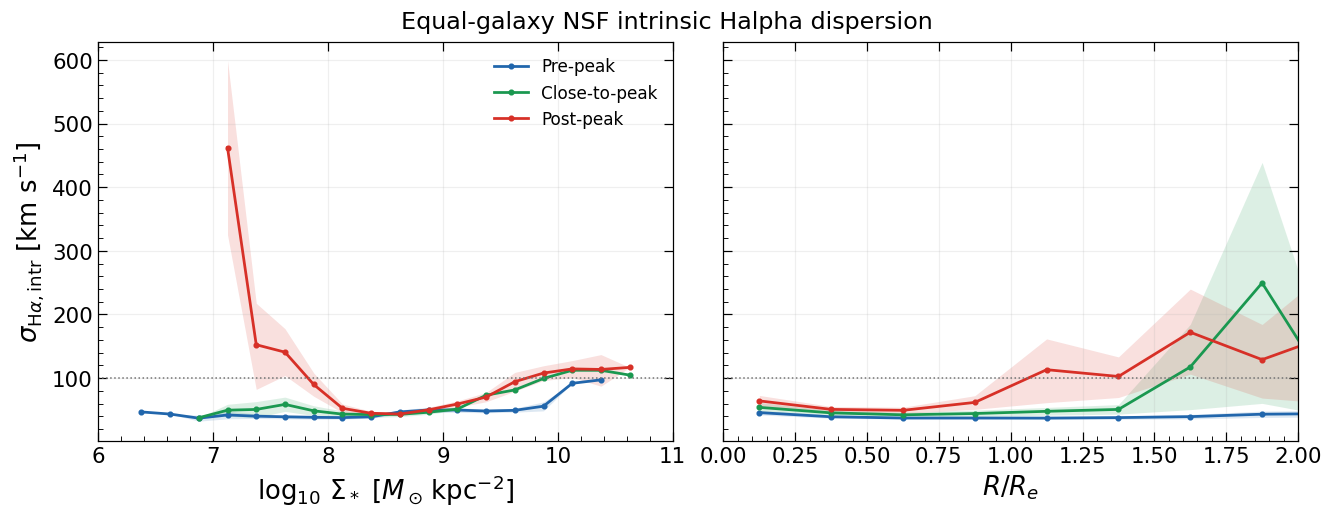

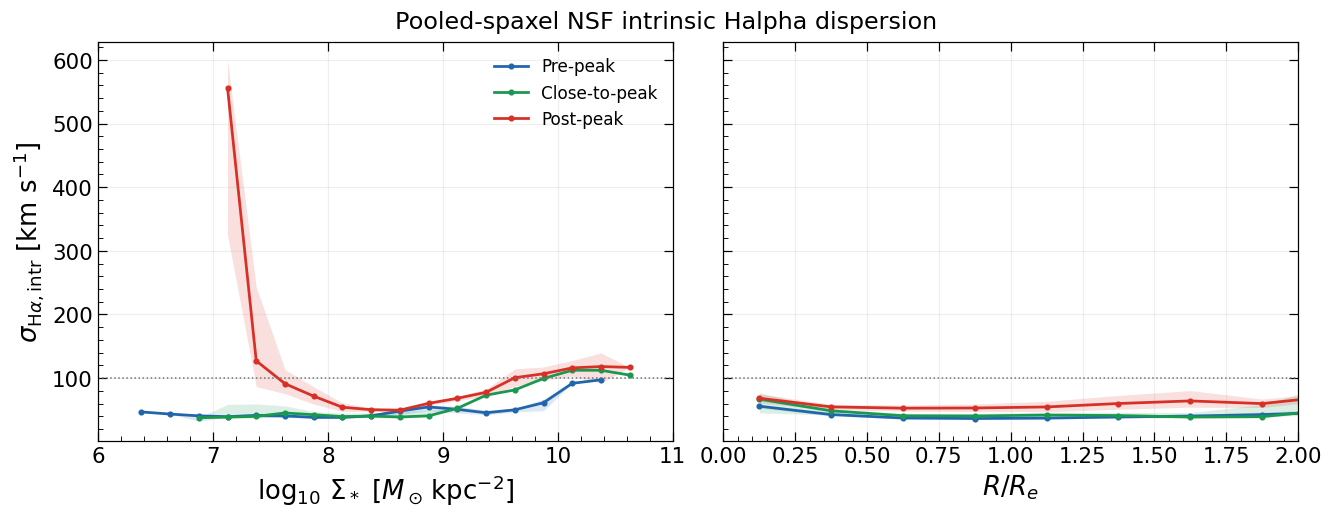

In [5]:
fraction_labels = {
    'log_sigma_star': r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]',
    'radius_re': r'$R/R_e$',
}
for branch in ('equal_galaxy', 'pooled_spaxel'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout='constrained')
    for ax, variable in zip(axes, ('log_sigma_star', 'radius_re')):
        for stage in (1, 2, 3):
            p = nsf_extra_profiles.loc[nsf_extra_profiles.branch.eq(branch) &
                nsf_extra_profiles.stage.eq(stage) & nsf_extra_profiles.variable.eq(variable)].sort_values('center')
            ax.plot(p.center, p.value, color=STAGE_COLORS[stage], marker='o', ms=3,
                lw=1.8, label=STAGE_LABELS[stage])
            ax.fill_between(p.center.to_numpy(float), p.lo.to_numpy(float), p.hi.to_numpy(float),
                color=STAGE_COLORS[stage], alpha=0.15, linewidth=0)
        ax.axhline(HIGH_SIGMA_LIMIT, color='0.45', ls=':', lw=1)
        ax.set_xlim(PROFILE_X_LIMITS[variable])  # display only; full-range statistics retained
        ax.set_xlabel(fraction_labels[variable])
        ax.tick_params(top=True, right=True)
        ax.minorticks_on(); ax.grid(alpha=0.2)
    axes[0].set_ylabel(r'$\sigma_{\mathrm{H}\alpha,\mathrm{intr}}$ [km s$^{-1}$]')
    axes[0].legend(frameon=False)
    label = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
    fig.suptitle(label + ' NSF intrinsic Halpha dispersion')
    save_figure(fig, 'NSF_intrinsic_Halpha_dispersion_' + branch)
    plt.show(); plt.close(fig)

## Post-peak bounded spatial selections and >100 km/s counts
Use finite NSF dispersion pixels with **7.5 <= log10 Sigma_star <8** or
**1 < R/R_e <=1.5**, separately. No galaxy/bin support gate is applied to these
spatial masks. The two panels may contain the same pixel; their counts must not
be added as disjoint populations.

In [6]:
summary_rows, high_pixel_rows = [], []
for gal, maps in post_peak_maps.items():
    base = maps['selected']
    masks = dispersion_region_masks(maps['mass'], maps['radius'], base)
    maps['panel_masks'] = masks
    maps['union'] = np.logical_or.reduce(list(masks.values()))
    assert not np.any(maps['union'] & ~base)
    for selection, mask in masks.items():
        values = maps['sigma'][mask]
        high = mask & (maps['sigma'] > HIGH_SIGMA_LIMIT)
        summary_rows.append(dict(galaxy=gal, selection=selection, N=int(mask.sum()),
            N_gt100=int(high.sum()), fraction_gt100=float(high.sum()/mask.sum()) if mask.any() else np.nan,
            median_sigma=float(np.median(values)) if values.size else np.nan,
            max_sigma=float(values.max()) if values.size else np.nan))
    high_union = maps['union'] & (maps['sigma'] > HIGH_SIGMA_LIMIT)
    yy, xx = np.where(high_union)
    ra, dec = WCS(maps['header']).celestial.pixel_to_world_values(xx, yy)
    for y, x, r, d in zip(yy, xx, ra, dec):
        high_pixel_rows.append(dict(galaxy=gal, x=int(x), y=int(y), ra_deg=float(r), dec_deg=float(d),
            log_sigma_star=float(maps['mass'][y, x]), radius_re=float(maps['radius'][y, x]),
            sigma_kms=float(maps['sigma'][y, x]),
            low_mass=bool(masks['logSigmaStar_7p5_to_8'][y, x]), outer=bool(masks['R_over_Re_1_to_1p5'][y, x])))
selection_summary = pd.DataFrame(summary_rows)
high_sigma_pixels = pd.DataFrame(high_pixel_rows, columns=['galaxy', 'x', 'y', 'ra_deg', 'dec_deg',
    'log_sigma_star', 'radius_re', 'sigma_kms', 'low_mass', 'outer'])
high_sigma_pixels = high_sigma_pixels.sort_values('sigma_kms', ascending=False).reset_index(drop=True)
display(selection_summary)
print('Unique selected post-peak pixels >100 km/s:', len(high_sigma_pixels))
display(high_sigma_pixels.head(30))

,galaxy,selection,N,N_gt100,fraction_gt100,median_sigma,max_sigma
0,IC3392,logSigmaStar_7p5_to_8,2158,254,0.117702,43.486295,330.281875
1,IC3392,R_over_Re_1_to_1p5,1996,95,0.047595,47.434987,330.281875
2,NGC4064,logSigmaStar_7p5_to_8,9669,1007,0.104147,63.935388,244.165602
3,NGC4064,R_over_Re_1_to_1p5,1130,318,0.281416,67.888709,325.219883
4,NGC4293,logSigmaStar_7p5_to_8,5468,3506,0.641185,153.854266,1000.000000
5,NGC4293,R_over_Re_1_to_1p5,4511,2810,0.622922,144.191184,1000.000000
6,NGC4380,logSigmaStar_7p5_to_8,19423,38,0.001956,26.235919,129.206086
7,NGC4380,R_over_Re_1_to_1p5,6892,98,0.014219,26.679016,194.850923
8,NGC4394,logSigmaStar_7p5_to_8,8977,0,0.000000,28.394661,65.712347
9,NGC4394,R_over_Re_1_to_1p5,6373,0,0.000000,27.696872,80.161302


Unique selected post-peak pixels >100 km/s: 26628


,galaxy,x,y,ra_deg,dec_deg,log_sigma_star,radius_re,sigma_kms,low_mass,outer
0,NGC4293,844,137,185.281370,18.375784,8.049689,1.129762,1000.0,False,True
1,NGC4293,805,174,185.283653,18.377840,8.329736,1.054748,1000.0,False,True
2,NGC4293,885,194,185.278969,18.378950,7.822846,1.388992,1000.0,True,True
3,NGC4293,884,194,185.279028,18.378950,7.822846,1.385330,1000.0,True,True
4,NGC4293,889,193,185.278735,18.378894,7.822846,1.401085,1000.0,True,True
5,NGC4293,888,193,185.278794,18.378894,7.822846,1.397424,1000.0,True,True
6,NGC4293,887,193,185.278852,18.378894,7.822846,1.393764,1000.0,True,True
7,NGC4293,809,93,185.283420,18.373340,7.878388,0.992182,1000.0,True,False
8,NGC4293,808,93,185.283478,18.373340,7.878388,0.989378,1000.0,True,False
9,NGC4293,807,93,185.283537,18.373340,7.878388,0.986580,1000.0,True,False


All maps share 0-1025 km/s; no selected values exceed the colour range.


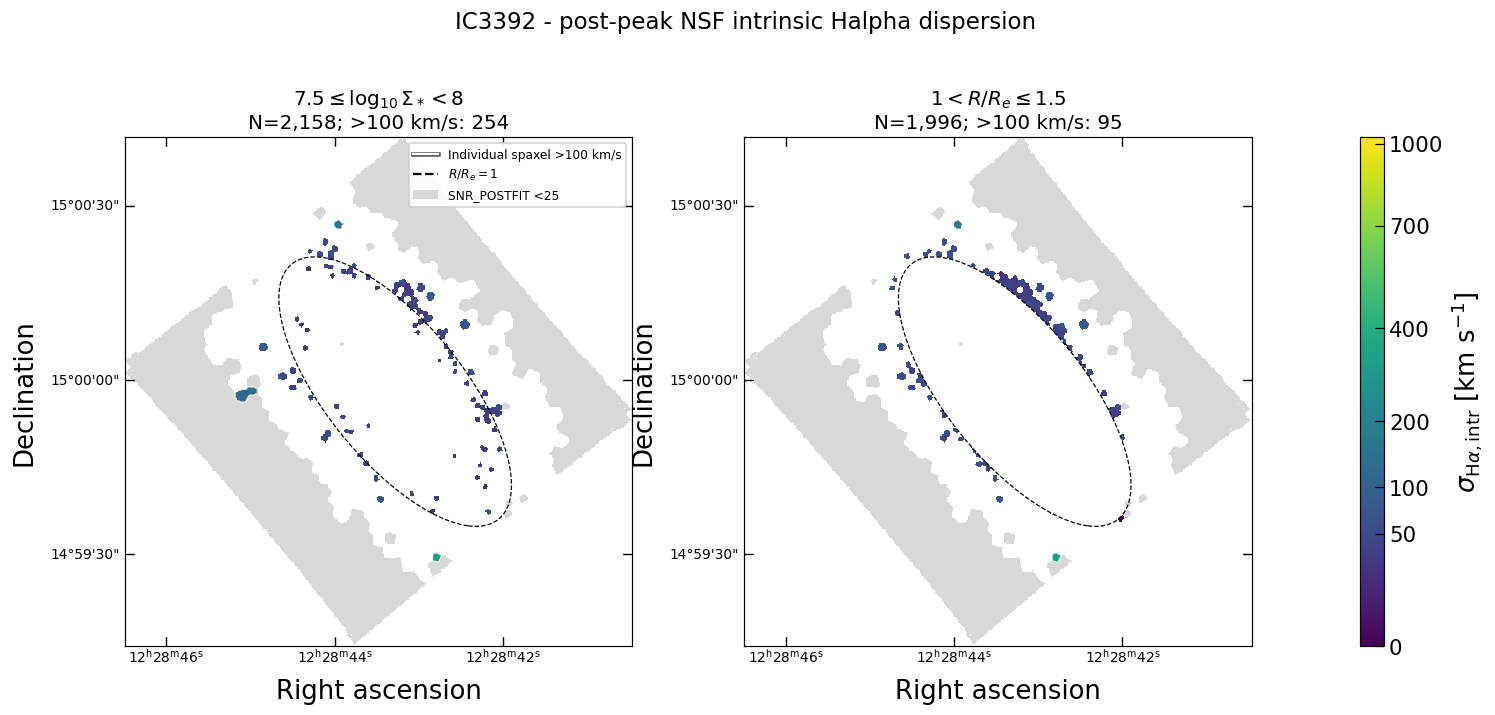

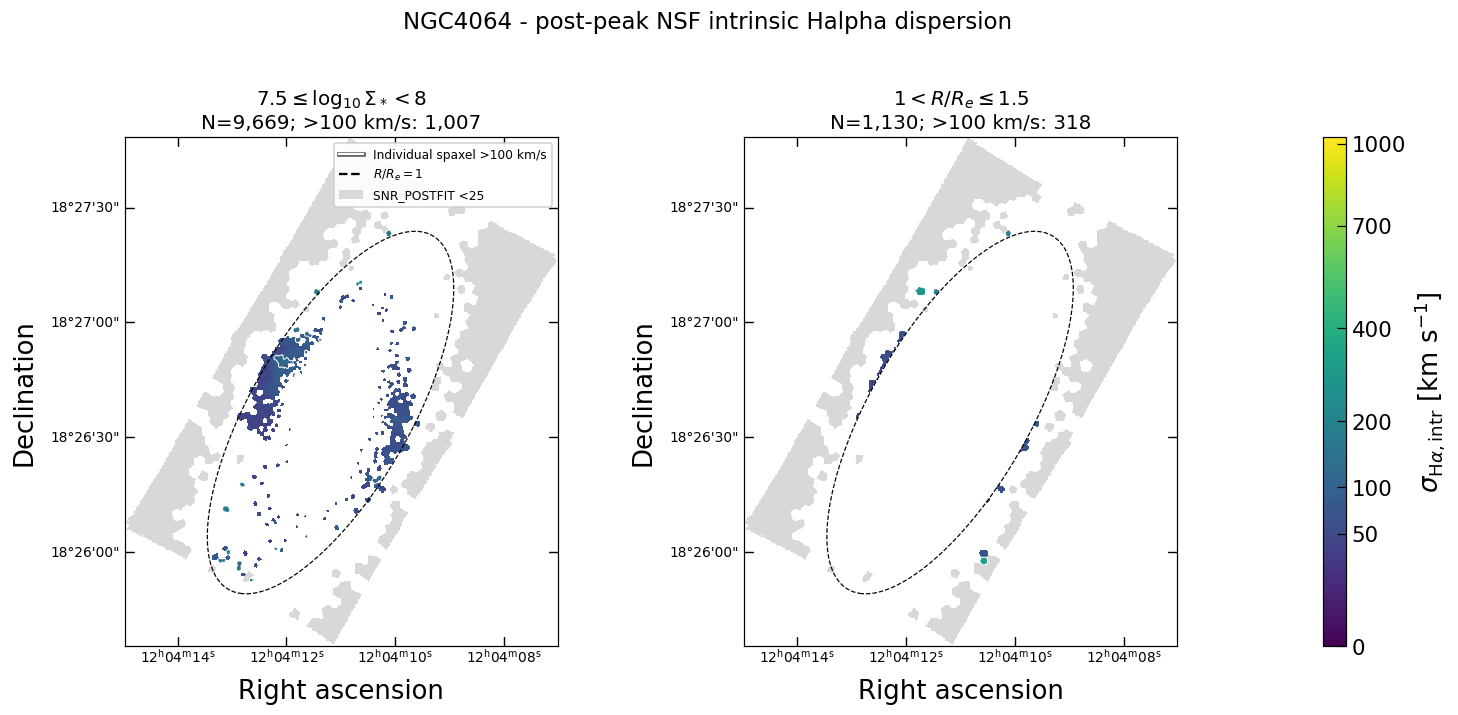

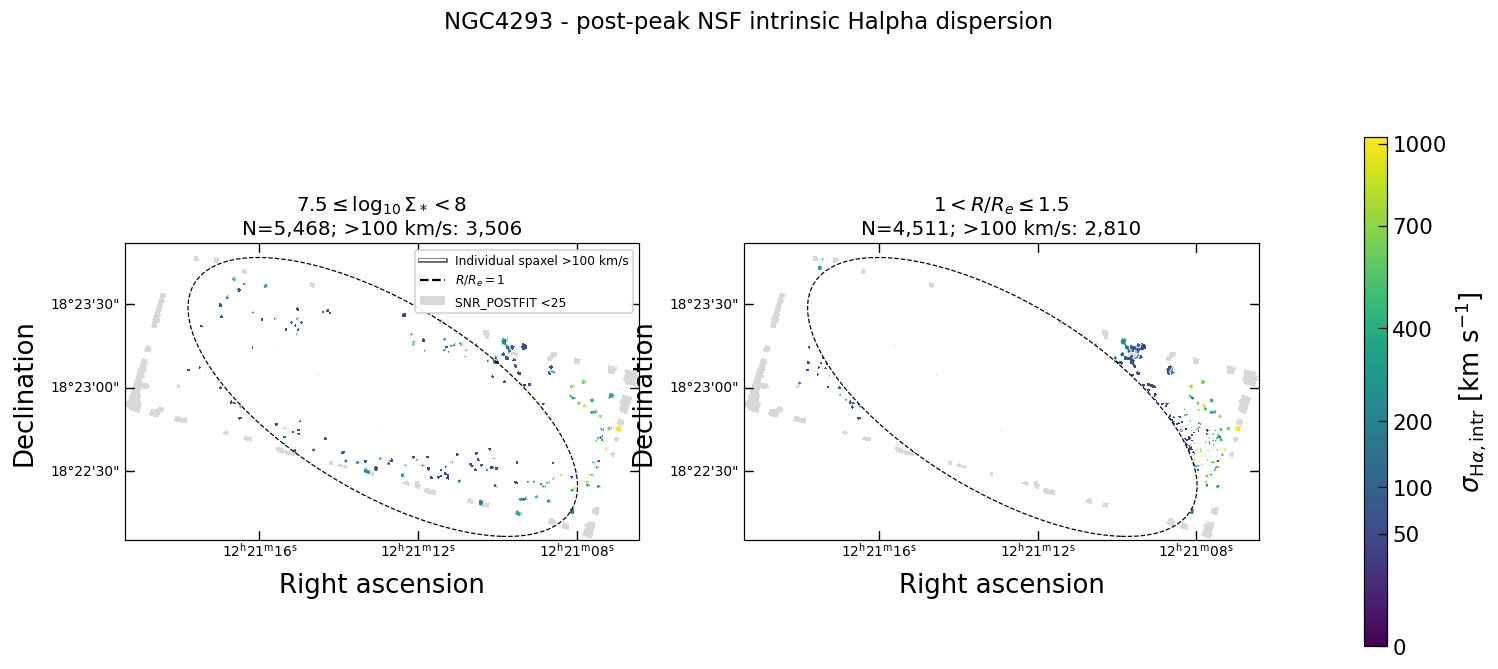

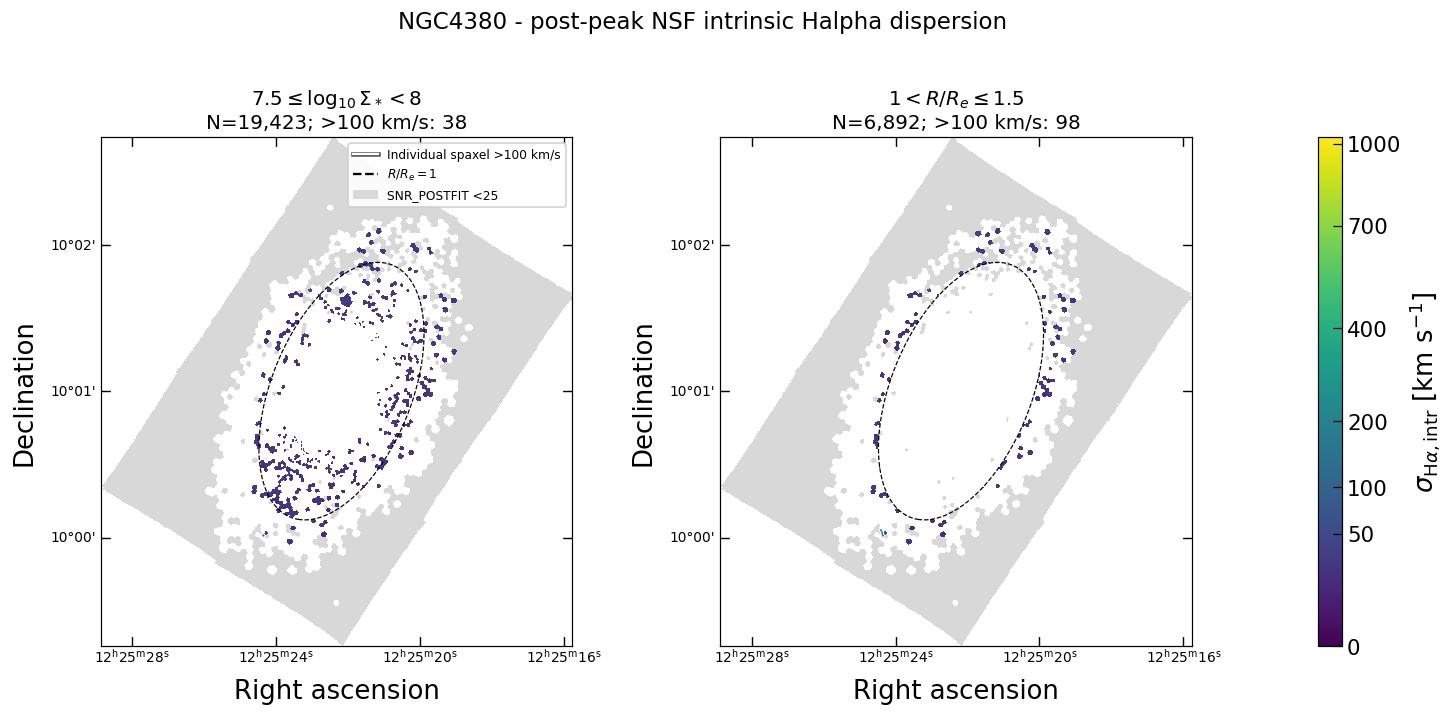

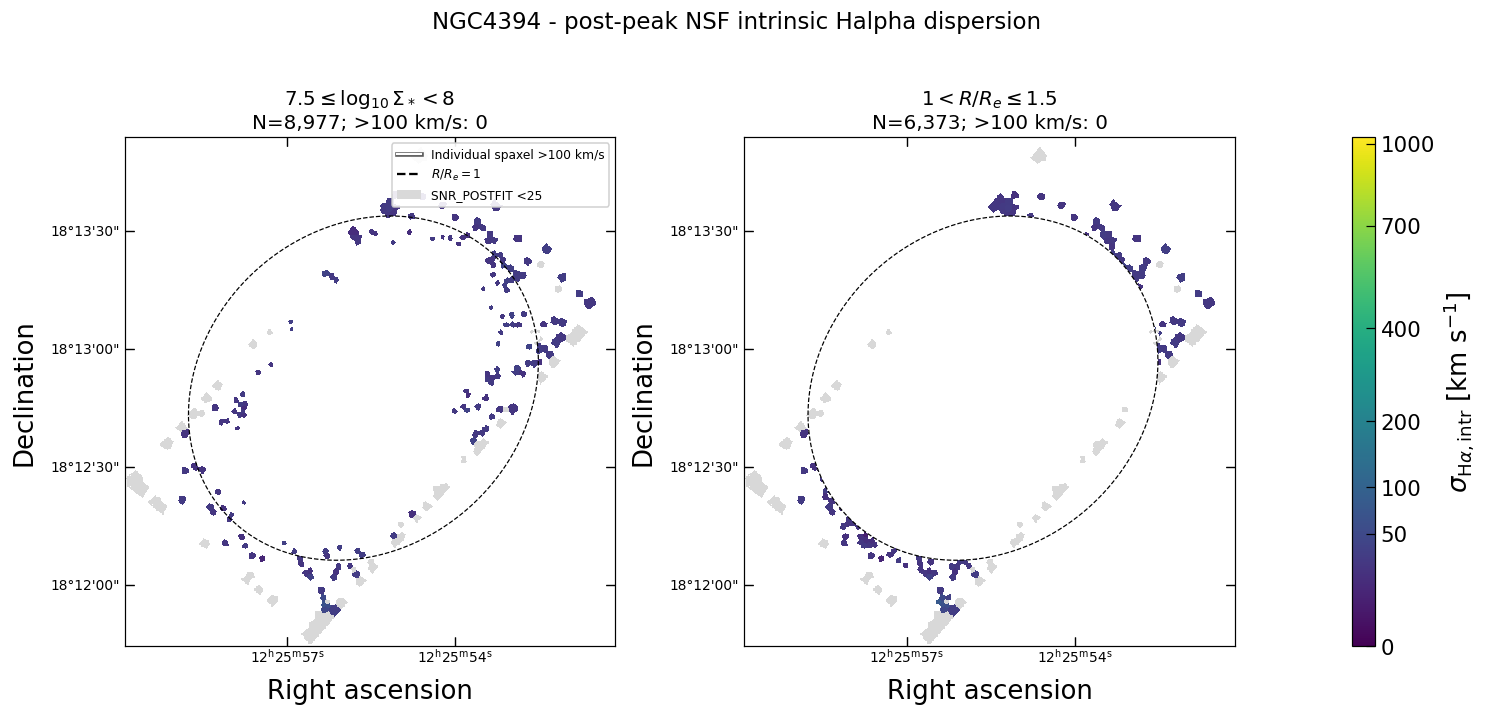

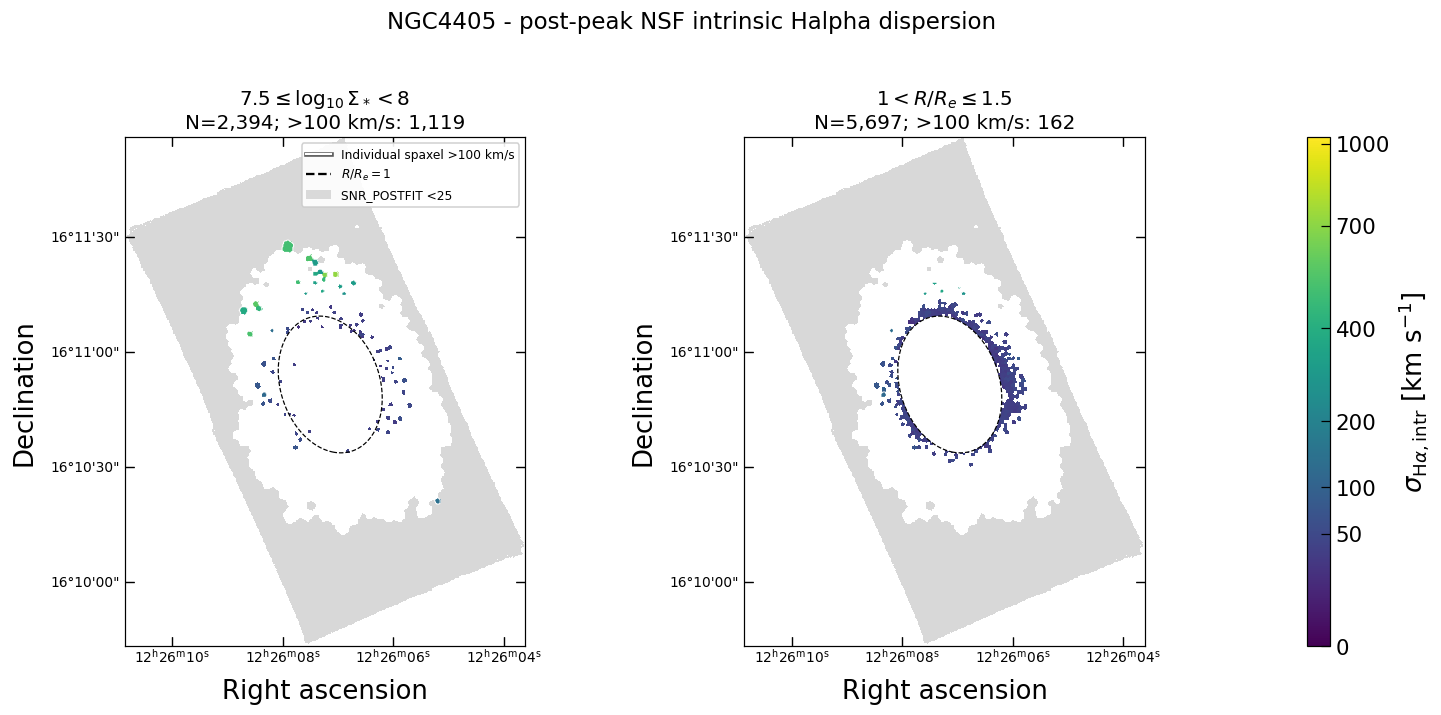

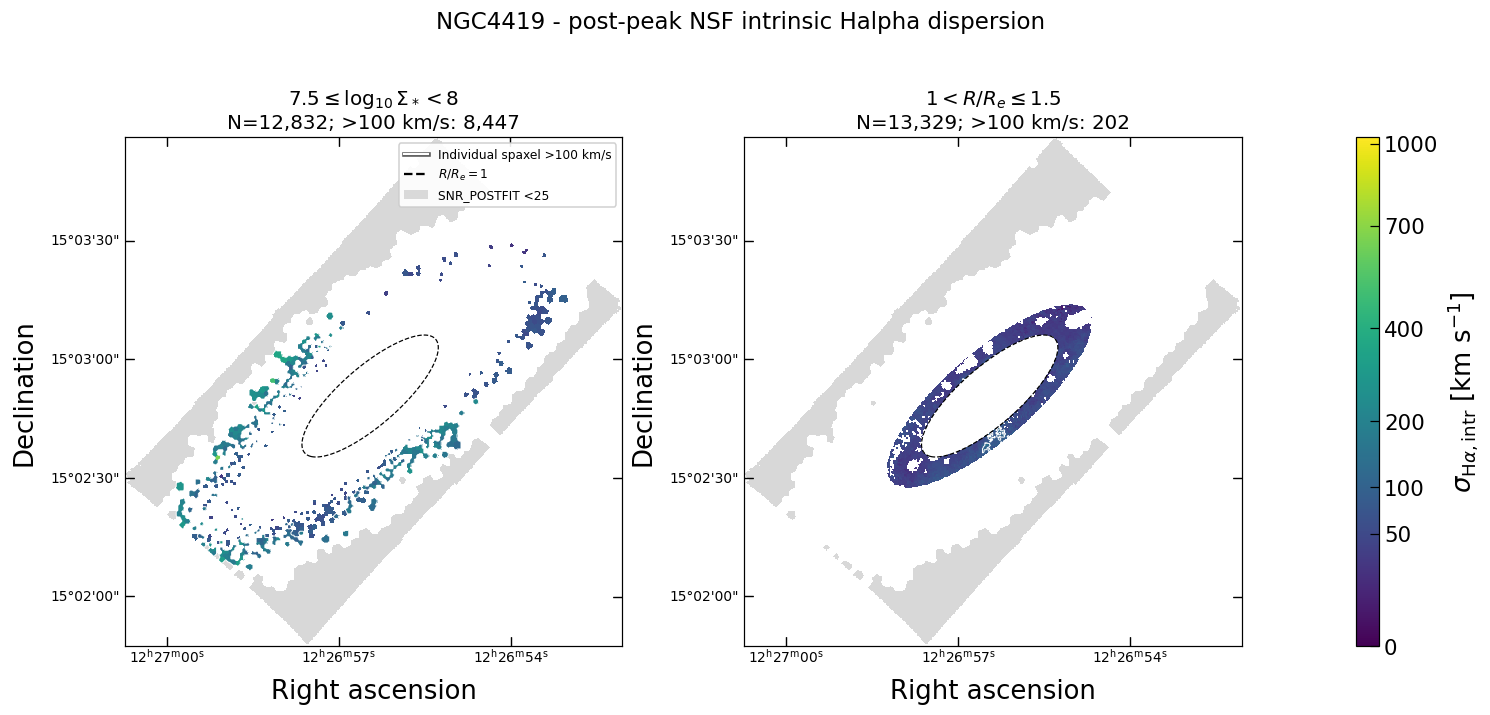

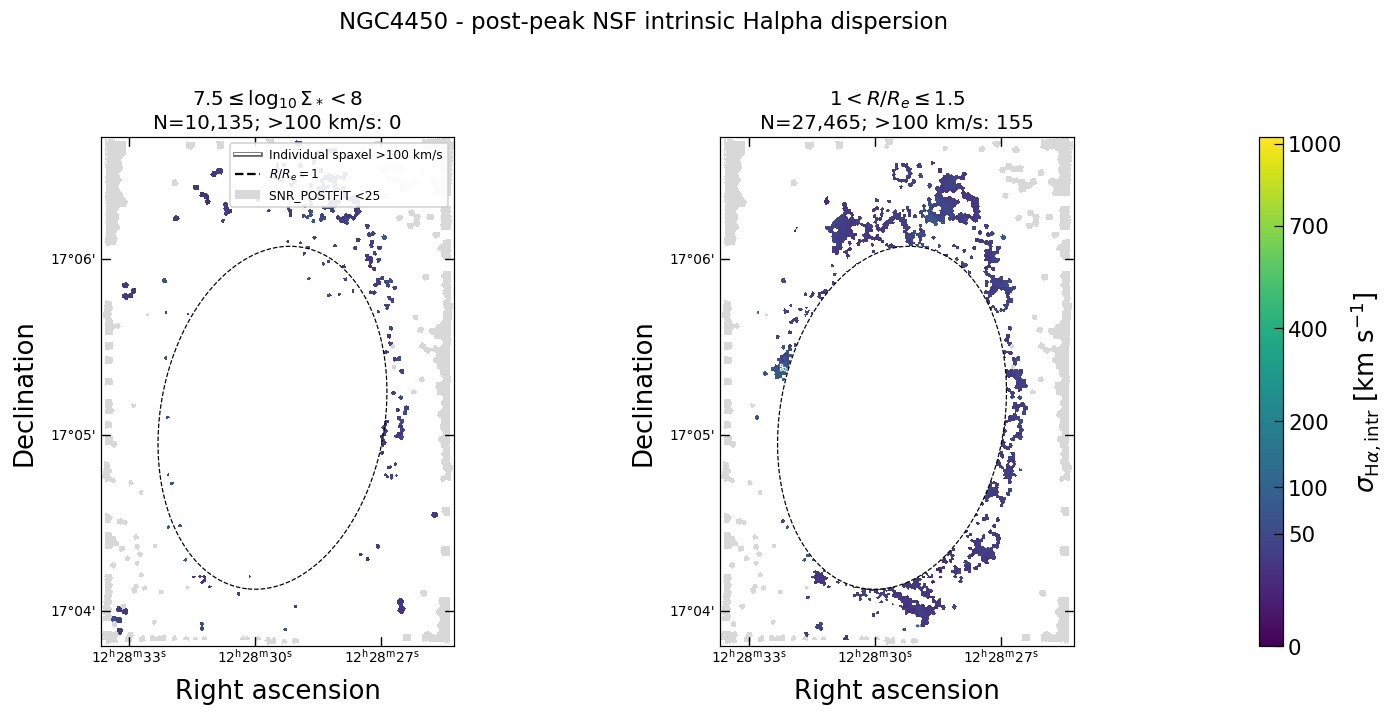

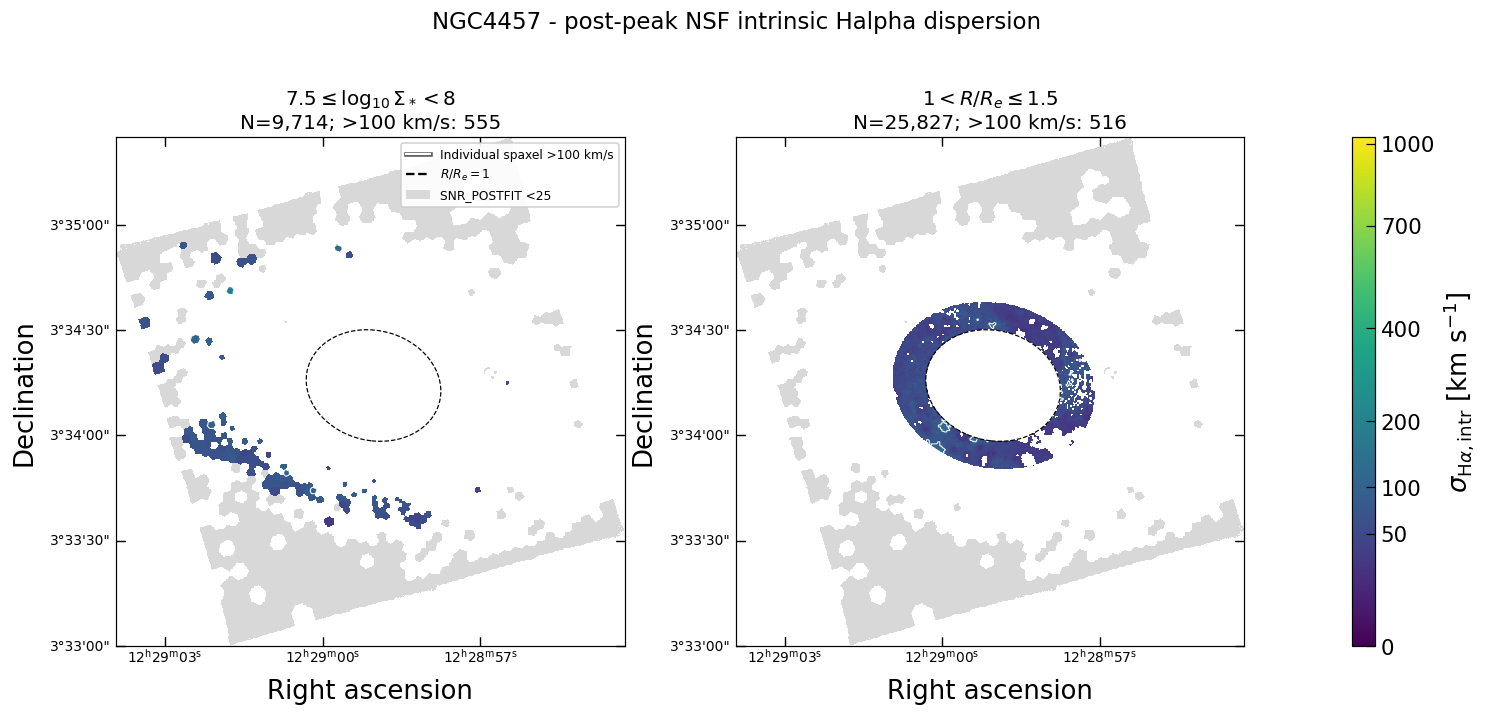

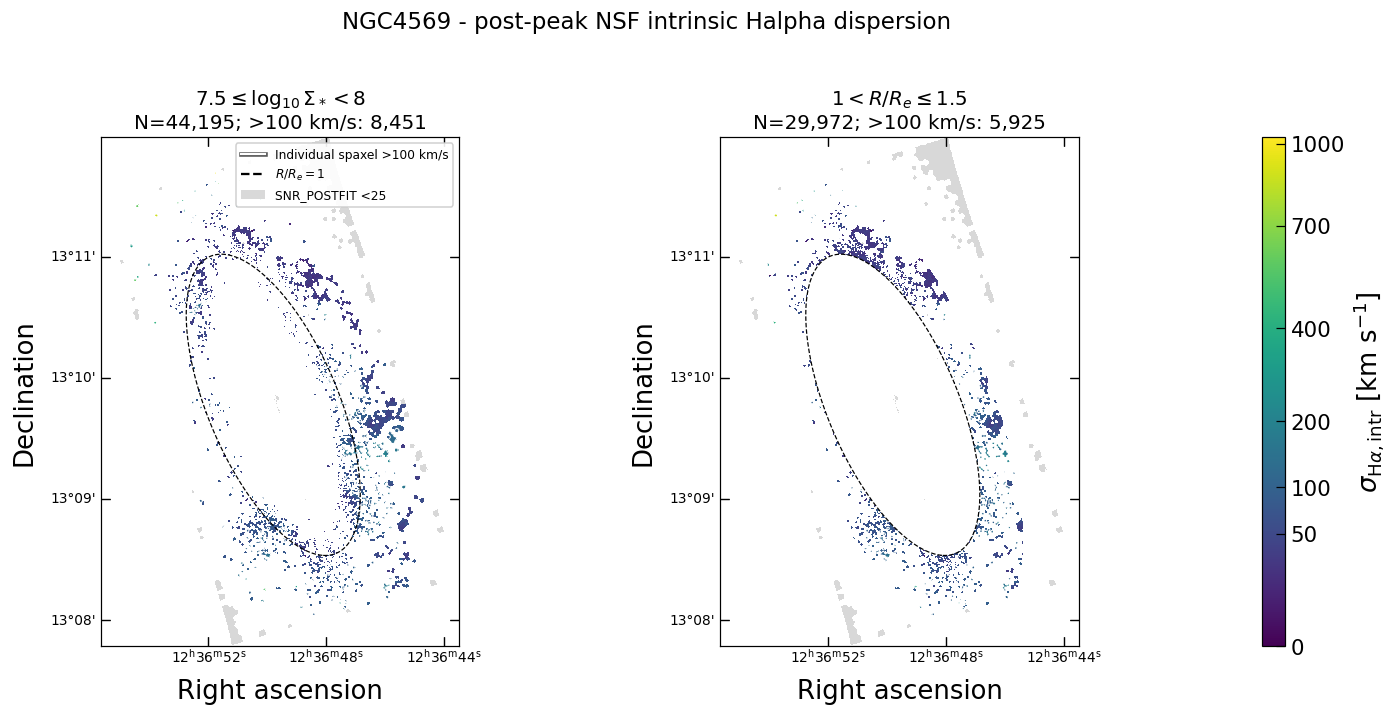

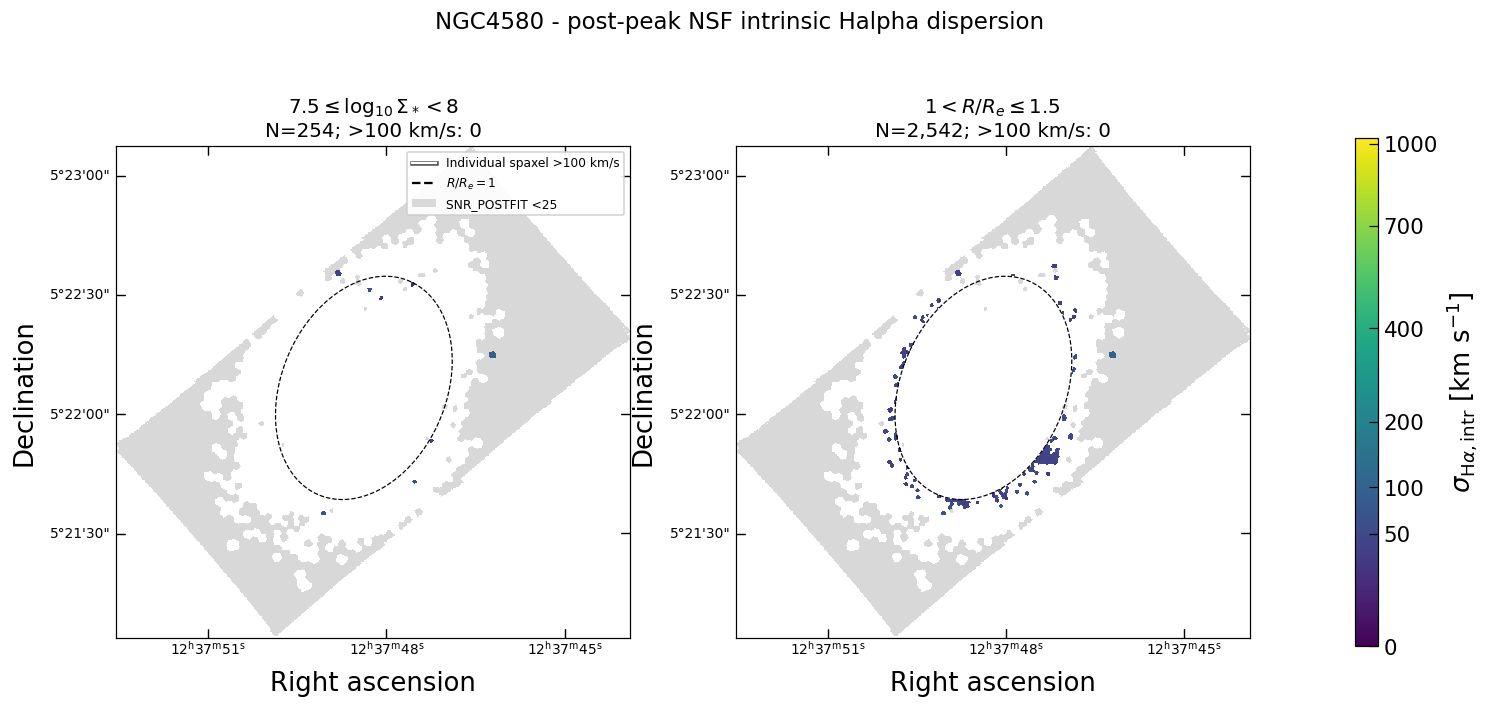

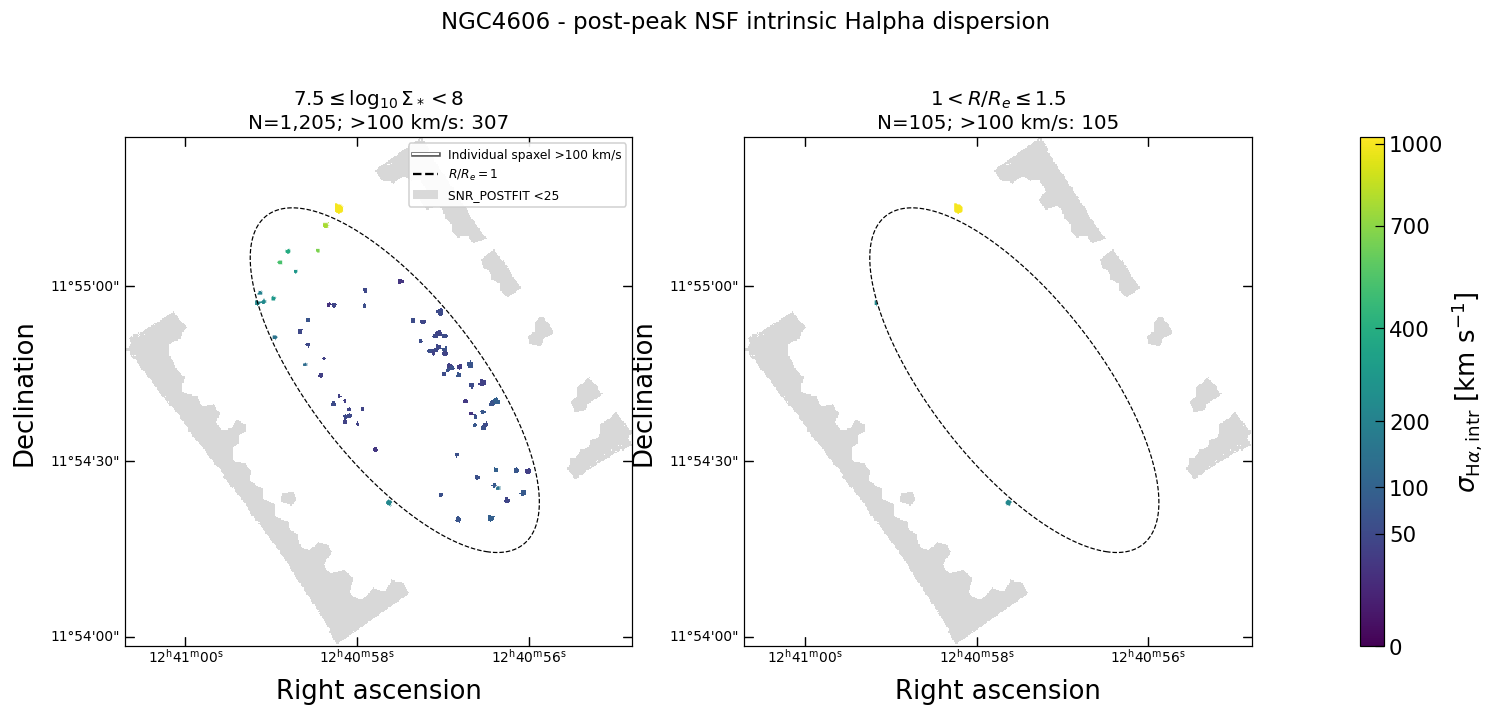

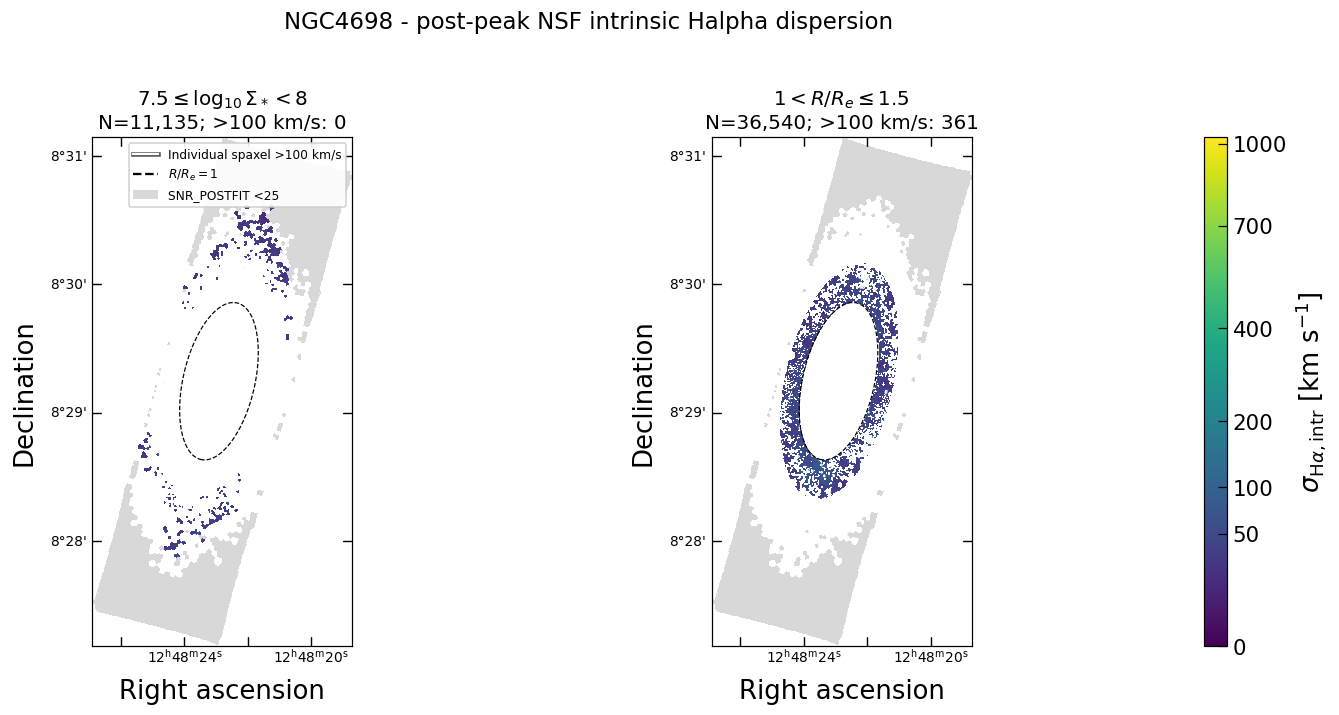

In [7]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
selected_maxima = [m['sigma'][m['union']].max() for m in post_peak_maps.values() if m['union'].any()]
MAP_VMAX = max(150.0, 25.0 * np.ceil(max(selected_maxima, default=150.0)/25.0))
norm = PowerNorm(gamma=0.5, vmin=0, vmax=MAP_VMAX)
cmap = plt.get_cmap('viridis').copy()
cmap.set_bad((1.0, 1.0, 1.0, 0.0))  # reveal the SNR background
print(f'All maps share 0-{MAP_VMAX:g} km/s; no selected values exceed the colour range.')
for gal, maps in post_peak_maps.items():
    fig = plt.figure(figsize=(13.5, 6.8))
    grid = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.045],
        left=0.08, right=0.93, bottom=0.13, top=0.81, wspace=0.30)
    axes = [fig.add_subplot(grid[0, j], projection=WCS(maps['header']).celestial) for j in range(2)]
    cax = fig.add_subplot(grid[0, 2])
    for ax, (selection, mask), title in zip(axes, maps['panel_masks'].items(),
            (r'$7.5 \leq \log_{10}\Sigma_* < 8$', r'$1 < R/R_e \leq 1.5$')):
        background = np.ones(mask.shape + (4,), dtype=float)
        background[maps['low_snr'], :3] = 0.85
        ax.imshow(background, origin='lower', interpolation='nearest', rasterized=True)
        image = ax.imshow(np.ma.array(maps['sigma'], mask=~mask), origin='lower',
            cmap=cmap, norm=norm, interpolation='nearest', rasterized=True)
        high = mask & (maps['sigma'] > HIGH_SIGMA_LIMIT)
        # Pad the footprint so even a selected boundary pixel receives a closed outline.
        if high.any():
            ax.contour(np.pad(high.astype(float), 1), levels=[0.5], colors='white',
                linewidths=0.65, origin='lower', extent=(-1.5, high.shape[1]+0.5, -1.5, high.shape[0]+0.5))
        radius = maps['radius']
        if np.nanmin(radius) < 1 < np.nanmax(radius):
            ax.contour(radius, levels=[1.0], colors='black', linestyles='--', linewidths=0.8)
        ax.set_xlim(-0.5, mask.shape[1]-0.5); ax.set_ylim(-0.5, mask.shape[0]-0.5)
        ax.set_title(title + f'\nN={mask.sum():,}; >100 km/s: {high.sum():,}', fontsize=13)
        ax.coords[0].set_axislabel('Right ascension')
        ax.coords[1].set_axislabel('Declination')
        ax.coords[0].set_major_formatter('hh:mm:ss')
        ax.coords[0].set_ticks(number=4); ax.coords[1].set_ticks(number=4)
        ax.coords[0].set_ticklabel(size=9, simplify=False, exclude_overlapping=True)
        ax.coords[1].set_ticklabel(size=9, simplify=False, exclude_overlapping=True)
        if not mask.any():
            ax.text(0.5, 0.5, 'No selected NSF spaxels', transform=ax.transAxes, ha='center')
    colorbar = fig.colorbar(image, cax=cax, ticks=[0, 50, 100, 200, 400, 700, 1000])
    colorbar.set_label(r'$\sigma_{\mathrm{H}\alpha,\mathrm{intr}}$ [km s$^{-1}$]')
    # Black backing makes the white high-sigma key visible on the white legend surface.
    import matplotlib.patheffects as pe
    key = Line2D([], [], color='white', lw=1.4,
        path_effects=[pe.Stroke(linewidth=3, foreground='0.35'), pe.Normal()])
    axes[0].legend([key, Line2D([], [], color='black', ls='--'),
        Patch(facecolor='0.85', edgecolor='none')],
        ['Individual spaxel >100 km/s', r'$R/R_e=1$', 'SNR_POSTFIT <25'], loc='upper right', fontsize=8, framealpha=0.9)
    fig.suptitle(gal + ' - post-peak NSF intrinsic Halpha dispersion', fontsize=15, y=0.98)
    save_figure(fig, gal + '_NSF_low_mass_outer_intrinsic_Halpha_dispersion')
    plt.show(); plt.close(fig)

## Normalized dispersion distributions for individual post-peak galaxies

Each galaxy has one figure overlaying its two spatial selections: **7.5 <= log10 Sigma_star <8**
and **1 < R/R_e <=1.5**, using exactly the finite NSF dispersion pixels in the maps.
Each selection is normalized separately to a probability density with unit area
(`sum(density * bin_width) = 1`), so curves compare shapes rather than pixel counts.
All galaxies and both selections share linear 10 km/s bins from zero through the
largest selected dispersion; the complete high-dispersion tail is retained.
The selections overlap and are not independent samples. Legends give the selected
pixel counts and fractions strictly above 100 km/s. Vertical coloured dashed lines
show the individual medians; the grey dotted line marks 100 km/s.
No smoothing, clipping, galaxy weighting or bin-support cut is added.

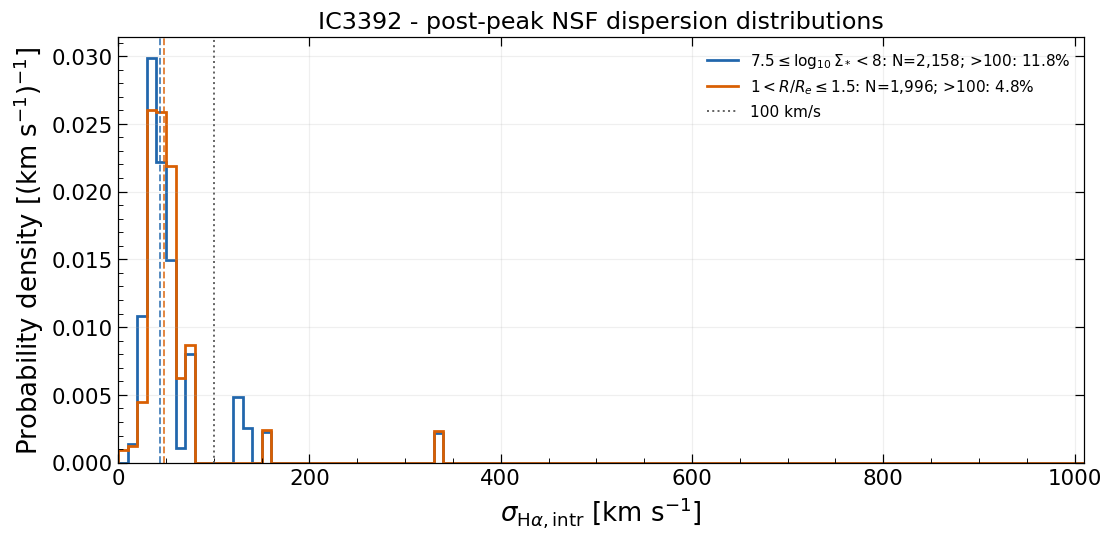

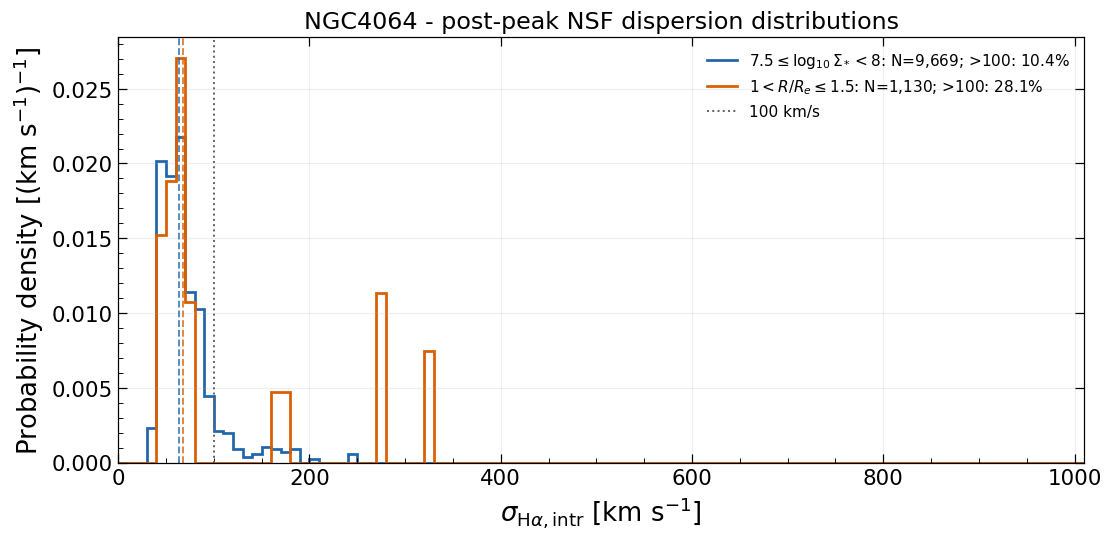

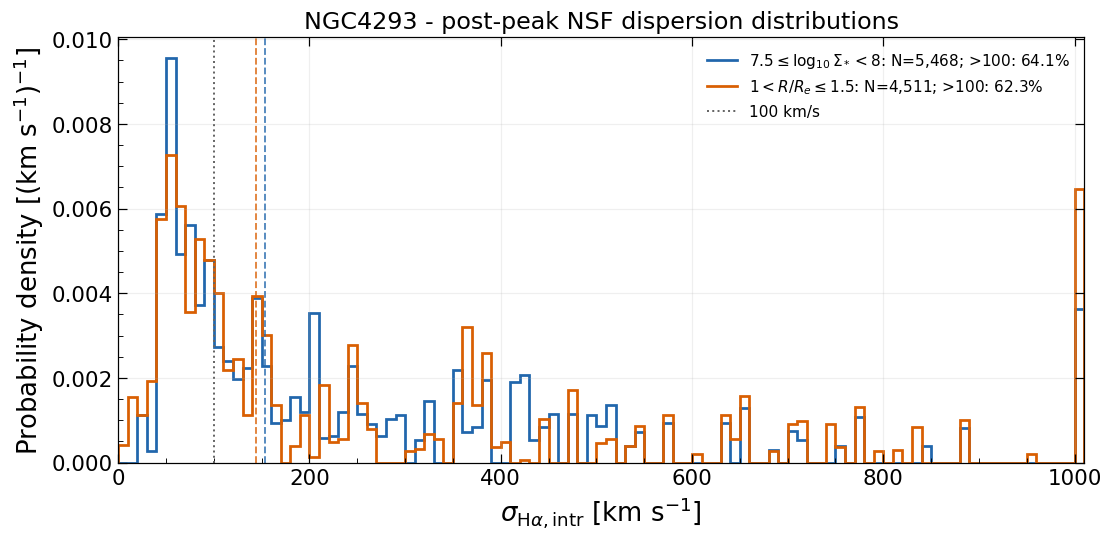

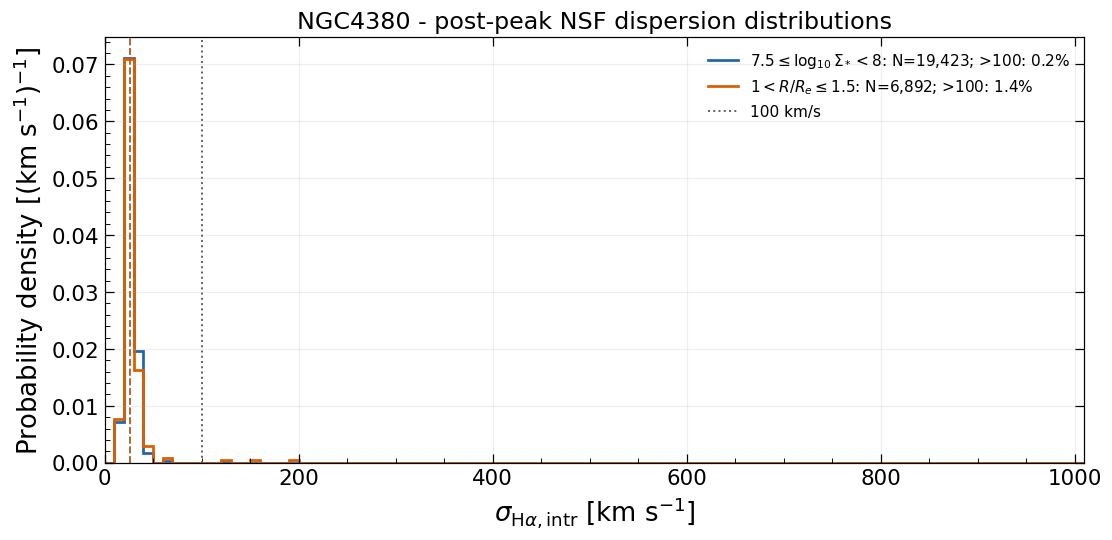

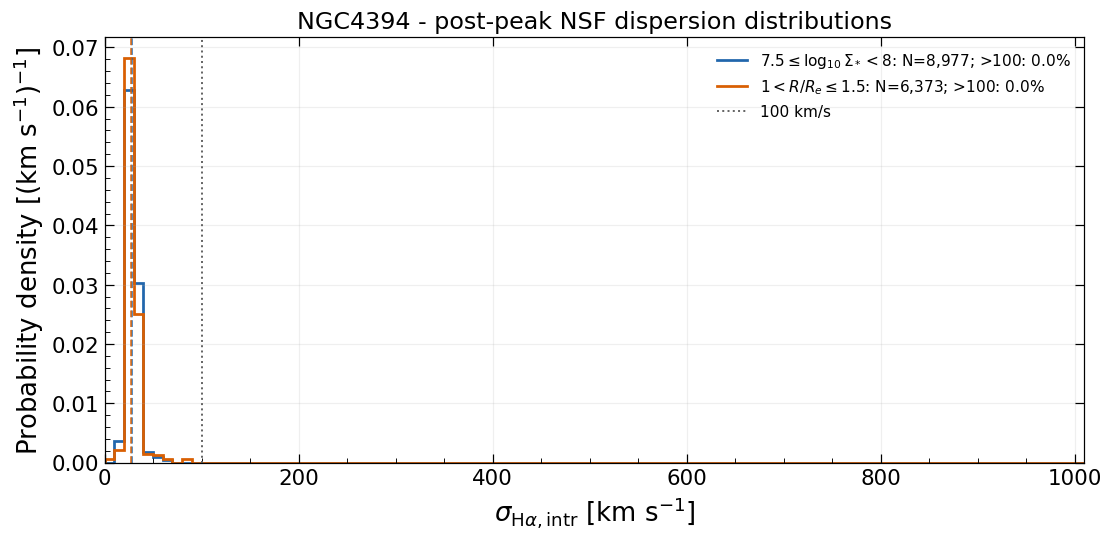

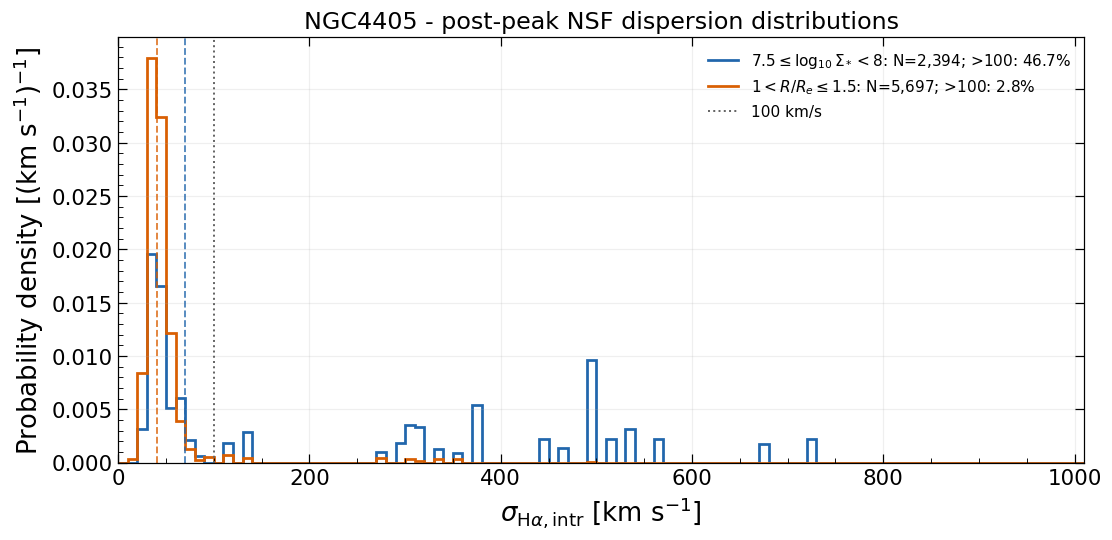

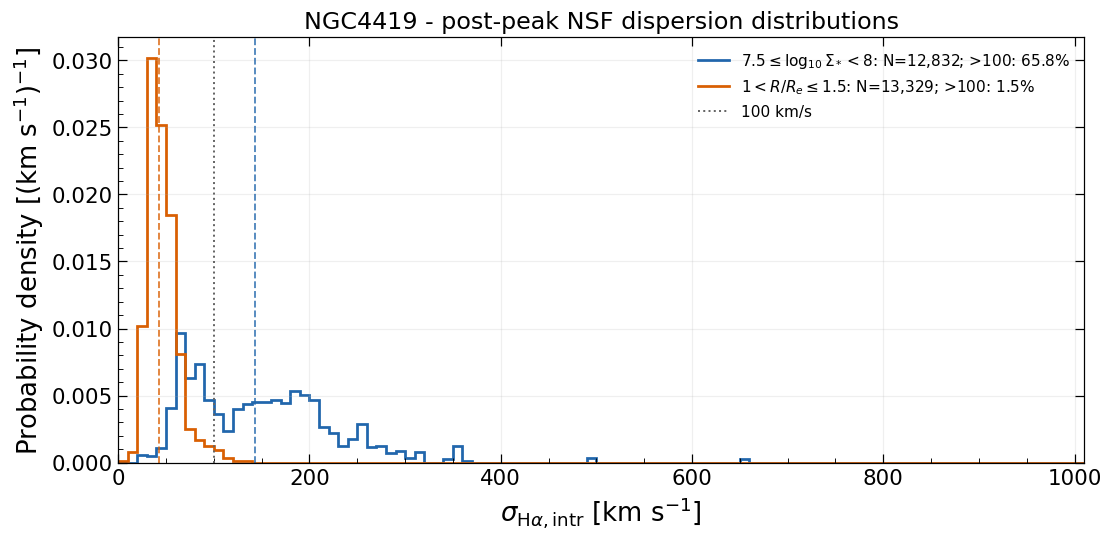

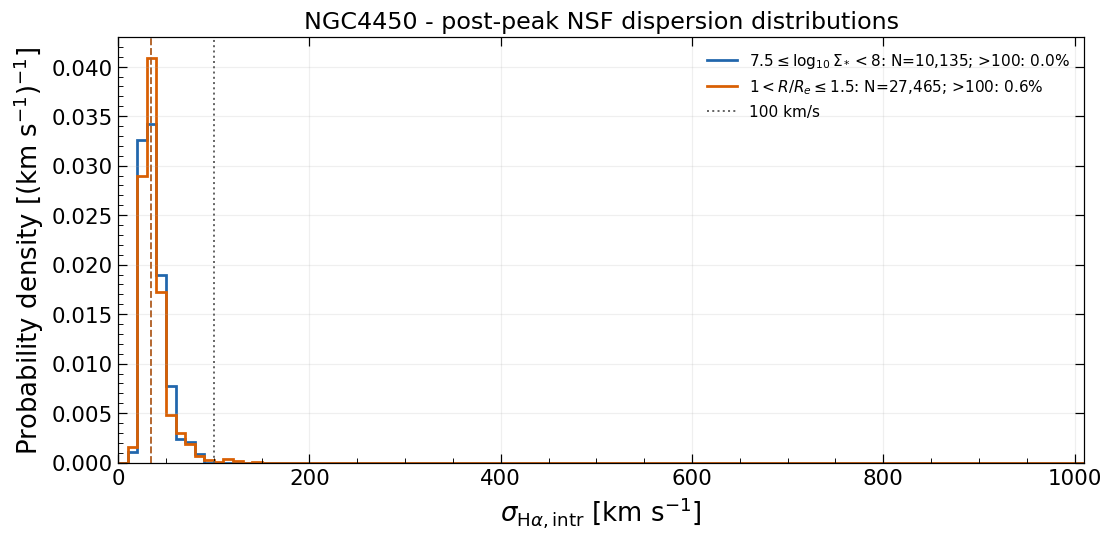

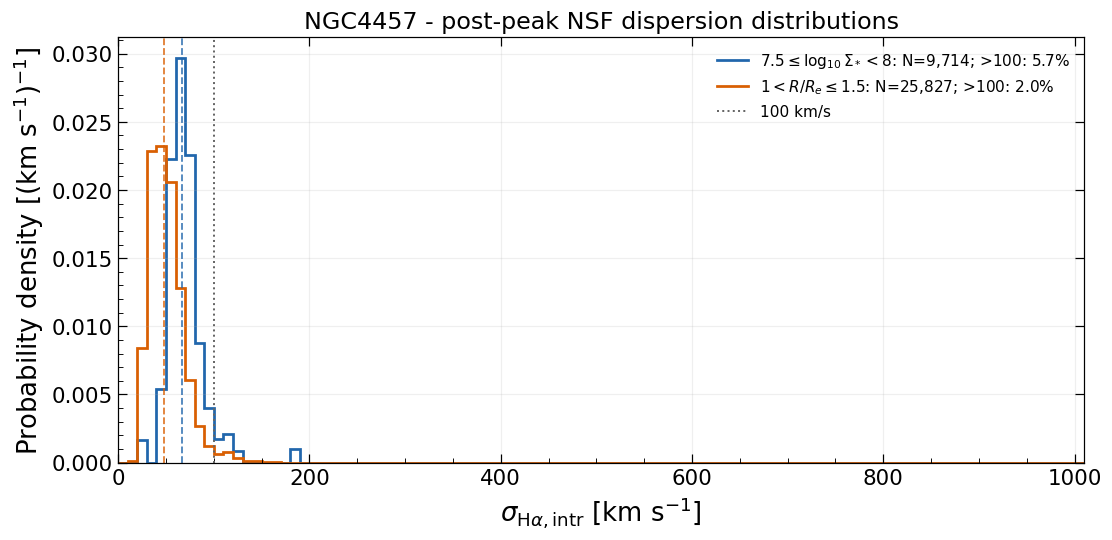

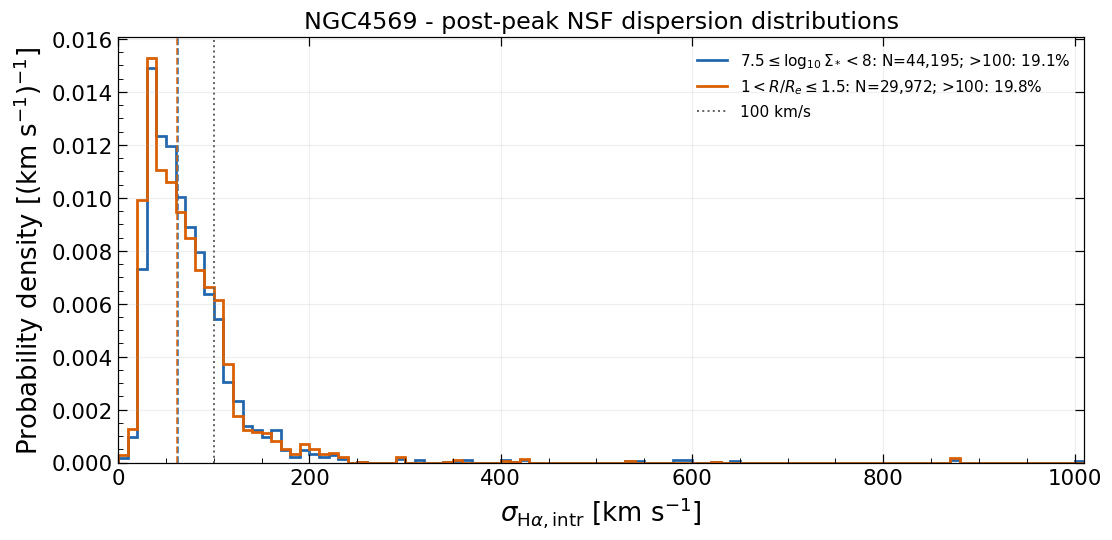

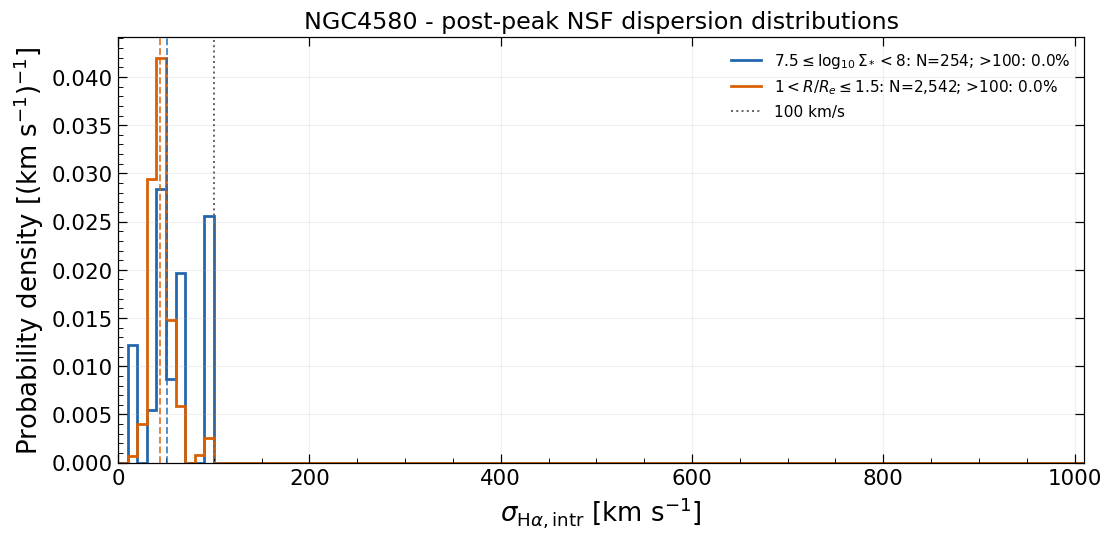

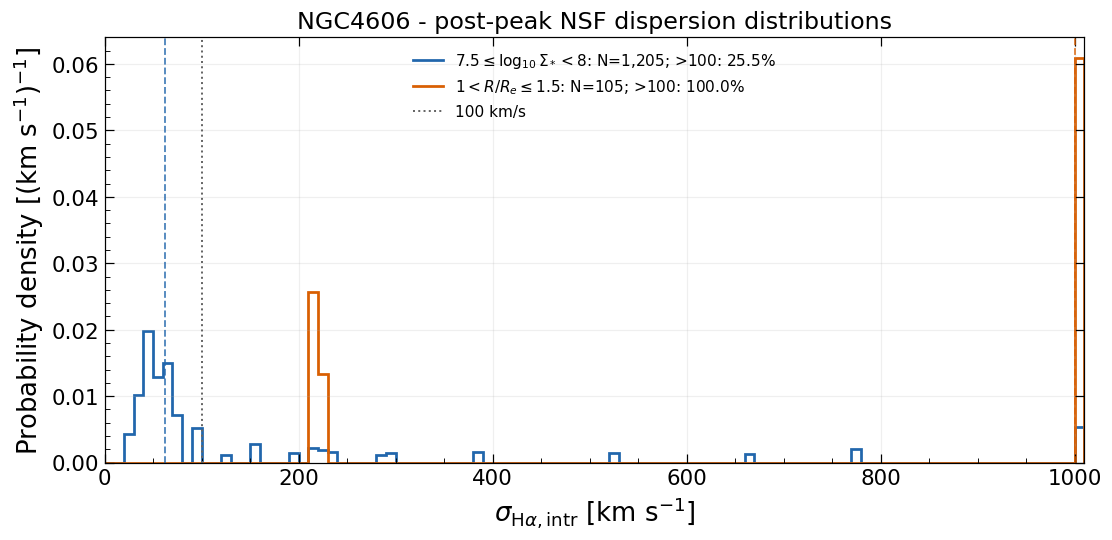

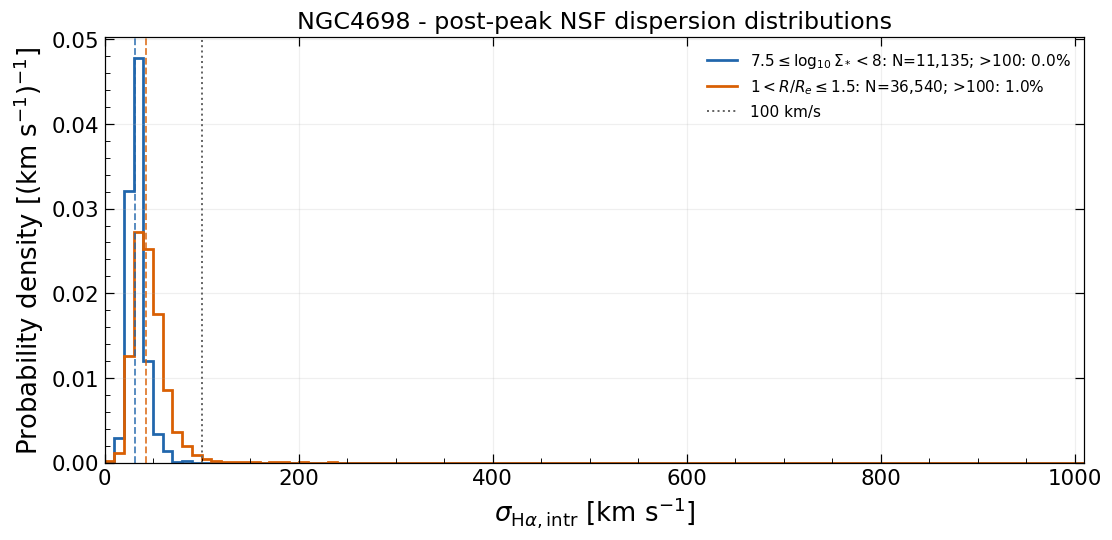

,galaxy,selection,N,density_integral,median_sigma,fraction_gt100
0,IC3392,logSigmaStar_7p5_to_8,2158,1.0,43.486295,0.117702
1,IC3392,R_over_Re_1_to_1p5,1996,1.0,47.434987,0.047595
2,NGC4064,logSigmaStar_7p5_to_8,9669,1.0,63.935388,0.104147
3,NGC4064,R_over_Re_1_to_1p5,1130,1.0,67.888709,0.281416
4,NGC4293,logSigmaStar_7p5_to_8,5468,1.0,153.854266,0.641185
5,NGC4293,R_over_Re_1_to_1p5,4511,1.0,144.191184,0.622922
6,NGC4380,logSigmaStar_7p5_to_8,19423,1.0,26.235919,0.001956
7,NGC4380,R_over_Re_1_to_1p5,6892,1.0,26.679016,0.014219
8,NGC4394,logSigmaStar_7p5_to_8,8977,1.0,28.394661,0.000000
9,NGC4394,R_over_Re_1_to_1p5,6373,1.0,27.696872,0.000000


Every nonempty distribution integrates to one; counts, medians and >100 fractions match the maps.


In [8]:
DISTRIBUTION_BIN_WIDTH = 10.0  # km/s; shared by every galaxy and selection
distribution_max = max(
    (m['sigma'][m['union']].max() for m in post_peak_maps.values() if m['union'].any()),
    default=DISTRIBUTION_BIN_WIDTH,
)
# Include the maximum in the final bin even if floating point puts it just over an edge.
distribution_edges = np.arange(0.0,
    (np.ceil(distribution_max / DISTRIBUTION_BIN_WIDTH) + 1) * DISTRIBUTION_BIN_WIDTH,
    DISTRIBUTION_BIN_WIDTH)
assert distribution_edges[-1] >= distribution_max
distribution_styles = {
    'logSigmaStar_7p5_to_8': ('#2166ac', r'$7.5 \leq \log_{10}\Sigma_* < 8$'),
    'R_over_Re_1_to_1p5': ('#d95f02', r'$1 < R/R_e \leq 1.5$'),
}
distribution_rows = []
for gal, maps in post_peak_maps.items():
    fig, ax = plt.subplots(figsize=(10, 4.8), layout='constrained')
    for selection, mask in maps['panel_masks'].items():
        values = maps['sigma'][mask]
        color, label = distribution_styles[selection]
        if values.size == 0:
            ax.plot([], [], color=color, label=label + ': no selected pixels')
            distribution_rows.append(dict(galaxy=gal, selection=selection, N=0,
                density_integral=np.nan, median_sigma=np.nan, fraction_gt100=np.nan))
            continue
        hist_counts, _ = np.histogram(values, bins=distribution_edges)
        assert hist_counts.sum() == values.size, f'{gal}: histogram lost selected pixels'
        density = hist_counts / (values.size * np.diff(distribution_edges))
        integral = float(np.sum(density * np.diff(distribution_edges)))
        assert np.isclose(integral, 1.0, rtol=1e-12, atol=1e-12)
        median = float(np.median(values))
        high_fraction = float(np.mean(values > HIGH_SIGMA_LIMIT))
        ax.stairs(density, distribution_edges, color=color, lw=1.8,
            label=label + f': N={values.size:,}; >100: {high_fraction:.1%}')
        ax.axvline(median, color=color, ls='--', lw=1.2, alpha=0.8)
        distribution_rows.append(dict(galaxy=gal, selection=selection, N=values.size,
            density_integral=integral, median_sigma=median, fraction_gt100=high_fraction))
    ax.axvline(HIGH_SIGMA_LIMIT, color='0.4', ls=':', lw=1.3, label='100 km/s')
    ax.set_xlim(distribution_edges[0], distribution_edges[-1])
    ax.set_ylim(bottom=0)
    ax.set_xlabel(r'$\sigma_{\mathrm{H}\alpha,\mathrm{intr}}$ [km s$^{-1}$]')
    ax.set_ylabel(r'Probability density [(km s$^{-1}$)$^{-1}$]')
    ax.set_title(gal + ' - post-peak NSF dispersion distributions')
    ax.legend(frameon=False, fontsize=10)
    ax.tick_params(top=True, right=True); ax.minorticks_on(); ax.grid(alpha=0.2)
    save_figure(fig, gal + '_NSF_normalized_intrinsic_Halpha_dispersion_distributions')
    plt.show(); plt.close(fig)
distribution_summary = pd.DataFrame(distribution_rows)
assert len(distribution_summary) == 2 * len(post_peak_maps)
comparison = distribution_summary.merge(selection_summary, on=['galaxy', 'selection'], suffixes=('_distribution', '_map'))
assert len(comparison) == len(distribution_summary)
assert (comparison.N_distribution == comparison.N_map).all()
assert np.allclose(comparison.fraction_gt100_distribution, comparison.fraction_gt100_map, equal_nan=True)
assert np.allclose(comparison.median_sigma_distribution, comparison.median_sigma_map, equal_nan=True)
display(distribution_summary)
print('Every nonempty distribution integrates to one; counts, medians and >100 fractions match the maps.')

## Scope of this first check

Use `selection_summary` to see which galaxies contribute high-dispersion pixels
and `high_sigma_pixels` to locate them. A large intrinsic width alone does not
identify the cause. Inspection of the corresponding spectra, gas-fit residuals,
line-width errors and instrumental correction would be needed before assigning
an excitation or dynamical interpretation. This notebook performs the requested
profile, spatial and distribution check only.

## Repeat cell 8 after removing intrinsic dispersion >135 km/s

Repeat both equal-galaxy and pooled-spaxel stage profiles versus stellar surface
density and R/R_e, retaining only **intrinsic Halpha dispersion <=135 km/s**.
The cut applies to individual finite NSF dispersion pixels in **every stage**,
before summing or averaging. Values exactly 135 km/s remain; larger values are
excluded rather than clipped to 135. The profiles cover the complete finite mass and radius ranges; the bounded map/distribution
regions are also reported separately in the removal-count tables. Earlier profiles, maps and distributions remain unchanged.

Rebuild the per-galaxy/bin statistics from the same FITS inputs and verify the
uncut footprint against the earlier statistics. Keep the original common usable
population and >=50 usable-pixel support gate; apply the ceiling to the dispersion
sample and recompute its >=20-pixel support gate, means, weighting and 10,000
whole-galaxy bootstrap intervals. Bins losing support are omitted (NaN).
This is a descriptive sensitivity check on the width tail, not a fit-quality criterion.

The count tables report removed numbers and percentages relative to the full
finite NSF dispersion footprint before this cut, per galaxy, stage and overall.
Additional tables use the bounded 7.5 <= log10 Sigma_star <8 and
1 < R/R_e <=1.5 regions, with their own pre-cut denominators. Region counts
overlap and must not be added together.
Both repeated profile plots have a displayed y-axis upper limit of 80 km/s;
this display limit adds no selection cut.

In [9]:
SIGMA_PROFILE_CEILING = 135.0  # retain equality; exclude individual pixels above this
sigma135_rows, sigma135_count_rows, sigma135_region_count_rows = [], [], []
for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    gal = record.galaxy
    m, mh = read_map(record.mass, 'LOGMASS_SURFACE_DENSITY')
    ewh, eh = read_map(record.ew, 'PROXY_EWHA')
    snr, sh = read_map(record.sfh, 'SNR_POSTFIT')
    with fits.open(record.gas, memmap=True) as hdul:
        gh = hdul[0].header.copy()
        bin_header = hdul['BIN_ID'].header.copy()
        gas = {key: np.array(hdul[key].data, dtype=float) for key in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    assert all(a.shape == m.shape for a in (ewh, snr, *gas.values()))
    for other, label in ((eh, 'EW'), (sh, 'SFH'), (bin_header, 'gas')):
        check_wcs(mh, other, m.shape, gal + ' capped-profile ' + label)
    with fits.open(record.mask) as hdul:
        smask = np.asarray(hdul['MASKFILE'].data['MASK']).reshape(m.shape)
    usable = np.isfinite(m) & np.isfinite(gas['BIN_ID']) & (smask == 0) & np.isfinite(snr) & (snr > SNR_POSTFIT_MIN)
    rad = calculate_deprojected_radius(m.shape, mh, geometry.loc[geometry.notebook_product_id.eq(gal)])
    assert np.isfinite(rad[usable]).all()
    detected = np.ones(m.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        flux, err = gas[line+'_FLUX'], gas[line+'_FLUX_ERR']
        with np.errstate(divide='ignore', invalid='ignore'):
            detected &= np.isfinite(flux) & np.isfinite(err) & (err > 0) & (flux/err >= float(gh['CUT_SN'])) & (flux >= float(gh['NOISE']))
    radicand = gas['HA6562_SIGMA']**2 - gas['HA6562_SIGMA_CORR']**2
    intrinsic = np.sqrt(np.where(np.isfinite(radicand) & (radicand > 0), radicand, np.nan))
    is_sf = usable & np.isfinite(gas['LOGSFR_SURFACE_DENSITY_HII']) & np.isfinite(ewh) & (ewh > EW_MIN) & np.isfinite(intrinsic) & (intrinsic < SIGMA_MAX)
    is_nd = usable & ~detected
    original_sigma = usable & ~is_sf & ~is_nd & np.isfinite(intrinsic)
    kept_sigma = original_sigma & (intrinsic <= SIGMA_PROFILE_CEILING)
    removed_sigma = original_sigma & (intrinsic > SIGMA_PROFILE_CEILING)
    assert np.array_equal(original_sigma, kept_sigma | removed_sigma)
    assert (intrinsic[kept_sigma] > 0).all() and (intrinsic[kept_sigma] <= SIGMA_PROFILE_CEILING).all()
    expected = counts.set_index('galaxy').loc[gal]
    assert original_sigma.sum() == expected.N_sigma and usable.sum() == expected.usable
    sigma135_count_rows.append(dict(galaxy=gal, stage=int(record.stage),
        N_original=int(original_sigma.sum()), N_retained=int(kept_sigma.sum()), N_removed=int(removed_sigma.sum())))
    for region, region_mask in dispersion_region_masks(m, rad, original_sigma).items():
        retained = region_mask & (intrinsic <= SIGMA_PROFILE_CEILING)
        removed = region_mask & (intrinsic > SIGMA_PROFILE_CEILING)
        assert np.array_equal(region_mask, retained | removed)
        sigma135_region_count_rows.append(dict(galaxy=gal, stage=int(record.stage), region=region,
            N_original=int(region_mask.sum()), N_retained=int(retained.sum()), N_removed=int(removed.sum())))
    for variable, values in (('log_sigma_star', m), ('radius_re', rad)):
        edges = FRACTION_EDGES[variable]
        window = np.isfinite(values)  # no mass/radius range cut
        nv, _ = np.histogram(values[usable & window], bins=edges)
        nb, _ = np.histogram(values[original_sigma & window], bins=edges)
        nc, _ = np.histogram(values[kept_sigma & window], bins=edges)
        totals, _ = np.histogram(values[kept_sigma & window], bins=edges, weights=intrinsic[kept_sigma & window])
        previous = nsf_extra_by_galaxy.loc[nsf_extra_by_galaxy.galaxy.eq(gal) &
            nsf_extra_by_galaxy.variable.eq(variable)].sort_values('left')
        assert np.array_equal(nv, previous.N_valid) and np.array_equal(nb, previous.N_diag)
        assert np.all(nc <= nb) and nc.sum() == (kept_sigma & window).sum()
        for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
            sigma135_rows.append(dict(galaxy=gal, stage=int(record.stage), variable=variable,
                diagnostic='sigma_Ha_intrinsic', left=lo, right=hi, center=(lo+hi)/2,
                N_valid=int(nv[j]), N_diag=int(nc[j]), sum_primary=float(totals[j]),
                mean_primary=float(totals[j]/nc[j]) if nc[j] else np.nan,
                supported=bool(nv[j] >= FRACTION_MIN_USABLE and nc[j] >= NSF_EXTRA_MIN_PIXELS)))
sigma135_by_galaxy = pd.DataFrame(sigma135_rows)
sigma135_counts = pd.DataFrame(sigma135_count_rows)
assert (sigma135_counts.N_original == sigma135_counts.N_retained + sigma135_counts.N_removed).all()
sigma135_count_columns = ['N_original', 'N_retained', 'N_removed']
sigma135_stage_counts = sigma135_counts.groupby('stage')[sigma135_count_columns].sum()
sigma135_total_counts = pd.DataFrame([sigma135_counts[sigma135_count_columns].sum()], index=['All stages'])
for summary in (sigma135_counts, sigma135_stage_counts, sigma135_total_counts):
    summary['fraction_removed'] = np.divide(
        summary.N_removed.to_numpy(float), summary.N_original.to_numpy(float),
        out=np.full(len(summary), np.nan), where=summary.N_original.to_numpy(float) > 0)
    assert (summary.N_original == summary.N_retained + summary.N_removed).all()
    assert summary.fraction_removed.dropna().between(0, 1).all()
print('Removed: intrinsic Halpha dispersion >135 km/s. Fraction = N_removed / N_original.')
print('Denominator: finite NSF dispersion pixels before the cut, across each full galaxy footprint; with no mass or radius range cut.')
for label, summary in (
    ('Per galaxy', sigma135_counts),
    ('Per stage (1=pre-peak, 2=close-to-peak, 3=post-peak)', sigma135_stage_counts),
    ('Overall (pooled pixel counts)', sigma135_total_counts),
):
    print(label)
    display(summary.style.format({**{key: '{:,.0f}' for key in sigma135_count_columns},
        'fraction_removed': '{:.4%}'}, na_rep='--'))

sigma135_region_counts = pd.DataFrame(sigma135_region_count_rows)
sigma135_region_stage_counts = sigma135_region_counts.groupby(['region', 'stage'])[sigma135_count_columns].sum()
sigma135_region_total_counts = sigma135_region_counts.groupby('region')[sigma135_count_columns].sum()
for summary in (sigma135_region_counts, sigma135_region_stage_counts, sigma135_region_total_counts):
    summary['fraction_removed'] = np.divide(
        summary.N_removed.to_numpy(float), summary.N_original.to_numpy(float),
        out=np.full(len(summary), np.nan), where=summary.N_original.to_numpy(float) > 0)
    assert (summary.N_original == summary.N_retained + summary.N_removed).all()
    assert summary.fraction_removed.dropna().between(0, 1).all()
print('Bounded regions: 7.5 <= log10 Sigma_star <8; 1 < R/R_e <=1.5. Each fraction uses its own region before the sigma cut.')
for label, summary in (
    ('Bounded regions: per galaxy', sigma135_region_counts),
    ('Bounded regions: per stage', sigma135_region_stage_counts),
    ('Bounded regions: overall, pooled pixel counts', sigma135_region_total_counts),
):
    print(label)
    display(summary.style.format({**{key: '{:,.0f}' for key in sigma135_count_columns},
        'fraction_removed': '{:.4%}'}, na_rep='--'))


Removed: intrinsic Halpha dispersion >135 km/s. Fraction = N_removed / N_original.
Denominator: finite NSF dispersion pixels before the cut, across each full galaxy footprint; with no mass or radius range cut.
Per galaxy


,galaxy,stage,N_original,N_retained,N_removed,fraction_removed
0,IC3392,3,"9,123","9,028",95,1.0413%
1,NGC4064,3,"33,921","33,019",902,2.6591%
2,NGC4189,1,"34,012","34,012",0,0.0000%
3,NGC4254,1,"163,358","163,358",0,0.0000%
4,NGC4293,3,"63,400","55,645","7,755",12.2319%
5,NGC4294,1,"51,426","51,426",0,0.0000%
6,NGC4298,2,"43,104","43,104",0,0.0000%
7,NGC4321,1,"329,655","329,647",8,0.0024%
8,NGC4351,1,"16,682","16,682",0,0.0000%
9,NGC4380,3,"51,190","51,130",60,0.1172%


Per stage (1=pre-peak, 2=close-to-peak, 3=post-peak)


,N_original,N_retained,N_removed,fraction_removed
stage,,,,
1,"929,104","929,091",13,0.0014%
2,"488,865","486,995","1,870",0.3825%
3,"815,887","784,460","31,427",3.8519%


Overall (pooled pixel counts)


...

Bounded regions: 7.5 <= log10 Sigma_star <8; 1 < R/R_e <=1.5. Each fraction uses its own region before the sigma cut.
Bounded regions: per galaxy


,galaxy,stage,region,N_original,N_retained,N_removed,fraction_removed
0,IC3392,3,logSigmaStar_7p5_to_8,"2,158","2,063",95,4.4022%
1,IC3392,3,R_over_Re_1_to_1p5,"1,996","1,901",95,4.7595%
2,NGC4064,3,logSigmaStar_7p5_to_8,"9,669","9,168",501,5.1815%
3,NGC4064,3,R_over_Re_1_to_1p5,"1,130",812,318,28.1416%
4,NGC4189,1,logSigmaStar_7p5_to_8,"14,327","14,327",0,0.0000%
5,NGC4189,1,R_over_Re_1_to_1p5,"6,422","6,422",0,0.0000%
6,NGC4254,1,logSigmaStar_7p5_to_8,"81,313","81,313",0,0.0000%
7,NGC4254,1,R_over_Re_1_to_1p5,"51,508","51,508",0,0.0000%
8,NGC4293,3,logSigmaStar_7p5_to_8,"5,468","2,420","3,048",55.7425%
9,NGC4293,3,R_over_Re_1_to_1p5,"4,511","2,120","2,391",53.0038%


Bounded regions: per stage


Bounded regions: overall, pooled pixel counts


,N_original,N_retained,N_removed,fraction_removed
region,,,,
R_over_Re_1_to_1p5,"520,224","514,345","5,879",1.1301%
logSigmaStar_7p5_to_8,"649,065","632,196","16,869",2.5990%


In [10]:
assert (sigma135_by_galaxy.N_diag<=sigma135_by_galaxy.N_valid).all()
assert np.array_equal(sigma135_by_galaxy.supported,
    (sigma135_by_galaxy.N_valid>=FRACTION_MIN_USABLE)&(sigma135_by_galaxy.N_diag>=NSF_EXTRA_MIN_PIXELS))
sigma135_profile_rows=[]
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
    g=len(galaxy_ids)
    for branch,seed_base in [('equal_galaxy',15_000_000),('pooled_spaxel',16_000_000)]:
        extra_rng=np.random.default_rng(RANDOM_SEED+seed_base+100_000*(stage-1))
        draw=extra_rng.integers(0,g,size=(NSF_EXTRA_N_BOOTSTRAP,g))
        for variable,bin_edges in FRACTION_EDGES.items():
            for diagnostic in NSF_EXTRA_DIAGNOSTICS:
                for lo,hi in zip(bin_edges[:-1],bin_edges[1:]):
                    panel=sigma135_by_galaxy.loc[sigma135_by_galaxy.stage.eq(stage)&
                        sigma135_by_galaxy.variable.eq(variable)&sigma135_by_galaxy.diagnostic.eq(diagnostic)&
                        np.isclose(sigma135_by_galaxy.left,lo)].set_index('galaxy').reindex(galaxy_ids)
                    assert panel.N_diag.notna().all()
                    support=panel.supported.to_numpy(bool)
                    paired=diagnostic=='SII_doublet'
                    fields=['primary','secondary'] if paired else ['primary']
                    if branch=='equal_galaxy':
                        values=np.column_stack([panel['mean_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,np.nan)
                        denominator=support[draw].sum(axis=1)
                        boot=np.divide(np.nansum(values[draw],axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=np.mean(values[support],axis=0) if support.any() else np.full(len(fields),np.nan)
                    else:
                        values=np.column_stack([panel['sum_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,0.)
                        pixel_counts=np.where(support,panel.N_diag.to_numpy(float),0.)
                        denominator=pixel_counts[draw].sum(axis=1)
                        boot=np.divide(values[draw].sum(axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=values.sum(axis=0)/pixel_counts.sum() if pixel_counts.sum()>0 else np.full(len(fields),np.nan)
                    finite=denominator>0
                    assert np.isfinite(boot[finite]).all()
                    if paired:
                        assert (boot[finite]>0).all()
                        draws=boot[finite,0]/boot[finite,1]
                        value=central[0]/central[1] if support.any() else np.nan
                        if branch=='pooled_spaxel' and support.any():
                            assert np.isclose(value,panel.loc[panel.supported,'sum_primary'].sum()/panel.loc[panel.supported,'sum_secondary'].sum(),rtol=1e-12)
                    else:
                        draws=boot[finite,0]
                        value=central[0]
                        if branch=='pooled_spaxel' and support.any():
                            direct=np.sum(panel.loc[panel.supported,'mean_primary']*panel.loc[panel.supported,'N_diag'])/panel.loc[panel.supported,'N_diag'].sum()
                            assert np.isclose(value,direct,rtol=1e-12,atol=1e-12)
                    low,high=np.percentile(draws,[16,84]) if len(draws) else (np.nan,np.nan)
                    sigma135_profile_rows.append(dict(branch=branch,stage=stage,variable=variable,diagnostic=diagnostic,
                        left=lo,right=hi,center=(lo+hi)/2,N_gal_support=int(support.sum()),
                        N_spaxel_support=int(panel.loc[panel.supported,'N_diag'].sum()),
                        N_finite_draws=int(finite.sum()),value=value,lo=low,hi=high))
sigma135_profiles=pd.DataFrame(sigma135_profile_rows)
assert len(sigma135_profiles)==2*3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())*len(NSF_EXTRA_DIAGNOSTICS)
supported=sigma135_profiles.N_gal_support.gt(0)
assert np.isfinite(sigma135_profiles.loc[supported,['value','lo','hi']]).all().all()
assert (sigma135_profiles.loc[supported,'lo']<=sigma135_profiles.loc[supported,'hi']).all()
assert sigma135_profiles.N_finite_draws.le(NSF_EXTRA_N_BOOTSTRAP).all()
positive=supported&sigma135_profiles.diagnostic.isin(['sigma_Ha_intrinsic','SII_doublet'])
assert (sigma135_profiles.loc[positive,['value','lo','hi']]>0).all().all()
display(sigma135_profiles)
assert (sigma135_profiles.loc[supported, ['value', 'lo', 'hi']] <= SIGMA_PROFILE_CEILING + 1e-9).all().all()
print('Capped profiles: support, pooled reconstruction, bootstrap and <=135 km/s checks passed')

,branch,stage,variable,diagnostic,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi
0,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,5.75,6.00,5.875,0,0,0,NaN,NaN,NaN
1,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.00,6.25,6.125,0,0,0,NaN,NaN,NaN
2,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.25,6.50,6.375,1,443,6585,46.806609,46.806609,46.806609
3,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.50,6.75,6.625,1,1007,6585,43.460349,43.460349,43.460349
4,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.75,7.00,6.875,2,10281,9011,36.988530,32.312368,41.664691
...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.00,11.25,11.125,0,0,0,NaN,NaN,NaN
422,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.25,11.50,11.375,0,0,0,NaN,NaN,NaN
423,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.50,11.75,11.625,0,0,0,NaN,NaN,NaN
424,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.75,12.00,11.875,0,0,0,NaN,NaN,NaN


Capped profiles: support, pooled reconstruction, bootstrap and <=135 km/s checks passed


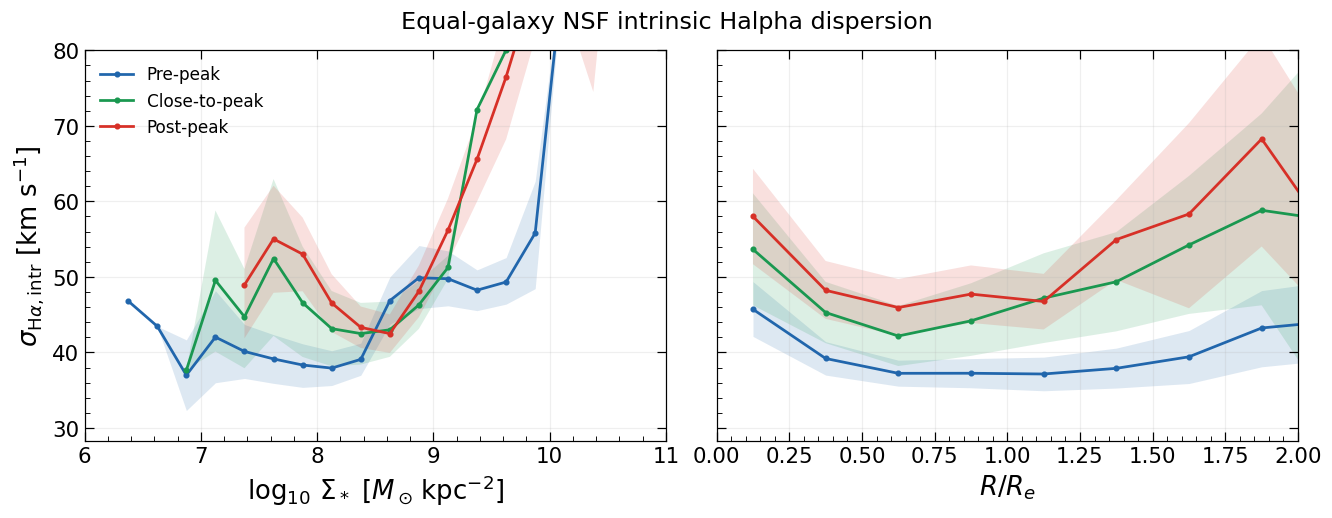

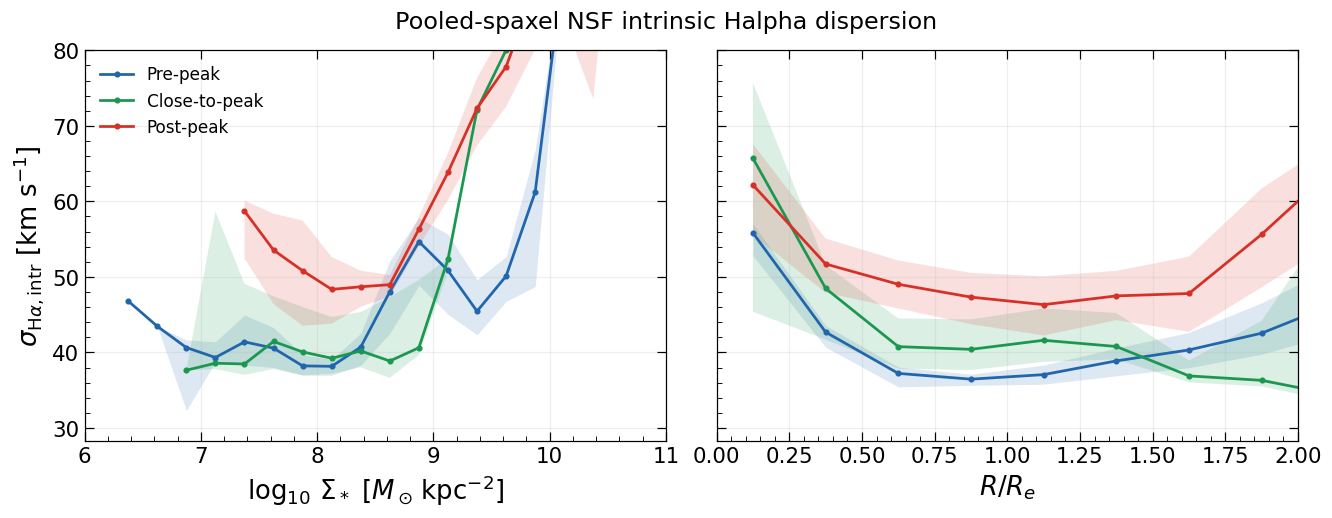

In [11]:
fraction_labels = {
    'log_sigma_star': r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]',
    'radius_re': r'$R/R_e$',
}
for branch in ('equal_galaxy', 'pooled_spaxel'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout='constrained')
    for ax, variable in zip(axes, ('log_sigma_star', 'radius_re')):
        for stage in (1, 2, 3):
            p = sigma135_profiles.loc[sigma135_profiles.branch.eq(branch) &
                sigma135_profiles.stage.eq(stage) & sigma135_profiles.variable.eq(variable)].sort_values('center')
            ax.plot(p.center, p.value, color=STAGE_COLORS[stage], marker='o', ms=3,
                lw=1.8, label=STAGE_LABELS[stage])
            ax.fill_between(p.center.to_numpy(float), p.lo.to_numpy(float), p.hi.to_numpy(float),
                color=STAGE_COLORS[stage], alpha=0.15, linewidth=0)
        ax.axhline(HIGH_SIGMA_LIMIT, color='0.45', ls=':', lw=1)
        ax.set_xlim(PROFILE_X_LIMITS[variable])  # display only; full-range statistics retained
        ax.set_ylim(top=80)  # display cap only; no extra data cut
        ax.set_xlabel(fraction_labels[variable])
        ax.tick_params(top=True, right=True)
        ax.minorticks_on(); ax.grid(alpha=0.2)
    axes[0].set_ylabel(r'$\sigma_{\mathrm{H}\alpha,\mathrm{intr}}$ [km s$^{-1}$]')
    axes[0].legend(frameon=False)
    label = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
    fig.suptitle(label + r' NSF intrinsic Halpha dispersion')
    save_figure(fig, 'NSF_intrinsic_Halpha_dispersion_le135_' + branch)
    plt.show(); plt.close(fig)

## Repeat cell 8 after removing intrinsic dispersion >225 km/s

Repeat both equal-galaxy and pooled-spaxel stage profiles versus stellar surface
density and R/R_e, retaining only **intrinsic Halpha dispersion <=225 km/s**.
The cut applies to individual finite NSF dispersion pixels in **every stage**,
before summing or averaging. Values exactly 225 km/s remain; larger values are
excluded rather than clipped to 225. The profiles cover the complete finite mass and radius ranges; the bounded map/distribution
regions are also reported separately in the removal-count tables. Earlier profiles, maps and distributions remain unchanged.

Rebuild the per-galaxy/bin statistics from the same FITS inputs and verify the
uncut footprint against the earlier statistics. Keep the original common usable
population and >=50 usable-pixel support gate; apply the ceiling to the dispersion
sample and recompute its >=20-pixel support gate, means, weighting and 10,000
whole-galaxy bootstrap intervals. Bins losing support are omitted (NaN).
This is a descriptive sensitivity check on the width tail, not a fit-quality criterion.

The count tables report removed numbers and percentages relative to the full
finite NSF dispersion footprint before this cut, per galaxy, stage and overall.
Additional tables use the bounded 7.5 <= log10 Sigma_star <8 and
1 < R/R_e <=1.5 regions, with their own pre-cut denominators. Region counts
overlap and must not be added together.
Both repeated profile plots have a displayed y-axis upper limit of 80 km/s;
this display limit adds no selection cut.

This 225 km/s cut is applied independently to the original pre-cut NSF
spaxels, not to a sample already filtered by a lower ceiling. Earlier sections
remain unchanged.

In [12]:
SIGMA_PROFILE_CEILING_225 = 225.0  # retain equality; exclude individual pixels above this
sigma225_rows, sigma225_count_rows, sigma225_region_count_rows = [], [], []
for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    gal = record.galaxy
    m, mh = read_map(record.mass, 'LOGMASS_SURFACE_DENSITY')
    ewh, eh = read_map(record.ew, 'PROXY_EWHA')
    snr, sh = read_map(record.sfh, 'SNR_POSTFIT')
    with fits.open(record.gas, memmap=True) as hdul:
        gh = hdul[0].header.copy()
        bin_header = hdul['BIN_ID'].header.copy()
        gas = {key: np.array(hdul[key].data, dtype=float) for key in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    assert all(a.shape == m.shape for a in (ewh, snr, *gas.values()))
    for other, label in ((eh, 'EW'), (sh, 'SFH'), (bin_header, 'gas')):
        check_wcs(mh, other, m.shape, gal + ' capped-profile ' + label)
    with fits.open(record.mask) as hdul:
        smask = np.asarray(hdul['MASKFILE'].data['MASK']).reshape(m.shape)
    usable = np.isfinite(m) & np.isfinite(gas['BIN_ID']) & (smask == 0) & np.isfinite(snr) & (snr > SNR_POSTFIT_MIN)
    rad = calculate_deprojected_radius(m.shape, mh, geometry.loc[geometry.notebook_product_id.eq(gal)])
    assert np.isfinite(rad[usable]).all()
    detected = np.ones(m.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        flux, err = gas[line+'_FLUX'], gas[line+'_FLUX_ERR']
        with np.errstate(divide='ignore', invalid='ignore'):
            detected &= np.isfinite(flux) & np.isfinite(err) & (err > 0) & (flux/err >= float(gh['CUT_SN'])) & (flux >= float(gh['NOISE']))
    radicand = gas['HA6562_SIGMA']**2 - gas['HA6562_SIGMA_CORR']**2
    intrinsic = np.sqrt(np.where(np.isfinite(radicand) & (radicand > 0), radicand, np.nan))
    is_sf = usable & np.isfinite(gas['LOGSFR_SURFACE_DENSITY_HII']) & np.isfinite(ewh) & (ewh > EW_MIN) & np.isfinite(intrinsic) & (intrinsic < SIGMA_MAX)
    is_nd = usable & ~detected
    original_sigma = usable & ~is_sf & ~is_nd & np.isfinite(intrinsic)
    kept_sigma = original_sigma & (intrinsic <= SIGMA_PROFILE_CEILING_225)
    removed_sigma = original_sigma & (intrinsic > SIGMA_PROFILE_CEILING_225)
    assert np.array_equal(original_sigma, kept_sigma | removed_sigma)
    assert (intrinsic[kept_sigma] > 0).all() and (intrinsic[kept_sigma] <= SIGMA_PROFILE_CEILING_225).all()
    expected = counts.set_index('galaxy').loc[gal]
    assert original_sigma.sum() == expected.N_sigma and usable.sum() == expected.usable
    sigma225_count_rows.append(dict(galaxy=gal, stage=int(record.stage),
        N_original=int(original_sigma.sum()), N_retained=int(kept_sigma.sum()), N_removed=int(removed_sigma.sum())))
    for region, region_mask in dispersion_region_masks(m, rad, original_sigma).items():
        retained = region_mask & (intrinsic <= SIGMA_PROFILE_CEILING_225)
        removed = region_mask & (intrinsic > SIGMA_PROFILE_CEILING_225)
        assert np.array_equal(region_mask, retained | removed)
        sigma225_region_count_rows.append(dict(galaxy=gal, stage=int(record.stage), region=region,
            N_original=int(region_mask.sum()), N_retained=int(retained.sum()), N_removed=int(removed.sum())))
    for variable, values in (('log_sigma_star', m), ('radius_re', rad)):
        edges = FRACTION_EDGES[variable]
        window = np.isfinite(values)  # no mass/radius range cut
        nv, _ = np.histogram(values[usable & window], bins=edges)
        nb, _ = np.histogram(values[original_sigma & window], bins=edges)
        nc, _ = np.histogram(values[kept_sigma & window], bins=edges)
        totals, _ = np.histogram(values[kept_sigma & window], bins=edges, weights=intrinsic[kept_sigma & window])
        previous = nsf_extra_by_galaxy.loc[nsf_extra_by_galaxy.galaxy.eq(gal) &
            nsf_extra_by_galaxy.variable.eq(variable)].sort_values('left')
        assert np.array_equal(nv, previous.N_valid) and np.array_equal(nb, previous.N_diag)
        assert np.all(nc <= nb) and nc.sum() == (kept_sigma & window).sum()
        for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
            sigma225_rows.append(dict(galaxy=gal, stage=int(record.stage), variable=variable,
                diagnostic='sigma_Ha_intrinsic', left=lo, right=hi, center=(lo+hi)/2,
                N_valid=int(nv[j]), N_diag=int(nc[j]), sum_primary=float(totals[j]),
                mean_primary=float(totals[j]/nc[j]) if nc[j] else np.nan,
                supported=bool(nv[j] >= FRACTION_MIN_USABLE and nc[j] >= NSF_EXTRA_MIN_PIXELS)))
sigma225_by_galaxy = pd.DataFrame(sigma225_rows)
sigma225_counts = pd.DataFrame(sigma225_count_rows)
assert (sigma225_counts.N_original == sigma225_counts.N_retained + sigma225_counts.N_removed).all()
sigma225_count_columns = ['N_original', 'N_retained', 'N_removed']
sigma225_stage_counts = sigma225_counts.groupby('stage')[sigma225_count_columns].sum()
sigma225_total_counts = pd.DataFrame([sigma225_counts[sigma225_count_columns].sum()], index=['All stages'])
for summary in (sigma225_counts, sigma225_stage_counts, sigma225_total_counts):
    summary['fraction_removed'] = np.divide(
        summary.N_removed.to_numpy(float), summary.N_original.to_numpy(float),
        out=np.full(len(summary), np.nan), where=summary.N_original.to_numpy(float) > 0)
    assert (summary.N_original == summary.N_retained + summary.N_removed).all()
    assert summary.fraction_removed.dropna().between(0, 1).all()
print('Removed: intrinsic Halpha dispersion >225 km/s. Fraction = N_removed / N_original.')
print('Denominator: finite NSF dispersion pixels before the cut, across each full galaxy footprint; with no mass or radius range cut.')
for label, summary in (
    ('Per galaxy', sigma225_counts),
    ('Per stage (1=pre-peak, 2=close-to-peak, 3=post-peak)', sigma225_stage_counts),
    ('Overall (pooled pixel counts)', sigma225_total_counts),
):
    print(label)
    display(summary.style.format({**{key: '{:,.0f}' for key in sigma225_count_columns},
        'fraction_removed': '{:.4%}'}, na_rep='--'))

sigma225_region_counts = pd.DataFrame(sigma225_region_count_rows)
sigma225_region_stage_counts = sigma225_region_counts.groupby(['region', 'stage'])[sigma225_count_columns].sum()
sigma225_region_total_counts = sigma225_region_counts.groupby('region')[sigma225_count_columns].sum()
for summary in (sigma225_region_counts, sigma225_region_stage_counts, sigma225_region_total_counts):
    summary['fraction_removed'] = np.divide(
        summary.N_removed.to_numpy(float), summary.N_original.to_numpy(float),
        out=np.full(len(summary), np.nan), where=summary.N_original.to_numpy(float) > 0)
    assert (summary.N_original == summary.N_retained + summary.N_removed).all()
    assert summary.fraction_removed.dropna().between(0, 1).all()
print('Bounded regions: 7.5 <= log10 Sigma_star <8; 1 < R/R_e <=1.5. Each fraction uses its own region before the sigma cut.')
for label, summary in (
    ('Bounded regions: per galaxy', sigma225_region_counts),
    ('Bounded regions: per stage', sigma225_region_stage_counts),
    ('Bounded regions: overall, pooled pixel counts', sigma225_region_total_counts),
):
    print(label)
    display(summary.style.format({**{key: '{:,.0f}' for key in sigma225_count_columns},
        'fraction_removed': '{:.4%}'}, na_rep='--'))


Removed: intrinsic Halpha dispersion >225 km/s. Fraction = N_removed / N_original.
Denominator: finite NSF dispersion pixels before the cut, across each full galaxy footprint; with no mass or radius range cut.
Per galaxy


,galaxy,stage,N_original,N_retained,N_removed,fraction_removed
0,IC3392,3,"9,123","9,076",47,0.5152%
1,NGC4064,3,"33,921","33,646",275,0.8107%
2,NGC4189,1,"34,012","34,012",0,0.0000%
3,NGC4254,1,"163,358","163,358",0,0.0000%
4,NGC4293,3,"63,400","58,717","4,683",7.3864%
5,NGC4294,1,"51,426","51,426",0,0.0000%
6,NGC4298,2,"43,104","43,104",0,0.0000%
7,NGC4321,1,"329,655","329,647",8,0.0024%
8,NGC4351,1,"16,682","16,682",0,0.0000%
9,NGC4380,3,"51,190","51,190",0,0.0000%


Per stage (1=pre-peak, 2=close-to-peak, 3=post-peak)


,N_original,N_retained,N_removed,fraction_removed
stage,,,,
1,"929,104","929,096",8,0.0009%
2,"488,865","488,075",790,0.1616%
3,"815,887","804,861","11,026",1.3514%


Overall (pooled pixel counts)


...

Bounded regions: 7.5 <= log10 Sigma_star <8; 1 < R/R_e <=1.5. Each fraction uses its own region before the sigma cut.
Bounded regions: per galaxy


,galaxy,stage,region,N_original,N_retained,N_removed,fraction_removed
0,IC3392,3,logSigmaStar_7p5_to_8,"2,158","2,111",47,2.1779%
1,IC3392,3,R_over_Re_1_to_1p5,"1,996","1,949",47,2.3547%
2,NGC4064,3,logSigmaStar_7p5_to_8,"9,669","9,612",57,0.5895%
3,NGC4064,3,R_over_Re_1_to_1p5,"1,130",918,212,18.7611%
4,NGC4189,1,logSigmaStar_7p5_to_8,"14,327","14,327",0,0.0000%
5,NGC4189,1,R_over_Re_1_to_1p5,"6,422","6,422",0,0.0000%
6,NGC4254,1,logSigmaStar_7p5_to_8,"81,313","81,313",0,0.0000%
7,NGC4254,1,R_over_Re_1_to_1p5,"51,508","51,508",0,0.0000%
8,NGC4293,3,logSigmaStar_7p5_to_8,"5,468","3,291","2,177",39.8135%
9,NGC4293,3,R_over_Re_1_to_1p5,"4,511","2,675","1,836",40.7005%


Bounded regions: per stage


Bounded regions: overall, pooled pixel counts


,N_original,N_retained,N_removed,fraction_removed
region,,,,
R_over_Re_1_to_1p5,"520,224","517,502","2,722",0.5232%
logSigmaStar_7p5_to_8,"649,065","642,369","6,696",1.0316%


In [13]:
assert (sigma225_by_galaxy.N_diag<=sigma225_by_galaxy.N_valid).all()
assert np.array_equal(sigma225_by_galaxy.supported,
    (sigma225_by_galaxy.N_valid>=FRACTION_MIN_USABLE)&(sigma225_by_galaxy.N_diag>=NSF_EXTRA_MIN_PIXELS))
sigma225_profile_rows=[]
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
    g=len(galaxy_ids)
    for branch,seed_base in [('equal_galaxy',15_000_000),('pooled_spaxel',16_000_000)]:
        extra_rng=np.random.default_rng(RANDOM_SEED+seed_base+100_000*(stage-1))
        draw=extra_rng.integers(0,g,size=(NSF_EXTRA_N_BOOTSTRAP,g))
        for variable,bin_edges in FRACTION_EDGES.items():
            for diagnostic in NSF_EXTRA_DIAGNOSTICS:
                for lo,hi in zip(bin_edges[:-1],bin_edges[1:]):
                    panel=sigma225_by_galaxy.loc[sigma225_by_galaxy.stage.eq(stage)&
                        sigma225_by_galaxy.variable.eq(variable)&sigma225_by_galaxy.diagnostic.eq(diagnostic)&
                        np.isclose(sigma225_by_galaxy.left,lo)].set_index('galaxy').reindex(galaxy_ids)
                    assert panel.N_diag.notna().all()
                    support=panel.supported.to_numpy(bool)
                    paired=diagnostic=='SII_doublet'
                    fields=['primary','secondary'] if paired else ['primary']
                    if branch=='equal_galaxy':
                        values=np.column_stack([panel['mean_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,np.nan)
                        denominator=support[draw].sum(axis=1)
                        boot=np.divide(np.nansum(values[draw],axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=np.mean(values[support],axis=0) if support.any() else np.full(len(fields),np.nan)
                    else:
                        values=np.column_stack([panel['sum_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,0.)
                        pixel_counts=np.where(support,panel.N_diag.to_numpy(float),0.)
                        denominator=pixel_counts[draw].sum(axis=1)
                        boot=np.divide(values[draw].sum(axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=values.sum(axis=0)/pixel_counts.sum() if pixel_counts.sum()>0 else np.full(len(fields),np.nan)
                    finite=denominator>0
                    assert np.isfinite(boot[finite]).all()
                    if paired:
                        assert (boot[finite]>0).all()
                        draws=boot[finite,0]/boot[finite,1]
                        value=central[0]/central[1] if support.any() else np.nan
                        if branch=='pooled_spaxel' and support.any():
                            assert np.isclose(value,panel.loc[panel.supported,'sum_primary'].sum()/panel.loc[panel.supported,'sum_secondary'].sum(),rtol=1e-12)
                    else:
                        draws=boot[finite,0]
                        value=central[0]
                        if branch=='pooled_spaxel' and support.any():
                            direct=np.sum(panel.loc[panel.supported,'mean_primary']*panel.loc[panel.supported,'N_diag'])/panel.loc[panel.supported,'N_diag'].sum()
                            assert np.isclose(value,direct,rtol=1e-12,atol=1e-12)
                    low,high=np.percentile(draws,[16,84]) if len(draws) else (np.nan,np.nan)
                    sigma225_profile_rows.append(dict(branch=branch,stage=stage,variable=variable,diagnostic=diagnostic,
                        left=lo,right=hi,center=(lo+hi)/2,N_gal_support=int(support.sum()),
                        N_spaxel_support=int(panel.loc[panel.supported,'N_diag'].sum()),
                        N_finite_draws=int(finite.sum()),value=value,lo=low,hi=high))
sigma225_profiles=pd.DataFrame(sigma225_profile_rows)
assert len(sigma225_profiles)==2*3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())*len(NSF_EXTRA_DIAGNOSTICS)
supported=sigma225_profiles.N_gal_support.gt(0)
assert np.isfinite(sigma225_profiles.loc[supported,['value','lo','hi']]).all().all()
assert (sigma225_profiles.loc[supported,'lo']<=sigma225_profiles.loc[supported,'hi']).all()
assert sigma225_profiles.N_finite_draws.le(NSF_EXTRA_N_BOOTSTRAP).all()
positive=supported&sigma225_profiles.diagnostic.isin(['sigma_Ha_intrinsic','SII_doublet'])
assert (sigma225_profiles.loc[positive,['value','lo','hi']]>0).all().all()
display(sigma225_profiles)
assert (sigma225_profiles.loc[supported, ['value', 'lo', 'hi']] <= SIGMA_PROFILE_CEILING_225 + 1e-9).all().all()
print('Capped profiles: support, pooled reconstruction, bootstrap and <=225 km/s checks passed')

,branch,stage,variable,diagnostic,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi
0,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,5.75,6.00,5.875,0,0,0,NaN,NaN,NaN
1,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.00,6.25,6.125,0,0,0,NaN,NaN,NaN
2,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.25,6.50,6.375,1,443,6585,46.806609,46.806609,46.806609
3,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.50,6.75,6.625,1,1007,6585,43.460349,43.460349,43.460349
4,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.75,7.00,6.875,2,10281,9011,36.988530,32.312368,41.664691
...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.00,11.25,11.125,0,0,0,NaN,NaN,NaN
422,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.25,11.50,11.375,0,0,0,NaN,NaN,NaN
423,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.50,11.75,11.625,0,0,0,NaN,NaN,NaN
424,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.75,12.00,11.875,0,0,0,NaN,NaN,NaN


Capped profiles: support, pooled reconstruction, bootstrap and <=225 km/s checks passed


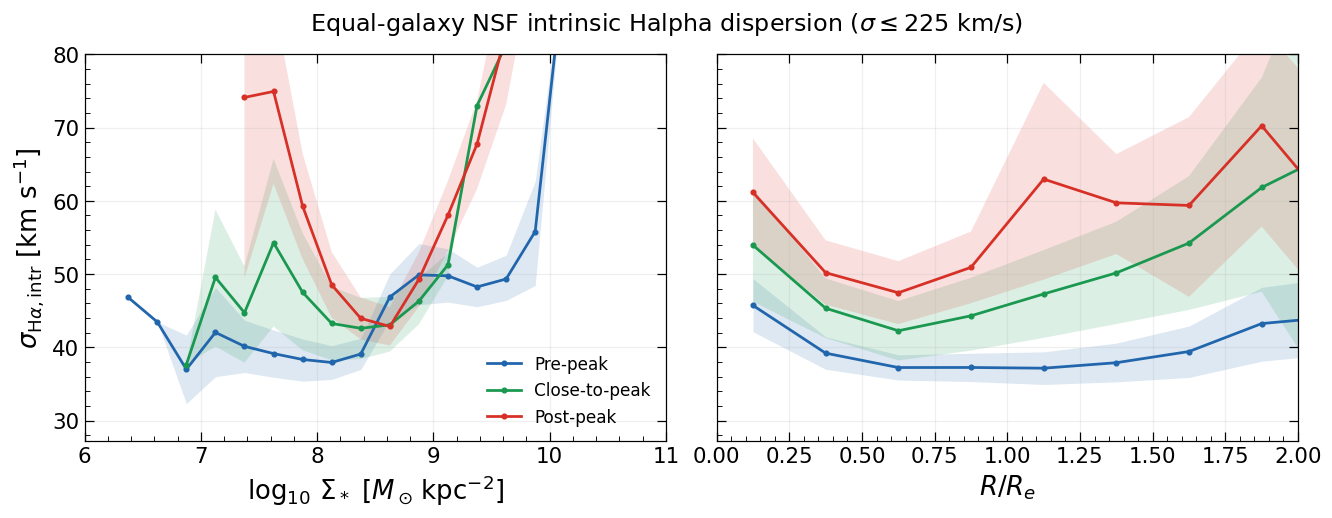

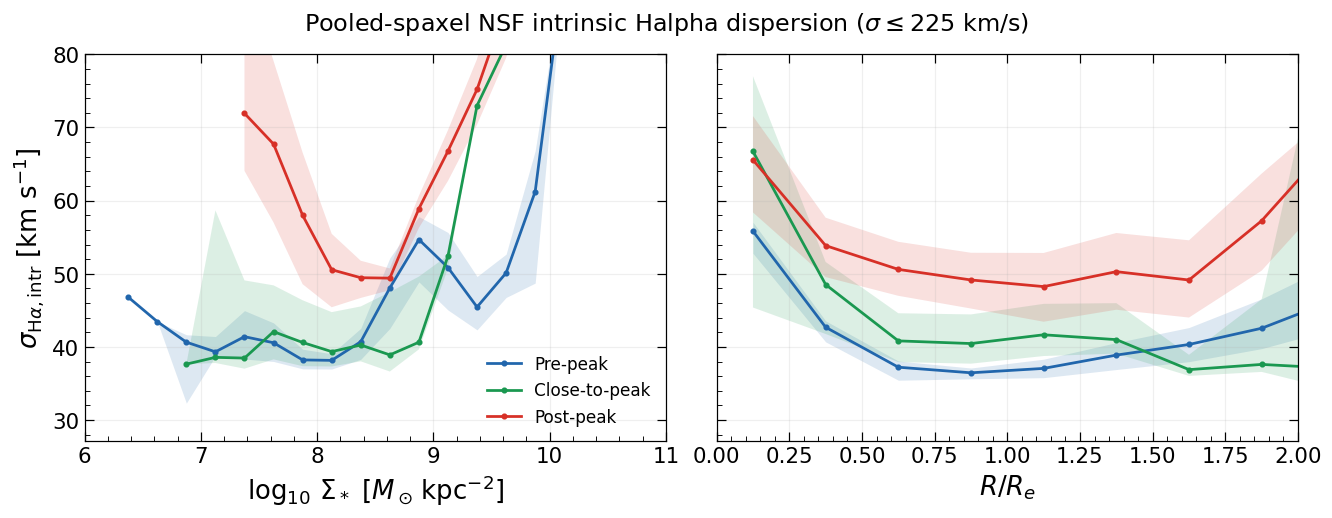

In [14]:
fraction_labels = {
    'log_sigma_star': r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]',
    'radius_re': r'$R/R_e$',
}
for branch in ('equal_galaxy', 'pooled_spaxel'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout='constrained')
    for ax, variable in zip(axes, ('log_sigma_star', 'radius_re')):
        for stage in (1, 2, 3):
            p = sigma225_profiles.loc[sigma225_profiles.branch.eq(branch) &
                sigma225_profiles.stage.eq(stage) & sigma225_profiles.variable.eq(variable)].sort_values('center')
            ax.plot(p.center, p.value, color=STAGE_COLORS[stage], marker='o', ms=3,
                lw=1.8, label=STAGE_LABELS[stage])
            ax.fill_between(p.center.to_numpy(float), p.lo.to_numpy(float), p.hi.to_numpy(float),
                color=STAGE_COLORS[stage], alpha=0.15, linewidth=0)
        ax.axhline(HIGH_SIGMA_LIMIT, color='0.45', ls=':', lw=1)
        ax.set_xlim(PROFILE_X_LIMITS[variable])  # display only; full-range statistics retained
        ax.set_ylim(top=80)  # display cap only; no extra data cut
        ax.set_xlabel(fraction_labels[variable])
        ax.tick_params(top=True, right=True)
        ax.minorticks_on(); ax.grid(alpha=0.2)
    axes[0].set_ylabel(r'$\sigma_{\mathrm{H}\alpha,\mathrm{intr}}$ [km s$^{-1}$]')
    axes[0].legend(frameon=False)
    label = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
    fig.suptitle(label + r' NSF intrinsic Halpha dispersion ($\sigma \leq 225$ km/s)')
    save_figure(fig, 'NSF_intrinsic_Halpha_dispersion_le225_' + branch)
    plt.show(); plt.close(fig)

## Repeat cell 8 after removing intrinsic dispersion >450 km/s

Repeat both equal-galaxy and pooled-spaxel stage profiles versus stellar surface
density and R/R_e, retaining only **intrinsic Halpha dispersion <=450 km/s**.
The cut applies to individual finite NSF dispersion pixels in **every stage**,
before summing or averaging. Values exactly 450 km/s remain; larger values are
excluded rather than clipped to 450. The profiles cover the complete finite mass and radius ranges; the bounded map/distribution
regions are also reported separately in the removal-count tables. Earlier profiles, maps and distributions remain unchanged.

Rebuild the per-galaxy/bin statistics from the same FITS inputs and verify the
uncut footprint against the earlier statistics. Keep the original common usable
population and >=50 usable-pixel support gate; apply the ceiling to the dispersion
sample and recompute its >=20-pixel support gate, means, weighting and 10,000
whole-galaxy bootstrap intervals. Bins losing support are omitted (NaN).
This is a descriptive sensitivity check on the width tail, not a fit-quality criterion.

The count tables report removed numbers and percentages relative to the full
finite NSF dispersion footprint before this cut, per galaxy, stage and overall.
Additional tables use the bounded 7.5 <= log10 Sigma_star <8 and
1 < R/R_e <=1.5 regions, with their own pre-cut denominators. Region counts
overlap and must not be added together.
Both repeated profile plots have a displayed y-axis upper limit of 80 km/s;
this display limit adds no selection cut.

This 450 km/s cut is applied independently to the original pre-cut NSF
spaxels, not to a sample already filtered by a lower ceiling. Earlier sections
remain unchanged.

In [15]:
SIGMA_PROFILE_CEILING_450 = 450.0  # retain equality; exclude individual pixels above this
sigma450_rows, sigma450_count_rows, sigma450_region_count_rows = [], [], []
for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    gal = record.galaxy
    m, mh = read_map(record.mass, 'LOGMASS_SURFACE_DENSITY')
    ewh, eh = read_map(record.ew, 'PROXY_EWHA')
    snr, sh = read_map(record.sfh, 'SNR_POSTFIT')
    with fits.open(record.gas, memmap=True) as hdul:
        gh = hdul[0].header.copy()
        bin_header = hdul['BIN_ID'].header.copy()
        gas = {key: np.array(hdul[key].data, dtype=float) for key in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    assert all(a.shape == m.shape for a in (ewh, snr, *gas.values()))
    for other, label in ((eh, 'EW'), (sh, 'SFH'), (bin_header, 'gas')):
        check_wcs(mh, other, m.shape, gal + ' capped-profile ' + label)
    with fits.open(record.mask) as hdul:
        smask = np.asarray(hdul['MASKFILE'].data['MASK']).reshape(m.shape)
    usable = np.isfinite(m) & np.isfinite(gas['BIN_ID']) & (smask == 0) & np.isfinite(snr) & (snr > SNR_POSTFIT_MIN)
    rad = calculate_deprojected_radius(m.shape, mh, geometry.loc[geometry.notebook_product_id.eq(gal)])
    assert np.isfinite(rad[usable]).all()
    detected = np.ones(m.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        flux, err = gas[line+'_FLUX'], gas[line+'_FLUX_ERR']
        with np.errstate(divide='ignore', invalid='ignore'):
            detected &= np.isfinite(flux) & np.isfinite(err) & (err > 0) & (flux/err >= float(gh['CUT_SN'])) & (flux >= float(gh['NOISE']))
    radicand = gas['HA6562_SIGMA']**2 - gas['HA6562_SIGMA_CORR']**2
    intrinsic = np.sqrt(np.where(np.isfinite(radicand) & (radicand > 0), radicand, np.nan))
    is_sf = usable & np.isfinite(gas['LOGSFR_SURFACE_DENSITY_HII']) & np.isfinite(ewh) & (ewh > EW_MIN) & np.isfinite(intrinsic) & (intrinsic < SIGMA_MAX)
    is_nd = usable & ~detected
    original_sigma = usable & ~is_sf & ~is_nd & np.isfinite(intrinsic)
    kept_sigma = original_sigma & (intrinsic <= SIGMA_PROFILE_CEILING_450)
    removed_sigma = original_sigma & (intrinsic > SIGMA_PROFILE_CEILING_450)
    assert np.array_equal(original_sigma, kept_sigma | removed_sigma)
    assert (intrinsic[kept_sigma] > 0).all() and (intrinsic[kept_sigma] <= SIGMA_PROFILE_CEILING_450).all()
    expected = counts.set_index('galaxy').loc[gal]
    assert original_sigma.sum() == expected.N_sigma and usable.sum() == expected.usable
    sigma450_count_rows.append(dict(galaxy=gal, stage=int(record.stage),
        N_original=int(original_sigma.sum()), N_retained=int(kept_sigma.sum()), N_removed=int(removed_sigma.sum())))
    for region, region_mask in dispersion_region_masks(m, rad, original_sigma).items():
        retained = region_mask & (intrinsic <= SIGMA_PROFILE_CEILING_450)
        removed = region_mask & (intrinsic > SIGMA_PROFILE_CEILING_450)
        assert np.array_equal(region_mask, retained | removed)
        sigma450_region_count_rows.append(dict(galaxy=gal, stage=int(record.stage), region=region,
            N_original=int(region_mask.sum()), N_retained=int(retained.sum()), N_removed=int(removed.sum())))
    for variable, values in (('log_sigma_star', m), ('radius_re', rad)):
        edges = FRACTION_EDGES[variable]
        window = np.isfinite(values)  # no mass/radius range cut
        nv, _ = np.histogram(values[usable & window], bins=edges)
        nb, _ = np.histogram(values[original_sigma & window], bins=edges)
        nc, _ = np.histogram(values[kept_sigma & window], bins=edges)
        totals, _ = np.histogram(values[kept_sigma & window], bins=edges, weights=intrinsic[kept_sigma & window])
        previous = nsf_extra_by_galaxy.loc[nsf_extra_by_galaxy.galaxy.eq(gal) &
            nsf_extra_by_galaxy.variable.eq(variable)].sort_values('left')
        assert np.array_equal(nv, previous.N_valid) and np.array_equal(nb, previous.N_diag)
        assert np.all(nc <= nb) and nc.sum() == (kept_sigma & window).sum()
        for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
            sigma450_rows.append(dict(galaxy=gal, stage=int(record.stage), variable=variable,
                diagnostic='sigma_Ha_intrinsic', left=lo, right=hi, center=(lo+hi)/2,
                N_valid=int(nv[j]), N_diag=int(nc[j]), sum_primary=float(totals[j]),
                mean_primary=float(totals[j]/nc[j]) if nc[j] else np.nan,
                supported=bool(nv[j] >= FRACTION_MIN_USABLE and nc[j] >= NSF_EXTRA_MIN_PIXELS)))
sigma450_by_galaxy = pd.DataFrame(sigma450_rows)
sigma450_counts = pd.DataFrame(sigma450_count_rows)
assert (sigma450_counts.N_original == sigma450_counts.N_retained + sigma450_counts.N_removed).all()
sigma450_count_columns = ['N_original', 'N_retained', 'N_removed']
sigma450_stage_counts = sigma450_counts.groupby('stage')[sigma450_count_columns].sum()
sigma450_total_counts = pd.DataFrame([sigma450_counts[sigma450_count_columns].sum()], index=['All stages'])
for summary in (sigma450_counts, sigma450_stage_counts, sigma450_total_counts):
    summary['fraction_removed'] = np.divide(
        summary.N_removed.to_numpy(float), summary.N_original.to_numpy(float),
        out=np.full(len(summary), np.nan), where=summary.N_original.to_numpy(float) > 0)
    assert (summary.N_original == summary.N_retained + summary.N_removed).all()
    assert summary.fraction_removed.dropna().between(0, 1).all()
print('Removed: intrinsic Halpha dispersion >450 km/s. Fraction = N_removed / N_original.')
print('Denominator: finite NSF dispersion pixels before the cut, across each full galaxy footprint; with no mass or radius range cut.')
for label, summary in (
    ('Per galaxy', sigma450_counts),
    ('Per stage (1=pre-peak, 2=close-to-peak, 3=post-peak)', sigma450_stage_counts),
    ('Overall (pooled pixel counts)', sigma450_total_counts),
):
    print(label)
    display(summary.style.format({**{key: '{:,.0f}' for key in sigma450_count_columns},
        'fraction_removed': '{:.4%}'}, na_rep='--'))

sigma450_region_counts = pd.DataFrame(sigma450_region_count_rows)
sigma450_region_stage_counts = sigma450_region_counts.groupby(['region', 'stage'])[sigma450_count_columns].sum()
sigma450_region_total_counts = sigma450_region_counts.groupby('region')[sigma450_count_columns].sum()
for summary in (sigma450_region_counts, sigma450_region_stage_counts, sigma450_region_total_counts):
    summary['fraction_removed'] = np.divide(
        summary.N_removed.to_numpy(float), summary.N_original.to_numpy(float),
        out=np.full(len(summary), np.nan), where=summary.N_original.to_numpy(float) > 0)
    assert (summary.N_original == summary.N_retained + summary.N_removed).all()
    assert summary.fraction_removed.dropna().between(0, 1).all()
print('Bounded regions: 7.5 <= log10 Sigma_star <8; 1 < R/R_e <=1.5. Each fraction uses its own region before the sigma cut.')
for label, summary in (
    ('Bounded regions: per galaxy', sigma450_region_counts),
    ('Bounded regions: per stage', sigma450_region_stage_counts),
    ('Bounded regions: overall, pooled pixel counts', sigma450_region_total_counts),
):
    print(label)
    display(summary.style.format({**{key: '{:,.0f}' for key in sigma450_count_columns},
        'fraction_removed': '{:.4%}'}, na_rep='--'))


Removed: intrinsic Halpha dispersion >450 km/s. Fraction = N_removed / N_original.
Denominator: finite NSF dispersion pixels before the cut, across each full galaxy footprint; with no mass or radius range cut.
Per galaxy


,galaxy,stage,N_original,N_retained,N_removed,fraction_removed
0,IC3392,3,"9,123","9,123",0,0.0000%
1,NGC4064,3,"33,921","33,921",0,0.0000%
2,NGC4189,1,"34,012","34,012",0,0.0000%
3,NGC4254,1,"163,358","163,358",0,0.0000%
4,NGC4293,3,"63,400","61,234","2,166",3.4164%
5,NGC4294,1,"51,426","51,426",0,0.0000%
6,NGC4298,2,"43,104","43,104",0,0.0000%
7,NGC4321,1,"329,655","329,655",0,0.0000%
8,NGC4351,1,"16,682","16,682",0,0.0000%
9,NGC4380,3,"51,190","51,190",0,0.0000%


Per stage (1=pre-peak, 2=close-to-peak, 3=post-peak)


,N_original,N_retained,N_removed,fraction_removed
stage,,,,
1,"929,104","929,104",0,0.0000%
2,"488,865","488,334",531,0.1086%
3,"815,887","812,043","3,844",0.4711%


Overall (pooled pixel counts)


...

Bounded regions: 7.5 <= log10 Sigma_star <8; 1 < R/R_e <=1.5. Each fraction uses its own region before the sigma cut.
Bounded regions: per galaxy


,galaxy,stage,region,N_original,N_retained,N_removed,fraction_removed
0,IC3392,3,logSigmaStar_7p5_to_8,"2,158","2,158",0,0.0000%
1,IC3392,3,R_over_Re_1_to_1p5,"1,996","1,996",0,0.0000%
2,NGC4064,3,logSigmaStar_7p5_to_8,"9,669","9,669",0,0.0000%
3,NGC4064,3,R_over_Re_1_to_1p5,"1,130","1,130",0,0.0000%
4,NGC4189,1,logSigmaStar_7p5_to_8,"14,327","14,327",0,0.0000%
5,NGC4189,1,R_over_Re_1_to_1p5,"6,422","6,422",0,0.0000%
6,NGC4254,1,logSigmaStar_7p5_to_8,"81,313","81,313",0,0.0000%
7,NGC4254,1,R_over_Re_1_to_1p5,"51,508","51,508",0,0.0000%
8,NGC4293,3,logSigmaStar_7p5_to_8,"5,468","4,495",973,17.7944%
9,NGC4293,3,R_over_Re_1_to_1p5,"4,511","3,501","1,010",22.3897%


Bounded regions: per stage


Bounded regions: overall, pooled pixel counts


,N_original,N_retained,N_removed,fraction_removed
region,,,,
R_over_Re_1_to_1p5,"520,224","519,037","1,187",0.2282%
logSigmaStar_7p5_to_8,"649,065","646,677","2,388",0.3679%


In [16]:
assert (sigma450_by_galaxy.N_diag<=sigma450_by_galaxy.N_valid).all()
assert np.array_equal(sigma450_by_galaxy.supported,
    (sigma450_by_galaxy.N_valid>=FRACTION_MIN_USABLE)&(sigma450_by_galaxy.N_diag>=NSF_EXTRA_MIN_PIXELS))
sigma450_profile_rows=[]
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
    g=len(galaxy_ids)
    for branch,seed_base in [('equal_galaxy',15_000_000),('pooled_spaxel',16_000_000)]:
        extra_rng=np.random.default_rng(RANDOM_SEED+seed_base+100_000*(stage-1))
        draw=extra_rng.integers(0,g,size=(NSF_EXTRA_N_BOOTSTRAP,g))
        for variable,bin_edges in FRACTION_EDGES.items():
            for diagnostic in NSF_EXTRA_DIAGNOSTICS:
                for lo,hi in zip(bin_edges[:-1],bin_edges[1:]):
                    panel=sigma450_by_galaxy.loc[sigma450_by_galaxy.stage.eq(stage)&
                        sigma450_by_galaxy.variable.eq(variable)&sigma450_by_galaxy.diagnostic.eq(diagnostic)&
                        np.isclose(sigma450_by_galaxy.left,lo)].set_index('galaxy').reindex(galaxy_ids)
                    assert panel.N_diag.notna().all()
                    support=panel.supported.to_numpy(bool)
                    paired=diagnostic=='SII_doublet'
                    fields=['primary','secondary'] if paired else ['primary']
                    if branch=='equal_galaxy':
                        values=np.column_stack([panel['mean_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,np.nan)
                        denominator=support[draw].sum(axis=1)
                        boot=np.divide(np.nansum(values[draw],axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=np.mean(values[support],axis=0) if support.any() else np.full(len(fields),np.nan)
                    else:
                        values=np.column_stack([panel['sum_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,0.)
                        pixel_counts=np.where(support,panel.N_diag.to_numpy(float),0.)
                        denominator=pixel_counts[draw].sum(axis=1)
                        boot=np.divide(values[draw].sum(axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=values.sum(axis=0)/pixel_counts.sum() if pixel_counts.sum()>0 else np.full(len(fields),np.nan)
                    finite=denominator>0
                    assert np.isfinite(boot[finite]).all()
                    if paired:
                        assert (boot[finite]>0).all()
                        draws=boot[finite,0]/boot[finite,1]
                        value=central[0]/central[1] if support.any() else np.nan
                        if branch=='pooled_spaxel' and support.any():
                            assert np.isclose(value,panel.loc[panel.supported,'sum_primary'].sum()/panel.loc[panel.supported,'sum_secondary'].sum(),rtol=1e-12)
                    else:
                        draws=boot[finite,0]
                        value=central[0]
                        if branch=='pooled_spaxel' and support.any():
                            direct=np.sum(panel.loc[panel.supported,'mean_primary']*panel.loc[panel.supported,'N_diag'])/panel.loc[panel.supported,'N_diag'].sum()
                            assert np.isclose(value,direct,rtol=1e-12,atol=1e-12)
                    low,high=np.percentile(draws,[16,84]) if len(draws) else (np.nan,np.nan)
                    sigma450_profile_rows.append(dict(branch=branch,stage=stage,variable=variable,diagnostic=diagnostic,
                        left=lo,right=hi,center=(lo+hi)/2,N_gal_support=int(support.sum()),
                        N_spaxel_support=int(panel.loc[panel.supported,'N_diag'].sum()),
                        N_finite_draws=int(finite.sum()),value=value,lo=low,hi=high))
sigma450_profiles=pd.DataFrame(sigma450_profile_rows)
assert len(sigma450_profiles)==2*3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())*len(NSF_EXTRA_DIAGNOSTICS)
supported=sigma450_profiles.N_gal_support.gt(0)
assert np.isfinite(sigma450_profiles.loc[supported,['value','lo','hi']]).all().all()
assert (sigma450_profiles.loc[supported,'lo']<=sigma450_profiles.loc[supported,'hi']).all()
assert sigma450_profiles.N_finite_draws.le(NSF_EXTRA_N_BOOTSTRAP).all()
positive=supported&sigma450_profiles.diagnostic.isin(['sigma_Ha_intrinsic','SII_doublet'])
assert (sigma450_profiles.loc[positive,['value','lo','hi']]>0).all().all()
display(sigma450_profiles)
assert (sigma450_profiles.loc[supported, ['value', 'lo', 'hi']] <= SIGMA_PROFILE_CEILING_450 + 1e-9).all().all()
print('Capped profiles: support, pooled reconstruction, bootstrap and <=450 km/s checks passed')

,branch,stage,variable,diagnostic,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi
0,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,5.75,6.00,5.875,0,0,0,NaN,NaN,NaN
1,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.00,6.25,6.125,0,0,0,NaN,NaN,NaN
2,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.25,6.50,6.375,1,443,6585,46.806609,46.806609,46.806609
3,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.50,6.75,6.625,1,1007,6585,43.460349,43.460349,43.460349
4,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.75,7.00,6.875,2,10281,9011,36.988530,32.312368,41.664691
...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.00,11.25,11.125,0,0,0,NaN,NaN,NaN
422,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.25,11.50,11.375,0,0,0,NaN,NaN,NaN
423,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.50,11.75,11.625,0,0,0,NaN,NaN,NaN
424,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.75,12.00,11.875,0,0,0,NaN,NaN,NaN


Capped profiles: support, pooled reconstruction, bootstrap and <=450 km/s checks passed


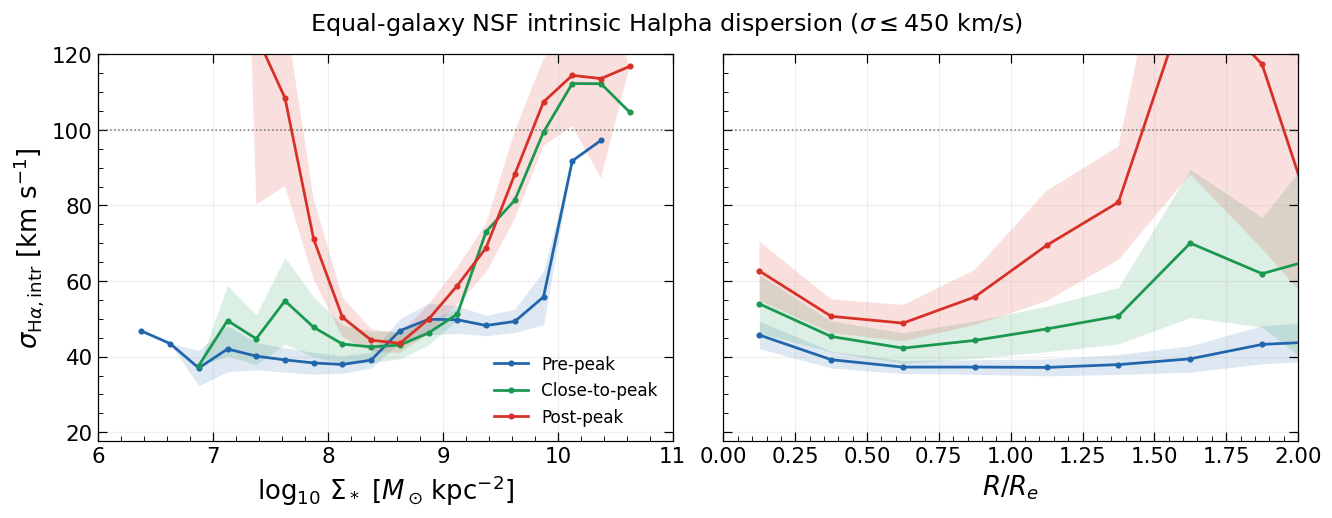

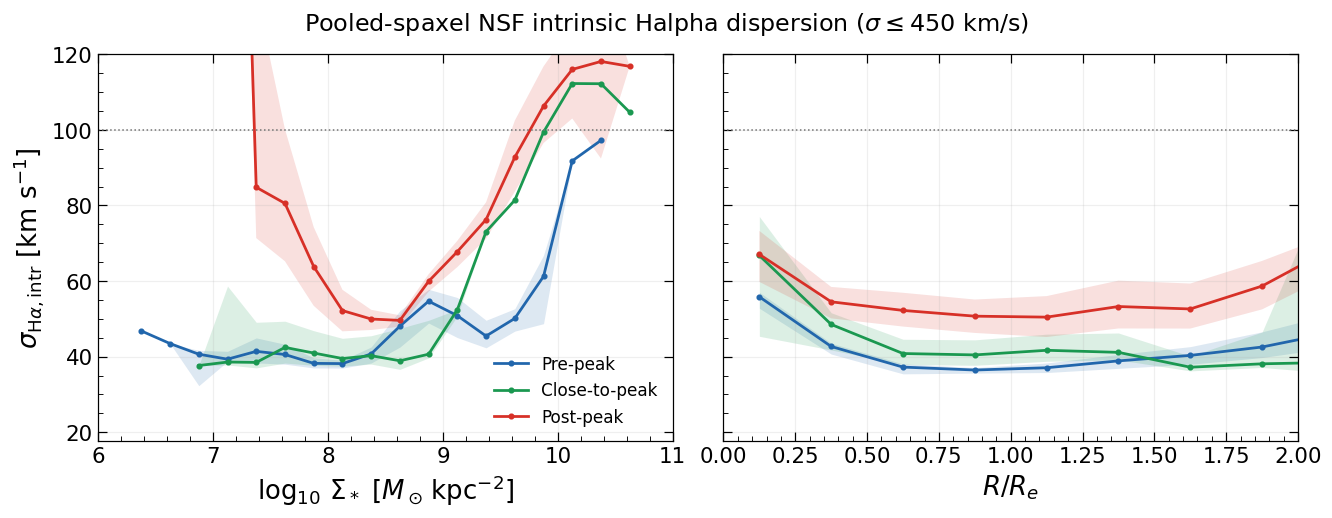

In [17]:
fraction_labels = {
    'log_sigma_star': r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]',
    'radius_re': r'$R/R_e$',
}
for branch in ('equal_galaxy', 'pooled_spaxel'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout='constrained')
    for ax, variable in zip(axes, ('log_sigma_star', 'radius_re')):
        for stage in (1, 2, 3):
            p = sigma450_profiles.loc[sigma450_profiles.branch.eq(branch) &
                sigma450_profiles.stage.eq(stage) & sigma450_profiles.variable.eq(variable)].sort_values('center')
            ax.plot(p.center, p.value, color=STAGE_COLORS[stage], marker='o', ms=3,
                lw=1.8, label=STAGE_LABELS[stage])
            ax.fill_between(p.center.to_numpy(float), p.lo.to_numpy(float), p.hi.to_numpy(float),
                color=STAGE_COLORS[stage], alpha=0.15, linewidth=0)
        ax.axhline(HIGH_SIGMA_LIMIT, color='0.45', ls=':', lw=1)
        ax.set_xlim(PROFILE_X_LIMITS[variable])  # display only; full-range statistics retained
        ax.set_ylim(top=120)  # display cap only; no extra data cut
        ax.set_xlabel(fraction_labels[variable])
        ax.tick_params(top=True, right=True)
        ax.minorticks_on(); ax.grid(alpha=0.2)
    axes[0].set_ylabel(r'$\sigma_{\mathrm{H}\alpha,\mathrm{intr}}$ [km s$^{-1}$]')
    axes[0].legend(frameon=False)
    label = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
    fig.suptitle(label + r' NSF intrinsic Halpha dispersion ($\sigma \leq 450$ km/s)')
    save_figure(fig, 'NSF_intrinsic_Halpha_dispersion_le450_' + branch)
    plt.show(); plt.close(fig)

## Repeat cell 8 with Halpha Flux/Flux_err >5

Independently select original finite-dispersion NSF spaxels with
**HA6562_FLUX / HA6562_FLUX_ERR >5**, using the stored raw gas-fit flux
and its matching error. Both inputs must be finite and the error strictly positive;
the ratio must also be finite. Equality fails the strict threshold. This is an
**Halpha flux S/N selection**, not a direct residual-based fit-goodness statistic.
No 135, 225 or 450 km/s dispersion ceiling is applied in this case.

Retain the original inclination <80, SNR_POSTFIT >25, SF/ND/NSF classification,
geometry and full-range profile bins (no mass or radius range cut). The >=50 common usable-pixel support gate stays fixed;
recompute the >=20 retained diagnostic-pixel gate, equal-galaxy and pooled means,
and 10,000 whole-galaxy bootstrap intervals after the flux S/N cut. Unsupported
bins stay NaN. The plot y-axis retains the current 80 km/s display cap; this
does not exclude pixels or truncate computed profiles.

Report counts and removed fractions relative to the original finite NSF dispersion
sample, per galaxy, stage and overall. Also report the separate bounded regions
**7.5 <= log10 Sigma_star <8** and **1 < R/R_e <=1.5**, each with its own pre-cut
denominator. These overlapping region counts must not be added. This selection
is independent of all preceding dispersion-ceiling cases and the other Halpha
flux S/N threshold. Earlier sections remain unchanged.

In [18]:
HA_FLUX_SNR_MIN_5 = 5.0  # strict Halpha flux/error threshold
ha_snr5_rows, ha_snr5_count_rows, ha_snr5_region_count_rows = [], [], []
for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    gal = record.galaxy
    m, mh = read_map(record.mass, 'LOGMASS_SURFACE_DENSITY')
    ewh, eh = read_map(record.ew, 'PROXY_EWHA')
    snr, sh = read_map(record.sfh, 'SNR_POSTFIT')
    with fits.open(record.gas, memmap=True) as hdul:
        gh = hdul[0].header.copy()
        bin_header = hdul['BIN_ID'].header.copy()
        gas = {key: np.array(hdul[key].data, dtype=float) for key in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    assert all(a.shape == m.shape for a in (ewh, snr, *gas.values()))
    for other, label in ((eh, 'EW'), (sh, 'SFH'), (bin_header, 'gas')):
        check_wcs(mh, other, m.shape, gal + ' Halpha flux S/N profile ' + label)
    with fits.open(record.mask) as hdul:
        smask = np.asarray(hdul['MASKFILE'].data['MASK']).reshape(m.shape)
    usable = np.isfinite(m) & np.isfinite(gas['BIN_ID']) & (smask == 0) & np.isfinite(snr) & (snr > SNR_POSTFIT_MIN)
    rad = calculate_deprojected_radius(m.shape, mh, geometry.loc[geometry.notebook_product_id.eq(gal)])
    assert np.isfinite(rad[usable]).all()
    detected = np.ones(m.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        flux, err = gas[line+'_FLUX'], gas[line+'_FLUX_ERR']
        with np.errstate(divide='ignore', invalid='ignore'):
            detected &= np.isfinite(flux) & np.isfinite(err) & (err > 0) & (flux/err >= float(gh['CUT_SN'])) & (flux >= float(gh['NOISE']))
    radicand = gas['HA6562_SIGMA']**2 - gas['HA6562_SIGMA_CORR']**2
    intrinsic = np.sqrt(np.where(np.isfinite(radicand) & (radicand > 0), radicand, np.nan))
    is_sf = usable & np.isfinite(gas['LOGSFR_SURFACE_DENSITY_HII']) & np.isfinite(ewh) & (ewh > EW_MIN) & np.isfinite(intrinsic) & (intrinsic < SIGMA_MAX)
    is_nd = usable & ~detected
    original_sigma = usable & ~is_sf & ~is_nd & np.isfinite(intrinsic)
    ha_flux, ha_error = gas['HA6562_FLUX'], gas['HA6562_FLUX_ERR']
    ha_ratio_inputs_ok = np.isfinite(ha_flux) & np.isfinite(ha_error) & (ha_error > 0)
    with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
        ha_flux_snr = np.divide(ha_flux, ha_error, out=np.full(m.shape, np.nan), where=ha_ratio_inputs_ok)
    ha_line_snr_pass = ha_ratio_inputs_ok & np.isfinite(ha_flux_snr) & (ha_flux_snr > HA_FLUX_SNR_MIN_5)
    kept_sigma = original_sigma & ha_line_snr_pass
    removed_sigma = original_sigma & ~ha_line_snr_pass
    assert np.array_equal(original_sigma, kept_sigma | removed_sigma)
    assert (intrinsic[kept_sigma] > 0).all() and (ha_flux_snr[kept_sigma] > HA_FLUX_SNR_MIN_5).all()
    assert np.isfinite(ha_flux_snr[kept_sigma]).all() and (ha_error[kept_sigma] > 0).all()
    expected = counts.set_index('galaxy').loc[gal]
    assert original_sigma.sum() == expected.N_sigma and usable.sum() == expected.usable
    ha_snr5_count_rows.append(dict(galaxy=gal, stage=int(record.stage),
        N_original=int(original_sigma.sum()), N_retained=int(kept_sigma.sum()), N_removed=int(removed_sigma.sum()), max_retained_sigma=float(intrinsic[kept_sigma].max()) if kept_sigma.any() else np.nan))
    for region, region_mask in dispersion_region_masks(m, rad, original_sigma).items():
        retained = region_mask & ha_line_snr_pass
        removed = region_mask & ~ha_line_snr_pass
        assert np.array_equal(region_mask, retained | removed)
        ha_snr5_region_count_rows.append(dict(galaxy=gal, stage=int(record.stage), region=region,
            N_original=int(region_mask.sum()), N_retained=int(retained.sum()), N_removed=int(removed.sum())))
    for variable, values in (('log_sigma_star', m), ('radius_re', rad)):
        edges = FRACTION_EDGES[variable]
        window = np.isfinite(values)  # no mass/radius range cut
        nv, _ = np.histogram(values[usable & window], bins=edges)
        nb, _ = np.histogram(values[original_sigma & window], bins=edges)
        nc, _ = np.histogram(values[kept_sigma & window], bins=edges)
        totals, _ = np.histogram(values[kept_sigma & window], bins=edges, weights=intrinsic[kept_sigma & window])
        previous = nsf_extra_by_galaxy.loc[nsf_extra_by_galaxy.galaxy.eq(gal) &
            nsf_extra_by_galaxy.variable.eq(variable)].sort_values('left')
        assert np.array_equal(nv, previous.N_valid) and np.array_equal(nb, previous.N_diag)
        assert np.all(nc <= nb) and nc.sum() == (kept_sigma & window).sum()
        for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
            ha_snr5_rows.append(dict(galaxy=gal, stage=int(record.stage), variable=variable,
                diagnostic='sigma_Ha_intrinsic', left=lo, right=hi, center=(lo+hi)/2,
                N_valid=int(nv[j]), N_diag=int(nc[j]), sum_primary=float(totals[j]),
                mean_primary=float(totals[j]/nc[j]) if nc[j] else np.nan,
                supported=bool(nv[j] >= FRACTION_MIN_USABLE and nc[j] >= NSF_EXTRA_MIN_PIXELS)))
ha_snr5_by_galaxy = pd.DataFrame(ha_snr5_rows)
ha_snr5_counts = pd.DataFrame(ha_snr5_count_rows)
assert (ha_snr5_counts.N_original == ha_snr5_counts.N_retained + ha_snr5_counts.N_removed).all()
ha_snr5_count_columns = ['N_original', 'N_retained', 'N_removed']
ha_snr5_stage_counts = ha_snr5_counts.groupby('stage')[ha_snr5_count_columns].sum()
ha_snr5_total_counts = pd.DataFrame([ha_snr5_counts[ha_snr5_count_columns].sum()], index=['All stages'])
for summary in (ha_snr5_counts, ha_snr5_stage_counts, ha_snr5_total_counts):
    summary['fraction_removed'] = np.divide(
        summary.N_removed.to_numpy(float), summary.N_original.to_numpy(float),
        out=np.full(len(summary), np.nan), where=summary.N_original.to_numpy(float) > 0)
    assert (summary.N_original == summary.N_retained + summary.N_removed).all()
    assert summary.fraction_removed.dropna().between(0, 1).all()
print('Removed: Halpha Flux/Flux_err fails strict >5 (including invalid ratio inputs). Fraction = N_removed / N_original.')
print('Denominator: finite NSF dispersion pixels before the cut, across each full galaxy footprint; with no mass or radius range cut.')
for label, summary in (
    ('Per galaxy', ha_snr5_counts),
    ('Per stage (1=pre-peak, 2=close-to-peak, 3=post-peak)', ha_snr5_stage_counts),
    ('Overall (pooled pixel counts)', ha_snr5_total_counts),
):
    print(label)
    display(summary.style.format({**{key: '{:,.0f}' for key in ha_snr5_count_columns},
        'fraction_removed': '{:.4%}'}, na_rep='--'))

ha_snr5_region_counts = pd.DataFrame(ha_snr5_region_count_rows)
ha_snr5_region_stage_counts = ha_snr5_region_counts.groupby(['region', 'stage'])[ha_snr5_count_columns].sum()
ha_snr5_region_total_counts = ha_snr5_region_counts.groupby('region')[ha_snr5_count_columns].sum()
for summary in (ha_snr5_region_counts, ha_snr5_region_stage_counts, ha_snr5_region_total_counts):
    summary['fraction_removed'] = np.divide(
        summary.N_removed.to_numpy(float), summary.N_original.to_numpy(float),
        out=np.full(len(summary), np.nan), where=summary.N_original.to_numpy(float) > 0)
    assert (summary.N_original == summary.N_retained + summary.N_removed).all()
    assert summary.fraction_removed.dropna().between(0, 1).all()
print('Bounded regions: 7.5 <= log10 Sigma_star <8; 1 < R/R_e <=1.5. Each fraction uses its own region before the sigma cut.')
for label, summary in (
    ('Bounded regions: per galaxy', ha_snr5_region_counts),
    ('Bounded regions: per stage', ha_snr5_region_stage_counts),
    ('Bounded regions: overall, pooled pixel counts', ha_snr5_region_total_counts),
):
    print(label)
    display(summary.style.format({**{key: '{:,.0f}' for key in ha_snr5_count_columns},
        'fraction_removed': '{:.4%}'}, na_rep='--'))


Removed: Halpha Flux/Flux_err fails strict >5 (including invalid ratio inputs). Fraction = N_removed / N_original.
Denominator: finite NSF dispersion pixels before the cut, across each full galaxy footprint; with no mass or radius range cut.
Per galaxy


,galaxy,stage,N_original,N_retained,N_removed,max_retained_sigma,fraction_removed
0,IC3392,3,"9,123","9,123",0,330.281875,0.0000%
1,NGC4064,3,"33,921","33,921",0,325.219883,0.0000%
2,NGC4189,1,"34,012","34,012",0,85.726358,0.0000%
3,NGC4254,1,"163,358","163,358",0,114.219780,0.0000%
4,NGC4293,3,"63,400","63,355",45,1000.000000,0.0710%
5,NGC4294,1,"51,426","51,426",0,58.475654,0.0000%
6,NGC4298,2,"43,104","43,104",0,81.034313,0.0000%
7,NGC4321,1,"329,655","329,655",0,281.276707,0.0000%
8,NGC4351,1,"16,682","16,682",0,48.777238,0.0000%
9,NGC4380,3,"51,190","51,190",0,194.850923,0.0000%


Per stage (1=pre-peak, 2=close-to-peak, 3=post-peak)


,N_original,N_retained,N_removed,fraction_removed
stage,,,,
1,"929,104","929,104",0,0.0000%
2,"488,865","488,858",7,0.0014%
3,"815,887","815,736",151,0.0185%


Overall (pooled pixel counts)


...

Bounded regions: 7.5 <= log10 Sigma_star <8; 1 < R/R_e <=1.5. Each fraction uses its own region before the sigma cut.
Bounded regions: per galaxy


,galaxy,stage,region,N_original,N_retained,N_removed,fraction_removed
0,IC3392,3,logSigmaStar_7p5_to_8,"2,158","2,158",0,0.0000%
1,IC3392,3,R_over_Re_1_to_1p5,"1,996","1,996",0,0.0000%
2,NGC4064,3,logSigmaStar_7p5_to_8,"9,669","9,669",0,0.0000%
3,NGC4064,3,R_over_Re_1_to_1p5,"1,130","1,130",0,0.0000%
4,NGC4189,1,logSigmaStar_7p5_to_8,"14,327","14,327",0,0.0000%
5,NGC4189,1,R_over_Re_1_to_1p5,"6,422","6,422",0,0.0000%
6,NGC4254,1,logSigmaStar_7p5_to_8,"81,313","81,313",0,0.0000%
7,NGC4254,1,R_over_Re_1_to_1p5,"51,508","51,508",0,0.0000%
8,NGC4293,3,logSigmaStar_7p5_to_8,"5,468","5,468",0,0.0000%
9,NGC4293,3,R_over_Re_1_to_1p5,"4,511","4,477",34,0.7537%


Bounded regions: per stage


Bounded regions: overall, pooled pixel counts


,N_original,N_retained,N_removed,fraction_removed
region,,,,
R_over_Re_1_to_1p5,"520,224","520,173",51,0.0098%
logSigmaStar_7p5_to_8,"649,065","648,980",85,0.0131%


In [19]:
assert (ha_snr5_by_galaxy.N_diag<=ha_snr5_by_galaxy.N_valid).all()
assert np.array_equal(ha_snr5_by_galaxy.supported,
    (ha_snr5_by_galaxy.N_valid>=FRACTION_MIN_USABLE)&(ha_snr5_by_galaxy.N_diag>=NSF_EXTRA_MIN_PIXELS))
ha_snr5_profile_rows=[]
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
    g=len(galaxy_ids)
    for branch,seed_base in [('equal_galaxy',15_000_000),('pooled_spaxel',16_000_000)]:
        extra_rng=np.random.default_rng(RANDOM_SEED+seed_base+100_000*(stage-1))
        draw=extra_rng.integers(0,g,size=(NSF_EXTRA_N_BOOTSTRAP,g))
        for variable,bin_edges in FRACTION_EDGES.items():
            for diagnostic in NSF_EXTRA_DIAGNOSTICS:
                for lo,hi in zip(bin_edges[:-1],bin_edges[1:]):
                    panel=ha_snr5_by_galaxy.loc[ha_snr5_by_galaxy.stage.eq(stage)&
                        ha_snr5_by_galaxy.variable.eq(variable)&ha_snr5_by_galaxy.diagnostic.eq(diagnostic)&
                        np.isclose(ha_snr5_by_galaxy.left,lo)].set_index('galaxy').reindex(galaxy_ids)
                    assert panel.N_diag.notna().all()
                    support=panel.supported.to_numpy(bool)
                    paired=diagnostic=='SII_doublet'
                    fields=['primary','secondary'] if paired else ['primary']
                    if branch=='equal_galaxy':
                        values=np.column_stack([panel['mean_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,np.nan)
                        denominator=support[draw].sum(axis=1)
                        boot=np.divide(np.nansum(values[draw],axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=np.mean(values[support],axis=0) if support.any() else np.full(len(fields),np.nan)
                    else:
                        values=np.column_stack([panel['sum_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,0.)
                        pixel_counts=np.where(support,panel.N_diag.to_numpy(float),0.)
                        denominator=pixel_counts[draw].sum(axis=1)
                        boot=np.divide(values[draw].sum(axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=values.sum(axis=0)/pixel_counts.sum() if pixel_counts.sum()>0 else np.full(len(fields),np.nan)
                    finite=denominator>0
                    assert np.isfinite(boot[finite]).all()
                    if paired:
                        assert (boot[finite]>0).all()
                        draws=boot[finite,0]/boot[finite,1]
                        value=central[0]/central[1] if support.any() else np.nan
                        if branch=='pooled_spaxel' and support.any():
                            assert np.isclose(value,panel.loc[panel.supported,'sum_primary'].sum()/panel.loc[panel.supported,'sum_secondary'].sum(),rtol=1e-12)
                    else:
                        draws=boot[finite,0]
                        value=central[0]
                        if branch=='pooled_spaxel' and support.any():
                            direct=np.sum(panel.loc[panel.supported,'mean_primary']*panel.loc[panel.supported,'N_diag'])/panel.loc[panel.supported,'N_diag'].sum()
                            assert np.isclose(value,direct,rtol=1e-12,atol=1e-12)
                    low,high=np.percentile(draws,[16,84]) if len(draws) else (np.nan,np.nan)
                    ha_snr5_profile_rows.append(dict(branch=branch,stage=stage,variable=variable,diagnostic=diagnostic,
                        left=lo,right=hi,center=(lo+hi)/2,N_gal_support=int(support.sum()),
                        N_spaxel_support=int(panel.loc[panel.supported,'N_diag'].sum()),
                        N_finite_draws=int(finite.sum()),value=value,lo=low,hi=high))
ha_snr5_profiles=pd.DataFrame(ha_snr5_profile_rows)
assert len(ha_snr5_profiles)==2*3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())*len(NSF_EXTRA_DIAGNOSTICS)
supported=ha_snr5_profiles.N_gal_support.gt(0)
assert np.isfinite(ha_snr5_profiles.loc[supported,['value','lo','hi']]).all().all()
assert (ha_snr5_profiles.loc[supported,'lo']<=ha_snr5_profiles.loc[supported,'hi']).all()
assert ha_snr5_profiles.N_finite_draws.le(NSF_EXTRA_N_BOOTSTRAP).all()
positive=supported&ha_snr5_profiles.diagnostic.isin(['sigma_Ha_intrinsic','SII_doublet'])
assert (ha_snr5_profiles.loc[positive,['value','lo','hi']]>0).all().all()
display(ha_snr5_profiles)
print('Halpha Flux/Flux_err >5: support, pooled reconstruction and bootstrap checks passed; no dispersion ceiling applied')

,branch,stage,variable,diagnostic,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi
0,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,5.75,6.00,5.875,0,0,0,NaN,NaN,NaN
1,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.00,6.25,6.125,0,0,0,NaN,NaN,NaN
2,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.25,6.50,6.375,1,443,6585,46.806609,46.806609,46.806609
3,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.50,6.75,6.625,1,1007,6585,43.460349,43.460349,43.460349
4,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.75,7.00,6.875,2,10281,9011,36.988530,32.312368,41.664691
...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.00,11.25,11.125,0,0,0,NaN,NaN,NaN
422,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.25,11.50,11.375,0,0,0,NaN,NaN,NaN
423,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.50,11.75,11.625,0,0,0,NaN,NaN,NaN
424,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.75,12.00,11.875,0,0,0,NaN,NaN,NaN


Halpha Flux/Flux_err >5: support, pooled reconstruction and bootstrap checks passed; no dispersion ceiling applied


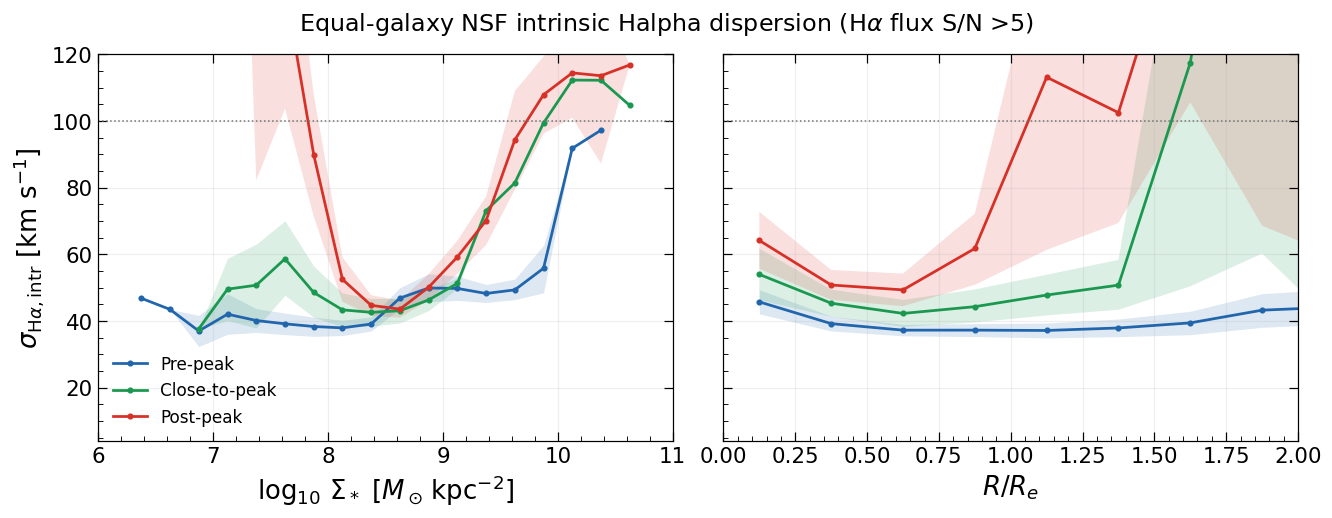

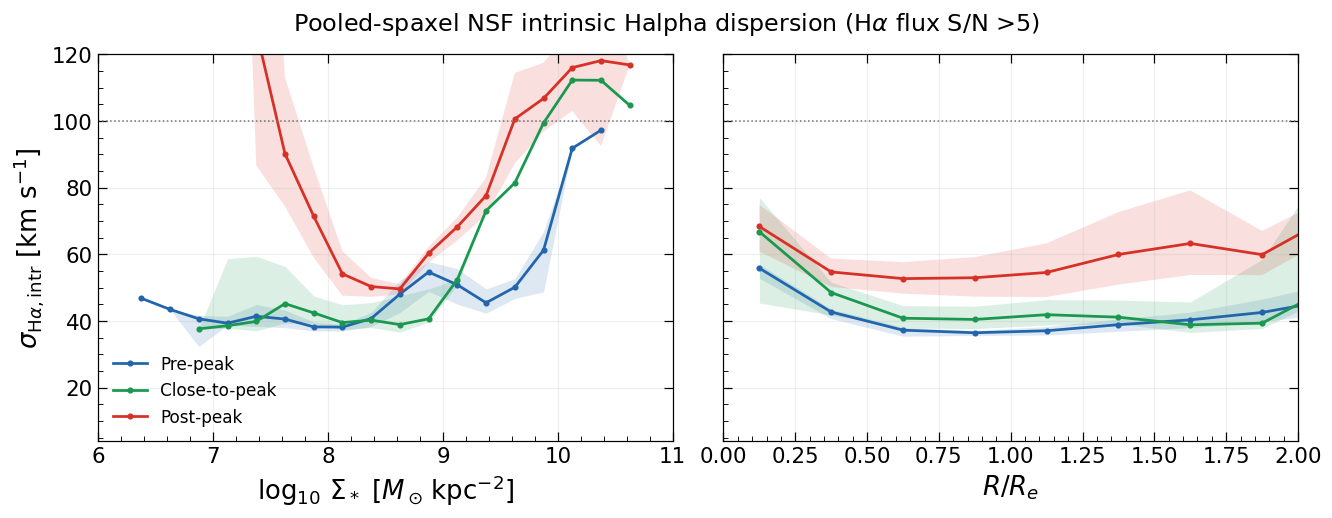

In [20]:
fraction_labels = {
    'log_sigma_star': r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]',
    'radius_re': r'$R/R_e$',
}
for branch in ('equal_galaxy', 'pooled_spaxel'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout='constrained')
    for ax, variable in zip(axes, ('log_sigma_star', 'radius_re')):
        for stage in (1, 2, 3):
            p = ha_snr5_profiles.loc[ha_snr5_profiles.branch.eq(branch) &
                ha_snr5_profiles.stage.eq(stage) & ha_snr5_profiles.variable.eq(variable)].sort_values('center')
            ax.plot(p.center, p.value, color=STAGE_COLORS[stage], marker='o', ms=3,
                lw=1.8, label=STAGE_LABELS[stage])
            ax.fill_between(p.center.to_numpy(float), p.lo.to_numpy(float), p.hi.to_numpy(float),
                color=STAGE_COLORS[stage], alpha=0.15, linewidth=0)
        ax.axhline(HIGH_SIGMA_LIMIT, color='0.45', ls=':', lw=1)
        ax.set_xlim(PROFILE_X_LIMITS[variable])  # display only; full-range statistics retained
        ax.set_ylim(top=120)  # display cap only; no extra data cut
        ax.set_xlabel(fraction_labels[variable])
        ax.tick_params(top=True, right=True)
        ax.minorticks_on(); ax.grid(alpha=0.2)
    axes[0].set_ylabel(r'$\sigma_{\mathrm{H}\alpha,\mathrm{intr}}$ [km s$^{-1}$]')
    axes[0].legend(frameon=False)
    label = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
    fig.suptitle(label + r' NSF intrinsic Halpha dispersion (H$\alpha$ flux S/N >5)')
    save_figure(fig, 'NSF_intrinsic_Halpha_dispersion_Ha_flux_snr_gt5_' + branch)
    plt.show(); plt.close(fig)

## Repeat cell 8 with Halpha Flux/Flux_err >10

Independently select original finite-dispersion NSF spaxels with
**HA6562_FLUX / HA6562_FLUX_ERR >10**, using the stored raw gas-fit flux
and its matching error. Both inputs must be finite and the error strictly positive;
the ratio must also be finite. Equality fails the strict threshold. This is an
**Halpha flux S/N selection**, not a direct residual-based fit-goodness statistic.
No 135, 225 or 450 km/s dispersion ceiling is applied in this case.

Retain the original inclination <80, SNR_POSTFIT >25, SF/ND/NSF classification,
geometry and full-range profile bins (no mass or radius range cut). The >=50 common usable-pixel support gate stays fixed;
recompute the >=20 retained diagnostic-pixel gate, equal-galaxy and pooled means,
and 10,000 whole-galaxy bootstrap intervals after the flux S/N cut. Unsupported
bins stay NaN. The plot y-axis retains the current 80 km/s display cap; this
does not exclude pixels or truncate computed profiles.

Report counts and removed fractions relative to the original finite NSF dispersion
sample, per galaxy, stage and overall. Also report the separate bounded regions
**7.5 <= log10 Sigma_star <8** and **1 < R/R_e <=1.5**, each with its own pre-cut
denominator. These overlapping region counts must not be added. This selection
is independent of all preceding dispersion-ceiling cases and the other Halpha
flux S/N threshold. Earlier sections remain unchanged.

In [21]:
HA_FLUX_SNR_MIN_10 = 10.0  # strict Halpha flux/error threshold
ha_snr10_rows, ha_snr10_count_rows, ha_snr10_region_count_rows = [], [], []
for record in inventory.loc[inventory.status.eq('included')].itertuples(index=False):
    gal = record.galaxy
    m, mh = read_map(record.mass, 'LOGMASS_SURFACE_DENSITY')
    ewh, eh = read_map(record.ew, 'PROXY_EWHA')
    snr, sh = read_map(record.sfh, 'SNR_POSTFIT')
    with fits.open(record.gas, memmap=True) as hdul:
        gh = hdul[0].header.copy()
        bin_header = hdul['BIN_ID'].header.copy()
        gas = {key: np.array(hdul[key].data, dtype=float) for key in (
            'BIN_ID', 'LOGSFR_SURFACE_DENSITY_HII', 'HA6562_SIGMA', 'HA6562_SIGMA_CORR',
            'HA6562_FLUX', 'HA6562_FLUX_ERR', 'HB4861_FLUX', 'HB4861_FLUX_ERR')}
    assert all(a.shape == m.shape for a in (ewh, snr, *gas.values()))
    for other, label in ((eh, 'EW'), (sh, 'SFH'), (bin_header, 'gas')):
        check_wcs(mh, other, m.shape, gal + ' Halpha flux S/N profile ' + label)
    with fits.open(record.mask) as hdul:
        smask = np.asarray(hdul['MASKFILE'].data['MASK']).reshape(m.shape)
    usable = np.isfinite(m) & np.isfinite(gas['BIN_ID']) & (smask == 0) & np.isfinite(snr) & (snr > SNR_POSTFIT_MIN)
    rad = calculate_deprojected_radius(m.shape, mh, geometry.loc[geometry.notebook_product_id.eq(gal)])
    assert np.isfinite(rad[usable]).all()
    detected = np.ones(m.shape, dtype=bool)
    for line in ('HA6562', 'HB4861'):
        flux, err = gas[line+'_FLUX'], gas[line+'_FLUX_ERR']
        with np.errstate(divide='ignore', invalid='ignore'):
            detected &= np.isfinite(flux) & np.isfinite(err) & (err > 0) & (flux/err >= float(gh['CUT_SN'])) & (flux >= float(gh['NOISE']))
    radicand = gas['HA6562_SIGMA']**2 - gas['HA6562_SIGMA_CORR']**2
    intrinsic = np.sqrt(np.where(np.isfinite(radicand) & (radicand > 0), radicand, np.nan))
    is_sf = usable & np.isfinite(gas['LOGSFR_SURFACE_DENSITY_HII']) & np.isfinite(ewh) & (ewh > EW_MIN) & np.isfinite(intrinsic) & (intrinsic < SIGMA_MAX)
    is_nd = usable & ~detected
    original_sigma = usable & ~is_sf & ~is_nd & np.isfinite(intrinsic)
    ha_flux, ha_error = gas['HA6562_FLUX'], gas['HA6562_FLUX_ERR']
    ha_ratio_inputs_ok = np.isfinite(ha_flux) & np.isfinite(ha_error) & (ha_error > 0)
    with np.errstate(divide='ignore', invalid='ignore', over='ignore'):
        ha_flux_snr = np.divide(ha_flux, ha_error, out=np.full(m.shape, np.nan), where=ha_ratio_inputs_ok)
    ha_line_snr_pass = ha_ratio_inputs_ok & np.isfinite(ha_flux_snr) & (ha_flux_snr > HA_FLUX_SNR_MIN_10)
    kept_sigma = original_sigma & ha_line_snr_pass
    removed_sigma = original_sigma & ~ha_line_snr_pass
    assert np.array_equal(original_sigma, kept_sigma | removed_sigma)
    assert (intrinsic[kept_sigma] > 0).all() and (ha_flux_snr[kept_sigma] > HA_FLUX_SNR_MIN_10).all()
    assert np.isfinite(ha_flux_snr[kept_sigma]).all() and (ha_error[kept_sigma] > 0).all()
    expected = counts.set_index('galaxy').loc[gal]
    assert original_sigma.sum() == expected.N_sigma and usable.sum() == expected.usable
    ha_snr10_count_rows.append(dict(galaxy=gal, stage=int(record.stage),
        N_original=int(original_sigma.sum()), N_retained=int(kept_sigma.sum()), N_removed=int(removed_sigma.sum()), max_retained_sigma=float(intrinsic[kept_sigma].max()) if kept_sigma.any() else np.nan))
    for region, region_mask in dispersion_region_masks(m, rad, original_sigma).items():
        retained = region_mask & ha_line_snr_pass
        removed = region_mask & ~ha_line_snr_pass
        assert np.array_equal(region_mask, retained | removed)
        ha_snr10_region_count_rows.append(dict(galaxy=gal, stage=int(record.stage), region=region,
            N_original=int(region_mask.sum()), N_retained=int(retained.sum()), N_removed=int(removed.sum())))
    for variable, values in (('log_sigma_star', m), ('radius_re', rad)):
        edges = FRACTION_EDGES[variable]
        window = np.isfinite(values)  # no mass/radius range cut
        nv, _ = np.histogram(values[usable & window], bins=edges)
        nb, _ = np.histogram(values[original_sigma & window], bins=edges)
        nc, _ = np.histogram(values[kept_sigma & window], bins=edges)
        totals, _ = np.histogram(values[kept_sigma & window], bins=edges, weights=intrinsic[kept_sigma & window])
        previous = nsf_extra_by_galaxy.loc[nsf_extra_by_galaxy.galaxy.eq(gal) &
            nsf_extra_by_galaxy.variable.eq(variable)].sort_values('left')
        assert np.array_equal(nv, previous.N_valid) and np.array_equal(nb, previous.N_diag)
        assert np.all(nc <= nb) and nc.sum() == (kept_sigma & window).sum()
        for j, (lo, hi) in enumerate(zip(edges[:-1], edges[1:])):
            ha_snr10_rows.append(dict(galaxy=gal, stage=int(record.stage), variable=variable,
                diagnostic='sigma_Ha_intrinsic', left=lo, right=hi, center=(lo+hi)/2,
                N_valid=int(nv[j]), N_diag=int(nc[j]), sum_primary=float(totals[j]),
                mean_primary=float(totals[j]/nc[j]) if nc[j] else np.nan,
                supported=bool(nv[j] >= FRACTION_MIN_USABLE and nc[j] >= NSF_EXTRA_MIN_PIXELS)))
ha_snr10_by_galaxy = pd.DataFrame(ha_snr10_rows)
ha_snr10_counts = pd.DataFrame(ha_snr10_count_rows)
assert (ha_snr10_counts.N_original == ha_snr10_counts.N_retained + ha_snr10_counts.N_removed).all()
ha_snr10_count_columns = ['N_original', 'N_retained', 'N_removed']
ha_snr10_stage_counts = ha_snr10_counts.groupby('stage')[ha_snr10_count_columns].sum()
ha_snr10_total_counts = pd.DataFrame([ha_snr10_counts[ha_snr10_count_columns].sum()], index=['All stages'])
for summary in (ha_snr10_counts, ha_snr10_stage_counts, ha_snr10_total_counts):
    summary['fraction_removed'] = np.divide(
        summary.N_removed.to_numpy(float), summary.N_original.to_numpy(float),
        out=np.full(len(summary), np.nan), where=summary.N_original.to_numpy(float) > 0)
    assert (summary.N_original == summary.N_retained + summary.N_removed).all()
    assert summary.fraction_removed.dropna().between(0, 1).all()
print('Removed: Halpha Flux/Flux_err fails strict >10 (including invalid ratio inputs). Fraction = N_removed / N_original.')
print('Denominator: finite NSF dispersion pixels before the cut, across each full galaxy footprint; with no mass or radius range cut.')
for label, summary in (
    ('Per galaxy', ha_snr10_counts),
    ('Per stage (1=pre-peak, 2=close-to-peak, 3=post-peak)', ha_snr10_stage_counts),
    ('Overall (pooled pixel counts)', ha_snr10_total_counts),
):
    print(label)
    display(summary.style.format({**{key: '{:,.0f}' for key in ha_snr10_count_columns},
        'fraction_removed': '{:.4%}'}, na_rep='--'))

ha_snr10_region_counts = pd.DataFrame(ha_snr10_region_count_rows)
ha_snr10_region_stage_counts = ha_snr10_region_counts.groupby(['region', 'stage'])[ha_snr10_count_columns].sum()
ha_snr10_region_total_counts = ha_snr10_region_counts.groupby('region')[ha_snr10_count_columns].sum()
for summary in (ha_snr10_region_counts, ha_snr10_region_stage_counts, ha_snr10_region_total_counts):
    summary['fraction_removed'] = np.divide(
        summary.N_removed.to_numpy(float), summary.N_original.to_numpy(float),
        out=np.full(len(summary), np.nan), where=summary.N_original.to_numpy(float) > 0)
    assert (summary.N_original == summary.N_retained + summary.N_removed).all()
    assert summary.fraction_removed.dropna().between(0, 1).all()
print('Bounded regions: 7.5 <= log10 Sigma_star <8; 1 < R/R_e <=1.5. Each fraction uses its own region before the sigma cut.')
for label, summary in (
    ('Bounded regions: per galaxy', ha_snr10_region_counts),
    ('Bounded regions: per stage', ha_snr10_region_stage_counts),
    ('Bounded regions: overall, pooled pixel counts', ha_snr10_region_total_counts),
):
    print(label)
    display(summary.style.format({**{key: '{:,.0f}' for key in ha_snr10_count_columns},
        'fraction_removed': '{:.4%}'}, na_rep='--'))


Removed: Halpha Flux/Flux_err fails strict >10 (including invalid ratio inputs). Fraction = N_removed / N_original.
Denominator: finite NSF dispersion pixels before the cut, across each full galaxy footprint; with no mass or radius range cut.
Per galaxy


,galaxy,stage,N_original,N_retained,N_removed,max_retained_sigma,fraction_removed
0,IC3392,3,"9,123","9,123",0,330.281875,0.0000%
1,NGC4064,3,"33,921","33,910",11,325.219883,0.0324%
2,NGC4189,1,"34,012","34,012",0,85.726358,0.0000%
3,NGC4254,1,"163,358","163,358",0,114.219780,0.0000%
4,NGC4293,3,"63,400","61,880","1,520",1000.000000,2.3975%
5,NGC4294,1,"51,426","51,426",0,58.475654,0.0000%
6,NGC4298,2,"43,104","43,104",0,81.034313,0.0000%
7,NGC4321,1,"329,655","329,655",0,281.276707,0.0000%
8,NGC4351,1,"16,682","16,682",0,48.777238,0.0000%
9,NGC4380,3,"51,190","51,190",0,194.850923,0.0000%


Per stage (1=pre-peak, 2=close-to-peak, 3=post-peak)


,N_original,N_retained,N_removed,fraction_removed
stage,,,,
1,"929,104","929,104",0,0.0000%
2,"488,865","487,993",872,0.1784%
3,"815,887","811,311","4,576",0.5609%


Overall (pooled pixel counts)


...

Bounded regions: 7.5 <= log10 Sigma_star <8; 1 < R/R_e <=1.5. Each fraction uses its own region before the sigma cut.
Bounded regions: per galaxy


,galaxy,stage,region,N_original,N_retained,N_removed,fraction_removed
0,IC3392,3,logSigmaStar_7p5_to_8,"2,158","2,158",0,0.0000%
1,IC3392,3,R_over_Re_1_to_1p5,"1,996","1,996",0,0.0000%
2,NGC4064,3,logSigmaStar_7p5_to_8,"9,669","9,669",0,0.0000%
3,NGC4064,3,R_over_Re_1_to_1p5,"1,130","1,130",0,0.0000%
4,NGC4189,1,logSigmaStar_7p5_to_8,"14,327","14,327",0,0.0000%
5,NGC4189,1,R_over_Re_1_to_1p5,"6,422","6,422",0,0.0000%
6,NGC4254,1,logSigmaStar_7p5_to_8,"81,313","81,313",0,0.0000%
7,NGC4254,1,R_over_Re_1_to_1p5,"51,508","51,508",0,0.0000%
8,NGC4293,3,logSigmaStar_7p5_to_8,"5,468","5,119",349,6.3826%
9,NGC4293,3,R_over_Re_1_to_1p5,"4,511","3,717",794,17.6014%


Bounded regions: per stage


Bounded regions: overall, pooled pixel counts


,N_original,N_retained,N_removed,fraction_removed
region,,,,
R_over_Re_1_to_1p5,"520,224","518,602","1,622",0.3118%
logSigmaStar_7p5_to_8,"649,065","647,053","2,012",0.3100%


In [22]:
assert (ha_snr10_by_galaxy.N_diag<=ha_snr10_by_galaxy.N_valid).all()
assert np.array_equal(ha_snr10_by_galaxy.supported,
    (ha_snr10_by_galaxy.N_valid>=FRACTION_MIN_USABLE)&(ha_snr10_by_galaxy.N_diag>=NSF_EXTRA_MIN_PIXELS))
ha_snr10_profile_rows=[]
for stage in (1,2,3):
    galaxy_ids=counts.loc[counts.stage.eq(stage),'galaxy'].sort_values().to_numpy()
    g=len(galaxy_ids)
    for branch,seed_base in [('equal_galaxy',15_000_000),('pooled_spaxel',16_000_000)]:
        extra_rng=np.random.default_rng(RANDOM_SEED+seed_base+100_000*(stage-1))
        draw=extra_rng.integers(0,g,size=(NSF_EXTRA_N_BOOTSTRAP,g))
        for variable,bin_edges in FRACTION_EDGES.items():
            for diagnostic in NSF_EXTRA_DIAGNOSTICS:
                for lo,hi in zip(bin_edges[:-1],bin_edges[1:]):
                    panel=ha_snr10_by_galaxy.loc[ha_snr10_by_galaxy.stage.eq(stage)&
                        ha_snr10_by_galaxy.variable.eq(variable)&ha_snr10_by_galaxy.diagnostic.eq(diagnostic)&
                        np.isclose(ha_snr10_by_galaxy.left,lo)].set_index('galaxy').reindex(galaxy_ids)
                    assert panel.N_diag.notna().all()
                    support=panel.supported.to_numpy(bool)
                    paired=diagnostic=='SII_doublet'
                    fields=['primary','secondary'] if paired else ['primary']
                    if branch=='equal_galaxy':
                        values=np.column_stack([panel['mean_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,np.nan)
                        denominator=support[draw].sum(axis=1)
                        boot=np.divide(np.nansum(values[draw],axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=np.mean(values[support],axis=0) if support.any() else np.full(len(fields),np.nan)
                    else:
                        values=np.column_stack([panel['sum_'+field].to_numpy(float) for field in fields])
                        values=np.where(support[:,None],values,0.)
                        pixel_counts=np.where(support,panel.N_diag.to_numpy(float),0.)
                        denominator=pixel_counts[draw].sum(axis=1)
                        boot=np.divide(values[draw].sum(axis=1),denominator[:,None],
                            out=np.full((NSF_EXTRA_N_BOOTSTRAP,len(fields)),np.nan),where=denominator[:,None]>0)
                        central=values.sum(axis=0)/pixel_counts.sum() if pixel_counts.sum()>0 else np.full(len(fields),np.nan)
                    finite=denominator>0
                    assert np.isfinite(boot[finite]).all()
                    if paired:
                        assert (boot[finite]>0).all()
                        draws=boot[finite,0]/boot[finite,1]
                        value=central[0]/central[1] if support.any() else np.nan
                        if branch=='pooled_spaxel' and support.any():
                            assert np.isclose(value,panel.loc[panel.supported,'sum_primary'].sum()/panel.loc[panel.supported,'sum_secondary'].sum(),rtol=1e-12)
                    else:
                        draws=boot[finite,0]
                        value=central[0]
                        if branch=='pooled_spaxel' and support.any():
                            direct=np.sum(panel.loc[panel.supported,'mean_primary']*panel.loc[panel.supported,'N_diag'])/panel.loc[panel.supported,'N_diag'].sum()
                            assert np.isclose(value,direct,rtol=1e-12,atol=1e-12)
                    low,high=np.percentile(draws,[16,84]) if len(draws) else (np.nan,np.nan)
                    ha_snr10_profile_rows.append(dict(branch=branch,stage=stage,variable=variable,diagnostic=diagnostic,
                        left=lo,right=hi,center=(lo+hi)/2,N_gal_support=int(support.sum()),
                        N_spaxel_support=int(panel.loc[panel.supported,'N_diag'].sum()),
                        N_finite_draws=int(finite.sum()),value=value,lo=low,hi=high))
ha_snr10_profiles=pd.DataFrame(ha_snr10_profile_rows)
assert len(ha_snr10_profiles)==2*3*sum(len(edges)-1 for edges in FRACTION_EDGES.values())*len(NSF_EXTRA_DIAGNOSTICS)
supported=ha_snr10_profiles.N_gal_support.gt(0)
assert np.isfinite(ha_snr10_profiles.loc[supported,['value','lo','hi']]).all().all()
assert (ha_snr10_profiles.loc[supported,'lo']<=ha_snr10_profiles.loc[supported,'hi']).all()
assert ha_snr10_profiles.N_finite_draws.le(NSF_EXTRA_N_BOOTSTRAP).all()
positive=supported&ha_snr10_profiles.diagnostic.isin(['sigma_Ha_intrinsic','SII_doublet'])
assert (ha_snr10_profiles.loc[positive,['value','lo','hi']]>0).all().all()
display(ha_snr10_profiles)
print('Halpha Flux/Flux_err >10: support, pooled reconstruction and bootstrap checks passed; no dispersion ceiling applied')

,branch,stage,variable,diagnostic,left,right,center,N_gal_support,N_spaxel_support,N_finite_draws,value,lo,hi
0,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,5.75,6.00,5.875,0,0,0,NaN,NaN,NaN
1,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.00,6.25,6.125,0,0,0,NaN,NaN,NaN
2,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.25,6.50,6.375,1,443,6585,46.806609,46.806609,46.806609
3,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.50,6.75,6.625,1,1007,6585,43.460349,43.460349,43.460349
4,equal_galaxy,1,log_sigma_star,sigma_Ha_intrinsic,6.75,7.00,6.875,2,10281,9011,36.988530,32.312368,41.664691
...,...,...,...,...,...,...,...,...,...,...,...,...,...
421,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.00,11.25,11.125,0,0,0,NaN,NaN,NaN
422,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.25,11.50,11.375,0,0,0,NaN,NaN,NaN
423,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.50,11.75,11.625,0,0,0,NaN,NaN,NaN
424,pooled_spaxel,3,radius_re,sigma_Ha_intrinsic,11.75,12.00,11.875,0,0,0,NaN,NaN,NaN


Halpha Flux/Flux_err >10: support, pooled reconstruction and bootstrap checks passed; no dispersion ceiling applied


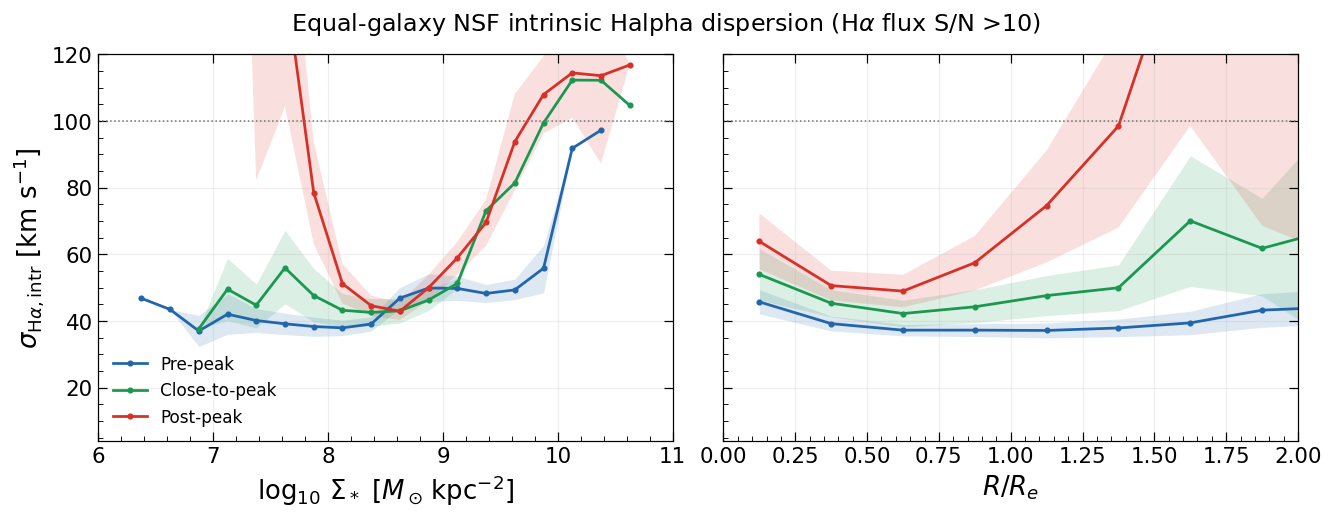

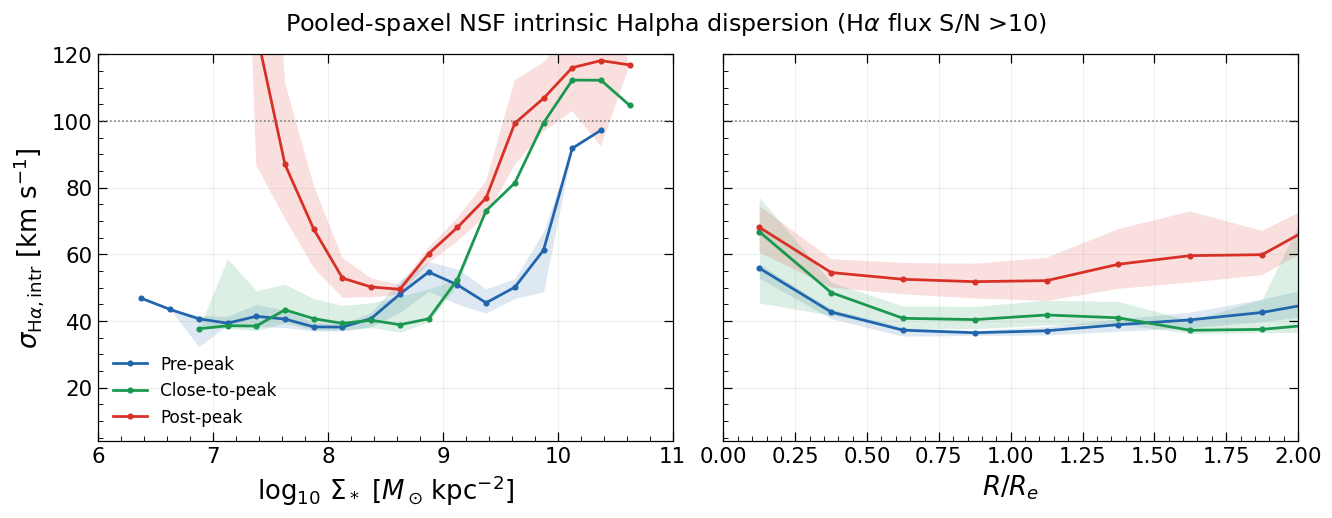

In [23]:
fraction_labels = {
    'log_sigma_star': r'$\log_{10}\,\Sigma_*$ [$M_\odot\,{\rm kpc}^{-2}$]',
    'radius_re': r'$R/R_e$',
}
for branch in ('equal_galaxy', 'pooled_spaxel'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True, layout='constrained')
    for ax, variable in zip(axes, ('log_sigma_star', 'radius_re')):
        for stage in (1, 2, 3):
            p = ha_snr10_profiles.loc[ha_snr10_profiles.branch.eq(branch) &
                ha_snr10_profiles.stage.eq(stage) & ha_snr10_profiles.variable.eq(variable)].sort_values('center')
            ax.plot(p.center, p.value, color=STAGE_COLORS[stage], marker='o', ms=3,
                lw=1.8, label=STAGE_LABELS[stage])
            ax.fill_between(p.center.to_numpy(float), p.lo.to_numpy(float), p.hi.to_numpy(float),
                color=STAGE_COLORS[stage], alpha=0.15, linewidth=0)
        ax.axhline(HIGH_SIGMA_LIMIT, color='0.45', ls=':', lw=1)
        ax.set_xlim(PROFILE_X_LIMITS[variable])  # display only; full-range statistics retained
        ax.set_ylim(top=120)  # display cap only; no extra data cut
        ax.set_xlabel(fraction_labels[variable])
        ax.tick_params(top=True, right=True)
        ax.minorticks_on(); ax.grid(alpha=0.2)
    axes[0].set_ylabel(r'$\sigma_{\mathrm{H}\alpha,\mathrm{intr}}$ [km s$^{-1}$]')
    axes[0].legend(frameon=False)
    label = 'Equal-galaxy' if branch == 'equal_galaxy' else 'Pooled-spaxel'
    fig.suptitle(label + r' NSF intrinsic Halpha dispersion (H$\alpha$ flux S/N >10)')
    save_figure(fig, 'NSF_intrinsic_Halpha_dispersion_Ha_flux_snr_gt10_' + branch)
    plt.show(); plt.close(fig)